# Hotel Booking Cancellation: Model Development


## 1. Setup


### 1.1 Imports


In [1]:
# Import standard Python utilities
from pathlib import Path
import json
import sys

# Import data inspection and Spark packages
import pandas as pd
import pyspark
from IPython.display import display

# Display the active notebook environment
print('Python version:', sys.version.split()[0])
print('Pandas version:', pd.__version__)


Python version: 3.12.15
Pandas version: 2.2.3


### 1.2 Set Up PySpark Session


In [2]:
# Initialize SparkSession
spark = (pyspark.sql.SparkSession.builder
         .appName('hotel_model_development')
         .master('local[2]')
         .getOrCreate())

# Keep Spark logging focused on errors
spark.sparkContext.setLogLevel('ERROR')
print('Spark version:', spark.version)


Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/10/21 20:50:36 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Spark version: 3.5.5


### 1.3 Set Up Config


In [3]:
# Locate Project from the notebook directory or one of its parents
def find_project_root(start):
    for candidate in (start, *start.parents):
        gold_directory = (candidate / 'Data pipeline'
                          / 'hotel_booking_pipeline' / 'datamart' / 'gold')
        if gold_directory.is_dir():
            return candidate
    raise FileNotFoundError('Run with the Project folder and sibling Data pipeline accessible.')


# Define sources relative to the shared Project folder
project_root = find_project_root(Path.cwd().resolve())
gold_root = (project_root / 'Data pipeline'
             / 'hotel_booking_pipeline' / 'datamart' / 'gold')

# Define source paths and hotel identifiers
config = {
    'hotels': ('H1', 'H2'),
    'booking_key': 'Booking_ID',
    'target': 'IsCanceled',
    'gold_root': gold_root,
    'contract_path': gold_root / 'feature_contract.json',
    'model_directory': gold_root / 'model_dataset',
    'label_directory': gold_root / 'labels',
}

# Confirm the supplied source locations before reading
for name in ('contract_path', 'model_directory', 'label_directory'):
    if not config[name].exists():
        raise FileNotFoundError(config[name])
print('Project root:', project_root)
print('Gold root:', config['gold_root'])
print('Hotels:', ', '.join(config['hotels']))


Project root: /workspace/Project
Gold root: /workspace/Project/Data pipeline/hotel_booking_pipeline/datamart/gold
Hotels: H1, H2


## 2. Load Gold


### 2.1 Read Model Datasets and Label Stores

Model datasets contain the predictors and target. Label stores supply `ReservationStatus` and `ReservationStatusDate` as metadata for label availability.


In [4]:
# Read the feature contract supplied with Gold
contract = json.loads(config['contract_path'].read_text(encoding='utf-8'))

# Map the two required input tables to their source directories
table_sources = {
    'model': (config['model_directory'], 'gold_model_dataset'),
    'labels': (config['label_directory'], 'gold_label_store'),
}
gold_tables = {}
source_rows = []

# Read each complete Parquet directory with Spark, then collect for modelling
for hotel in config['hotels']:
    gold_tables[hotel] = {}
    for role, (directory, stem) in table_sources.items():
        source_path = directory / f'{stem}_{hotel}.parquet'
        if not source_path.is_dir():
            raise FileNotFoundError(source_path)
        spark_table = spark.read.parquet(str(source_path))
        gold_tables[hotel][role] = spark_table.toPandas()
        source_rows.append({
            'Hotel': hotel, 'Table': role,
            'Rows': len(gold_tables[hotel][role]),
            'Columns': len(spark_table.columns),
        })

# Show the handoff sizes without changing any Gold values
source_report = pd.DataFrame(source_rows)
display(source_report)


,Hotel,Table,Rows,Columns
0,H1,model,20140,41
1,H1,labels,20140,5
2,H2,model,38233,41
3,H2,labels,38233,5


**Observation:** Model datasets and label stores have matching row counts for each hotel.


### 2.2 Join Outcome Metadata


In [5]:
# Attach final status and status date metadata
model_data = {}
loaded_data_rows = []
for hotel in config['hotels']:
    model = gold_tables[hotel]['model']
    outcome_metadata = gold_tables[hotel]['labels'][
        ['Booking_ID', 'ReservationStatus', 'ReservationStatusDate']
    ]
    loaded = model.merge(
        outcome_metadata, on='Booking_ID', how='left', validate='one_to_one'
    )

    # Use consistent date representations for later chronological comparisons
    for column in ('ArrivalDate', 'BookingCreatedDate', 'CutoffDate', 'FXObservationDate',
                   'TrendWeekStart', 'TrendWeekEnd', 'TrendAvailableDate',
                   'ReservationStatusDate'):
        loaded[column] = pd.to_datetime(loaded[column], errors='raise')

    # Confirm that the metadata join preserved every booking
    if len(loaded) != len(model) or not loaded['Booking_ID'].is_unique:
        raise ValueError(f'{hotel}: outcome metadata join changed the modelling grain.')
    model_data[hotel] = loaded
    loaded_data_rows.append({
        'Hotel': hotel, 'Loaded bookings': len(loaded),
        'Columns including outcome metadata': len(loaded.columns),
        'Positive labels': int(loaded['IsCanceled'].sum()),
        'First CutoffDate': loaded['CutoffDate'].min().date(),
        'Last CutoffDate': loaded['CutoffDate'].max().date(),
    })

# Summarize the loaded modelling tables
loaded_data_report = pd.DataFrame(loaded_data_rows)
with pd.option_context('display.max_columns', None):
    display(loaded_data_report)


,Hotel,Loaded bookings,Columns including outcome metadata,Positive labels,First CutoffDate,Last CutoffDate
0,H1,20140,43,1518,2015-06-17,2017-08-17
1,H2,38233,43,4536,2015-06-17,2017-08-17


**Observation:** The metadata joins preserved all Gold bookings. Each loaded table has 43 columns: the 41 supplied columns plus final status and status date. These two added fields remain metadata, excluded from predictors.


## 3. Data Split

### 3.1 Split Config

In [6]:
# Reload the split utility after editing its implementation
import importlib
import utils.model_split as model_split

importlib.reload(model_split)

# Define the shared chronological calendar
split_config = {
    'split_column': 'CutoffDate',
    'first_fit_date': '2016-07-01',
    'validation_months': 2,
    'n_folds': 4,
    'test_start': '2017-04-18',
    'test_end': '2017-08-18',
}

### 3.2 Create H1 and H2 Memberships

In [7]:
# Keep copies to verify that splitting preserves the inputs
model_data_before_split = {
    hotel: model_data[hotel].copy(deep=True) for hotel in config['hotels']
}
config_before_split = split_config.copy()

# Apply the same split function and calendar separately to each hotel
split_results = {}
for hotel in config['hotels']:
    split_results[hotel] = model_split.make_splits(model_data[hotel], split_config)

### 3.3 Check Date Boundaries and Repeated Eligibility

In [8]:
# Build a small fixture with deliberately chosen boundary dates
fixture = pd.DataFrame([
    ['checkout_early', '2016-05-01', 'Check-Out', '2016-05-15', 0],
    ['checkout_late', '2016-05-03', 'Check-Out', '2016-05-30', 0],
    ['label_on_fit', '2016-06-01', 'Canceled', '2016-07-01', 1],
    ['label_on_fold2', '2016-06-15', 'Canceled', '2016-09-01', 1],
    ['cutoff_on_fit', '2016-07-01', 'Canceled', '2016-07-05', 1],
    ['march_booking', '2017-03-01', 'Canceled', '2017-04-01', 1],
    ['label_on_refit', '2017-04-01', 'Canceled', '2017-04-18', 1],
    ['test_start', '2017-04-18', 'No-Show', '2017-05-02', 1],
    ['test_last_day', '2017-08-17', 'No-Show', '2017-08-31', 1],
], columns=['Booking_ID', 'CutoffDate', 'ReservationStatus',
            'ReservationStatusDate', 'IsCanceled'])
fixture['Hotel'] = 'Example'
fixture['CutoffDate'] = pd.to_datetime(fixture['CutoffDate'])
fixture['ArrivalDate'] = fixture['CutoffDate'] + pd.Timedelta(days=14)
fixture['TotalNights'] = 2
fixture_before = fixture.copy(deep=True)
fixture_result = model_split.make_splits(fixture, split_config)

# Record failed checks with at most five booking IDs
split_checks = []

def record_split_check(name, passed, sample_ids=()):
    split_checks.append({
        'Check': name, 'Passed': bool(passed),
        'Sample IDs': ', '.join(map(str, list(sample_ids)[:5])),
    })

def compare_membership(name, actual_ids, expected_ids):
    actual = list(actual_ids)
    expected = set(expected_ids)
    difference = set(actual).symmetric_difference(expected)
    duplicates = pd.Series(actual, dtype='object')
    duplicates = duplicates[duplicates.duplicated()].tolist()
    record_split_check(
        name, not difference and not duplicates,
        sorted(difference) + duplicates,
    )

# Check both sides of the Check-Out maximum-date rule
availability = (fixture_result['fit_eligibility']
                .drop_duplicates('Booking_ID')
                .set_index('Booking_ID')['LabelAvailableDate'])
record_split_check('Check-Out uses expected checkout when later',
                   availability['checkout_early'] == pd.Timestamp('2016-05-17'))
record_split_check('Check-Out uses status date when later',
                   availability['checkout_late'] == pd.Timestamp('2016-05-30'))

# Check strict eligibility and re-evaluation at later folds
fixture_cv = fixture_result['cv_membership']
for fold, expected_ids in [
    (1, ['checkout_early', 'checkout_late']),
    (2, ['checkout_early', 'checkout_late', 'label_on_fit', 'cutoff_on_fit']),
    (3, ['checkout_early', 'checkout_late', 'label_on_fit',
         'cutoff_on_fit', 'label_on_fold2']),
]:
    actual_ids = fixture_cv.loc[
        fixture_cv['Fold'].eq(fold) & fixture_cv['Role'].eq('Train'), 'Booking_ID'
    ]
    compare_membership(f'Example fold {fold}: eligible train', actual_ids, expected_ids)
compare_membership(
    'Cutoff on fit date belongs to validation',
    fixture_cv.loc[fixture_cv['Fold'].eq(1) & fixture_cv['Role'].eq('Validation'),
                   'Booking_ID'], ['cutoff_on_fit'],
)
compare_membership(
    'Test includes its first and last observed day',
    fixture_result['partition_membership'].query("Partition == 'Test'")['Booking_ID'],
    ['test_start', 'test_last_day'],
)
compare_membership(
    'Refit includes March but excludes labels dated on refit',
    fixture_result['refit_membership']['Booking_ID'],
    ['checkout_early', 'checkout_late', 'label_on_fit',
     'cutoff_on_fit', 'label_on_fold2', 'march_booking'],
)

# Check input preservation and deterministic membership after reordering
pd.testing.assert_frame_equal(fixture, fixture_before)
reordered = model_split.make_splits(fixture.sample(frac=1, random_state=611), split_config)
for name in ('partition_membership', 'cv_membership', 'fit_eligibility',
             'refit_membership', 'calibration_membership'):
    pd.testing.assert_frame_equal(fixture_result[name], reordered[name])
record_split_check('Inputs preserved and membership independent of input order', True)

# Reject an input at the exclusive test end instead of dropping it silently
outside = fixture.iloc[[0]].copy()
outside['CutoffDate'] = pd.Timestamp(split_config['test_end'])
try:
    model_split.make_splits(outside, split_config)
except ValueError as error:
    record_split_check('Reject rows outside the configured calendar',
                       'outside the configured test end' in str(error))
else:
    record_split_check('Reject rows outside the configured calendar', False)

# Reject missing dates even when they arrive as non-null strings
missing_date = fixture.iloc[[0]].copy()
missing_date['ReservationStatusDate'] = 'NaT'
try:
    model_split.make_splits(missing_date, split_config)
except ValueError as error:
    record_split_check('Reject dates parsed as NaT', 'missing dates' in str(error))
else:
    record_split_check('Reject dates parsed as NaT', False)

boundary_checks = pd.DataFrame(split_checks)
boundary_failures = boundary_checks.loc[~boundary_checks['Passed']]
if not boundary_failures.empty:
    display(boundary_failures.drop(columns='Passed'))
    raise AssertionError('Date-boundary checks failed')
print(f'Date rules — {len(boundary_checks)} checks passed')

Date rules — 11 checks passed


### 3.4 Audit H1 and H2 Splits

In [9]:
# Record EDA counts for the current Gold version
eda_reference = {
    'H1': {
        'cv': [
            [1, 9077, 8618, 719, 1779, 115, 459],
            [2, 10856, 10353, 825, 1936, 112, 503],
            [3, 12792, 12291, 945, 1152, 114, 501],
            [4, 13944, 13631, 1055, 1252, 119, 313],
        ],
        'partition': [[16564, 1269], [16019, 1250], [545, 19],
                      [6119, 460], [3576, 249]],
    },
    'H2': {
        'cv': [
            [1, 15188, 14230, 2185, 3805, 316, 958],
            [2, 18993, 17962, 2517, 3958, 534, 1031],
            [3, 22951, 22069, 3032, 2216, 293, 882],
            [4, 25167, 24605, 3350, 2359, 274, 562],
        ],
        'partition': [[30485, 3926], [29468, 3882], [1017, 44],
                      [12338, 1417], [7748, 610]],
    },
}

# Audit each hotel independently and retain every check result
audit_check_parts = []
for hotel in config['hotels']:
    split_result = split_results[hotel]
    # Recalculate expected dates directly from the loaded hotel data
    split_checks = []
    source = model_data[hotel].copy()
    split_column = split_config['split_column']
    refit_date = pd.Timestamp(split_config['test_start'])
    test_end = pd.Timestamp(split_config['test_end'])
    expected_checkout = source['ArrivalDate'] + pd.to_timedelta(source['TotalNights'], unit='D')
    source['LabelAvailableDate'] = source['ReservationStatusDate']
    checkout = source['ReservationStatus'].eq('Check-Out')
    source.loc[checkout, 'LabelAvailableDate'] = pd.concat(
        [source.loc[checkout, 'ReservationStatusDate'], expected_checkout.loc[checkout]], axis=1
    ).max(axis=1)
    development = source.loc[source[split_column].lt(refit_date)]
    test = source.loc[source[split_column].ge(refit_date) & source[split_column].lt(test_end)]
    partitions = split_result['partition_membership']
    cv = split_result['cv_membership']
    eligibility = split_result['fit_eligibility']
    refit_ids = split_result['refit_membership']['Booking_ID']
    calibration = split_result['calibration_membership']

    # Check complete partition assignment and unchanged source inputs
    compare_membership('Partition covers input once', partitions['Booking_ID'], source['Booking_ID'])
    for name, expected in [('Development', development), ('Test', test)]:
        compare_membership(f'{name} membership',
                           partitions.loc[partitions['Partition'].eq(name), 'Booking_ID'],
                           expected['Booking_ID'])
    record_split_check('Membership hotel keys match the selected hotel', all(
        split_result[name]['Hotel'].eq(hotel).all()
        for name in ('partition_membership', 'cv_membership', 'fit_eligibility',
                     'refit_membership', 'calibration_membership')
    ))
    pd.testing.assert_frame_equal(model_data[hotel], model_data_before_split[hotel])
    record_split_check('Source and config unchanged', split_config == config_before_split)

    # Compare every fold with independently filtered source rows
    validation_ids = []
    expected_cv_rows = []
    for fold in range(1, split_config['n_folds'] + 1):
        fit_date = pd.Timestamp(split_config['first_fit_date']) + pd.DateOffset(
            months=(fold - 1) * split_config['validation_months'])
        validation_end = fit_date + pd.DateOffset(months=split_config['validation_months'])
        candidates = development.loc[development[split_column].lt(fit_date)]
        expected_train = candidates.loc[candidates['LabelAvailableDate'].lt(fit_date)]
        expected_validation = development.loc[
            development[split_column].ge(fit_date) & development[split_column].lt(validation_end)
        ]
        train_ids = cv.loc[cv['Fold'].eq(fold) & cv['Role'].eq('Train'), 'Booking_ID']
        valid_ids = cv.loc[cv['Fold'].eq(fold) & cv['Role'].eq('Validation'), 'Booking_ID']
        compare_membership(f'Fold {fold}: eligible train', train_ids, expected_train['Booking_ID'])
        compare_membership(f'Fold {fold}: complete validation', valid_ids, expected_validation['Booking_ID'])
        record_split_check(f'Fold {fold}: train and validation disjoint',
                           not set(train_ids).intersection(valid_ids),
                           set(train_ids).intersection(valid_ids))
        fold_eligibility = eligibility.loc[
            eligibility['Stage'].eq('CV') & eligibility['Fold'].eq(fold).fillna(False)
        ]
        compare_membership(f'Fold {fold}: eligibility candidates',
                           fold_eligibility['Booking_ID'], candidates['Booking_ID'])
        compare_membership(f'Fold {fold}: eligibility agrees with train',
                           fold_eligibility.loc[fold_eligibility['Eligible'], 'Booking_ID'], train_ids)
        record_split_check(f'Fold {fold}: nonempty train and validation',
                           len(train_ids) > 0 and len(valid_ids) > 0)
        record_split_check(f'Fold {fold}: correct fit date',
                           cv.loc[cv['Fold'].eq(fold), 'FitDate'].eq(fit_date).all()
                           and fold_eligibility['FitDate'].eq(fit_date).all())
        record_split_check(f'Fold {fold}: validation labels ready before refit',
                           expected_validation['LabelAvailableDate'].lt(refit_date).all(),
                           expected_validation.loc[
                               expected_validation['LabelAvailableDate'].ge(refit_date), 'Booking_ID'])
        validation_ids.extend(valid_ids.tolist())
        expected_cv_rows.append([
            fold, len(candidates), len(expected_train), int(expected_train['IsCanceled'].sum()),
            len(expected_validation), int(expected_validation['IsCanceled'].sum()),
            len(candidates) - len(expected_train),
        ])

    # Check final refit, recorded dates and exclusion reasons
    expected_refit = development.loc[development['LabelAvailableDate'].lt(refit_date)]
    final_eligibility = eligibility.loc[eligibility['Stage'].eq('FinalRefit')]
    compare_membership('Final refit uses every eligible development row',
                       refit_ids, expected_refit['Booking_ID'])
    compare_membership('Final refit rechecks the complete development cohort',
                       final_eligibility['Booking_ID'], development['Booking_ID'])
    compare_membership('Final eligibility agrees with refit membership',
                       final_eligibility.loc[final_eligibility['Eligible'], 'Booking_ID'], refit_ids)
    record_split_check('Final refit date and nullable fold',
                       final_eligibility['FitDate'].eq(refit_date).all()
                       and final_eligibility['Fold'].isna().all()
                       and split_result['refit_membership']['FitDate'].eq(refit_date).all())
    recorded_dates = eligibility.merge(
        source[['Booking_ID', 'LabelAvailableDate']], on='Booking_ID',
        suffixes=('_recorded', '_expected'), validate='many_to_one')
    wrong_dates = recorded_dates['LabelAvailableDate_recorded'].ne(
        recorded_dates['LabelAvailableDate_expected'])
    record_split_check('Recorded label availability matches the agreed proxy',
                       not wrong_dates.any(), recorded_dates.loc[wrong_dates, 'Booking_ID'])
    wrong_reason = (
        eligibility['Eligible'] & eligibility['ExclusionReason'].ne('')
    ) | (~eligibility['Eligible'] & eligibility['ExclusionReason'].ne('Label not available before fit'))
    record_split_check('Exclusion reasons match eligibility', not wrong_reason.any(),
                       eligibility.loc[wrong_reason, 'Booking_ID'])

    # Check the unique calibration cohort and its fold and prediction dates
    compare_membership('Calibration is the unique union of validation rows',
                       calibration['Booking_ID'], validation_ids)
    expected_calibration = cv.loc[cv['Role'].eq('Validation'), ['Hotel', 'Booking_ID', 'Fold']]
    calibration_join = calibration.merge(
        expected_calibration, on=['Hotel', 'Booking_ID'], suffixes=('', '_expected'),
        how='outer', indicator=True)
    wrong_fold = (calibration_join['_merge'].ne('both')
                  | calibration_join['Fold'].ne(calibration_join['Fold_expected']))
    record_split_check('Calibration keeps the validation fold', not wrong_fold.any(),
                       calibration_join.loc[wrong_fold, 'Booking_ID'])
    prediction_dates = calibration.merge(
        source[['Booking_ID', split_column]], on='Booking_ID', validate='one_to_one')
    wrong_prediction_date = prediction_dates['PredictionDate'].ne(prediction_dates[split_column])
    record_split_check('Calibration prediction dates equal CutoffDate',
                       not wrong_prediction_date.any(),
                       prediction_dates.loc[wrong_prediction_date, 'Booking_ID'])

    # Reconcile utility summaries and the saved EDA reference for this Gold version
    cv_columns = ['Fold', 'TrainCandidates', 'TrainRows', 'TrainPositives',
                  'ValidationRows', 'ValidationPositives', 'TrainLabelsUnavailable']
    observed_cv = split_result['audit']['cv_summary'][cv_columns].values.tolist()
    eda_cv = eda_reference[hotel]['cv']
    record_split_check('CV summaries reconcile with source filters', observed_cv == expected_cv_rows)
    record_split_check('CV counts match the current Gold EDA', observed_cv == eda_cv)
    expected_partition_counts = [
        [len(development), int(development['IsCanceled'].sum())],
        [len(expected_refit), int(expected_refit['IsCanceled'].sum())],
        [len(development) - len(expected_refit),
         int(development['IsCanceled'].sum() - expected_refit['IsCanceled'].sum())],
        [len(validation_ids), int(source.loc[source['Booking_ID'].isin(validation_ids), 'IsCanceled'].sum())],
        [len(test), int(test['IsCanceled'].sum())],
    ]
    observed_partition = split_result['audit']['partition_summary'][['Rows', 'Positives']].values.tolist()
    record_split_check('Partition summaries reconcile with memberships',
                       observed_partition == expected_partition_counts)
    record_split_check('Partition counts match the current Gold EDA',
                       observed_partition == eda_reference[hotel]['partition'])

    # Display compact summaries and show details only when a check fails
    cv_summary = split_result['audit']['cv_summary'][[
        'Fold', 'TrainRows', 'TrainPositives', 'ValidationRows',
        'ValidationPositives', 'TrainLabelsUnavailable',
    ]].rename(columns={
        'TrainRows': 'Train rows', 'TrainPositives': 'Train positives',
        'ValidationRows': 'Validation rows', 'ValidationPositives': 'Validation positives',
        'TrainLabelsUnavailable': 'Train labels unavailable',
    })
    partition_summary = split_result['audit']['partition_summary'][['Cohort', 'Rows', 'Positives']]
    print(f'{hotel}: CV summary')
    display(cv_summary.style.format('{:,.0f}').hide(axis='index'))
    print(f'{hotel}: Partition summary')
    display(partition_summary.style.format({'Rows': '{:,.0f}', 'Positives': '{:,.0f}'}).hide(axis='index'))
    hotel_audit_checks = pd.DataFrame(split_checks)
    hotel_audit_checks.insert(0, 'Hotel', hotel)
    audit_check_parts.append(hotel_audit_checks)
    split_audit_failures = hotel_audit_checks.loc[~hotel_audit_checks['Passed']]
    if not split_audit_failures.empty:
        display(split_audit_failures.drop(columns='Passed'))
        raise AssertionError(f'{hotel} split audit failed')
    print(f'{hotel} — All split checks passed ({len(hotel_audit_checks)} checks)')

# Keep the combined audit available for later review
split_audit_checks = pd.concat(audit_check_parts, ignore_index=True)


H1: CV summary


Fold,Train rows,Train positives,Validation rows,Validation positives,Train labels unavailable
1,"8,618",719,"1,779",115,459
2,"10,353",825,"1,936",112,503
3,"12,291",945,"1,152",114,501
4,"13,631","1,055","1,252",119,313


H1: Partition summary


Cohort,Rows,Positives
Development,"16,564","1,269"
Final refit eligible,"16,019","1,250"
Final refit excluded,545,19
Calibration,"6,119",460
Test,"3,576",249


H1 — All split checks passed (50 checks)


H2: CV summary


Fold,Train rows,Train positives,Validation rows,Validation positives,Train labels unavailable
1,"14,230","2,185","3,805",316,958
2,"17,962","2,517","3,958",534,"1,031"
3,"22,069","3,032","2,216",293,882
4,"24,605","3,350","2,359",274,562


H2: Partition summary


Cohort,Rows,Positives
Development,"30,485","3,926"
Final refit eligible,"29,468","3,882"
Final refit excluded,"1,017",44
Calibration,"12,338","1,417"
Test,"7,748",610


H2 — All split checks passed (50 checks)


**Observation:** Both hotels match the Gold EDA counts. Final refit uses **16,019** H1 bookings and **29,468** H2 bookings; **545** and **1,017** respectively remain in development but are not yet eligible. All calibration labels are available before final refit. Test retains every booking in its date window, regardless of label availability at refit.

### 3.5 Save Split Outputs

In [10]:
# Require successful date-rule and split audits for both hotels
hotels = config['hotels']
if (set(split_results) != set(hotels)
        or set(split_audit_checks['Hotel']) != set(hotels)
        or not split_audit_checks['Passed'].all()
        or not boundary_checks['Passed'].all()):
    raise ValueError('Both hotel audits and all date-rule checks must pass before saving')

# Collect five membership and eligibility tables plus one audit report per hotel
split_id = 'split_v1'
split_directory = project_root / 'Model pipeline' / 'splits' / split_id
split_tables = {}
audit_reports = {}
saved_config = {
    'split_id': split_id,
    'split_config': split_config,
    'hotels': {},
    'csv_schema': {},
}
for hotel in hotels:
    result = split_results[hotel]
    saved_config['hotels'][hotel] = {
        'resolved_config': result['config'],
        'sources': {
            'model_dataset': (config['model_directory'] / f'gold_model_dataset_{hotel}.parquet')
                             .relative_to(project_root).as_posix(),
            'label_store': (config['label_directory'] / f'gold_label_store_{hotel}.parquet')
                           .relative_to(project_root).as_posix(),
            'feature_contract': config['contract_path'].relative_to(project_root).as_posix(),
        },
    }
    for name in ('partition_membership', 'cv_membership', 'fit_eligibility',
                 'refit_membership', 'calibration_membership'):
        split_tables[f'{hotel}/{name}.csv'] = result[name]
    hotel_checks = split_audit_checks.loc[split_audit_checks['Hotel'].eq(hotel)]
    audit_reports[f'{hotel}/audit.json'] = {
        'hotel': hotel,
        'cv_summary': json.loads(result['audit']['cv_summary'].to_json(
            orient='records', date_format='iso', date_unit='s')),
        'partition_summary': json.loads(result['audit']['partition_summary'].to_json(
            orient='records')),
        'checks': json.loads(hotel_checks.to_json(orient='records')),
    }

# Serialize CSV dates and types, and serialize the combined audit reports
csv_contents = {}
for relative_path, table in split_tables.items():
    date_columns = [column for column in table
                    if pd.api.types.is_datetime64_any_dtype(table[column])]
    saved_config['csv_schema'][relative_path] = {
        'dtypes': {column: str(dtype) for column, dtype in table.dtypes.items()},
        'date_columns': date_columns,
    }
    csv_contents[relative_path] = table.to_csv(
        index=False, date_format='%Y-%m-%d', lineterminator='\n'
    ).encode('utf-8')
audit_contents = {name: (json.dumps(report, indent=2) + '\n').encode('utf-8')
                  for name, report in audit_reports.items()}
config_contents = (json.dumps(saved_config, indent=2) + '\n').encode('utf-8')

# Preserve an existing split version unless its saved contents are identical
expected_contents = {**csv_contents, **audit_contents, 'config.json': config_contents}
for relative_path, contents in expected_contents.items():
    destination = split_directory / relative_path
    if destination.exists():
        existing = destination.read_bytes()
        matches = (json.loads(existing) == json.loads(contents)
                   if destination.suffix == '.json' else existing == contents)
        if not matches:
            raise FileExistsError(f'{destination} differs from this split; use a new split_id')

# Save and reload the CSVs using their recorded types
split_save_rows = []
for relative_path, table in split_tables.items():
    destination = split_directory / relative_path
    destination.parent.mkdir(parents=True, exist_ok=True)
    if not destination.exists():
        destination.write_bytes(csv_contents[relative_path])
    schema = saved_config['csv_schema'][relative_path]
    dtype_map = {column: dtype for column, dtype in schema['dtypes'].items()
                 if column not in schema['date_columns']}
    nullable_columns = {column: [''] for column, dtype in dtype_map.items()
                        if dtype in ('Int64', 'Float64', 'boolean')}
    restored = pd.read_csv(
        destination, dtype=dtype_map, parse_dates=schema['date_columns'],
        keep_default_na=False, na_values=nullable_columns,
    )
    for column in schema['date_columns']:
        restored[column] = restored[column].astype(schema['dtypes'][column])
    pd.testing.assert_frame_equal(table.reset_index(drop=True), restored)
    split_save_rows.append({
        'Hotel': relative_path.split('/')[0], 'File': destination.name,
        'Format': 'CSV', 'Read-back check': 'PASS',
    })

# Save and reload each audit report, including both summaries and all checks
for relative_path, report in audit_reports.items():
    destination = split_directory / relative_path
    if not destination.exists():
        destination.write_bytes(audit_contents[relative_path])
    restored = json.loads(destination.read_text(encoding='utf-8'))
    if restored != report:
        raise AssertionError(f'{relative_path}: audit read-back mismatch')
    split_save_rows.append({
        'Hotel': report['hotel'], 'File': destination.name,
        'Format': 'JSON', 'Read-back check': 'PASS',
    })

# Publish the config after all CSV and JSON read-back checks pass
config_destination = split_directory / 'config.json'
if not config_destination.exists():
    config_destination.write_bytes(config_contents)
if json.loads(config_destination.read_text(encoding='utf-8')) != saved_config:
    raise AssertionError('Saved split config does not match the in-memory config')
split_save_report = pd.DataFrame(split_save_rows)
save_summary = split_save_report.groupby('Hotel', sort=False).agg(
    CSVs=('Format', lambda values: values.eq('CSV').sum()),
    JSONs=('Format', lambda values: values.eq('JSON').sum()),
    ReadBack=('Read-back check', lambda values: 'PASS' if values.eq('PASS').all() else 'FAIL'),
).reset_index().rename(columns={'ReadBack': 'Read-back check'})
display(save_summary.style.hide(axis='index'))
print(f'Saved {split_id}: {len(split_tables)} CSVs, {len(audit_reports)} audit reports and config.json')
print('Directory:', split_directory)

Hotel,CSVs,JSONs,Read-back check
H1,5,1,PASS
H2,5,1,PASS


Saved split_v1: 10 CSVs, 2 audit reports and config.json
Directory: /workspace/Project/Model pipeline/splits/split_v1


**Observation:** Each hotel folder contains five membership/eligibility CSVs and one `audit.json` with CV counts, cohort counts and check results. The shared `config.json` records the calendar, source paths and CSV types. All files pass their read-back checks.

## 4. Preprocessing

### 4.1 Feature Config

In [11]:
# Import preprocessing utilities and inspection tools
import pickle
import numpy as np
import utils.model_pipeline as model_pipeline

importlib.reload(model_pipeline)

# Define the 21 Core inputs selected in Feature Design
feature_config = {
    'numeric': [
        'LeadTime', 'ArrivalDateYear', 'ArrivalDateWeekNumber',
        'ArrivalDateDayOfMonth', 'StaysInWeekendNights', 'StaysInWeekNights',
        'Adults', 'Children', 'Babies', 'ArrivalDayOfWeek',
        'TotalNights', 'PartySize', 'EURUSD',
    ],
    'binary': ['IsRepeatedGuest', 'IsPortugalHoliday'],
    'categorical': [
        'ArrivalDateMonth', 'Meal', 'MarketSegment', 'DistributionChannel',
        'ReservedRoomType', 'CustomerType',
    ],
}
feature_columns = [column for columns in feature_config.values() for column in columns]
forbidden_inputs = set(contract['metadata_only']) | {
    contract['target'], 'ReservationStatus', 'ReservationStatusDate', 'LabelAvailableDate',
}
if set(feature_columns) & forbidden_inputs:
    raise ValueError('Predictors must exclude IDs, outcome fields and metadata')
if not set(feature_config['numeric'] + feature_config['binary']).issubset(contract['numeric_predictors']):
    raise ValueError('Numeric feature types do not match the contract')
if not set(feature_config['categorical']).issubset(contract['categorical_predictors']):
    raise ValueError('Categorical feature types do not match the contract')
display(pd.DataFrame([
    {'Group': group, 'Inputs': len(columns)}
    for group, columns in feature_config.items()
]).style.hide(axis='index'))

Group,Inputs
numeric,13
binary,2
categorical,6


### 4.2 Fit and Transform H1 Fold 1

In [12]:
# Load the saved CV membership for each hotel
cv_memberships = {
    hotel: pd.read_csv(
        split_directory / hotel / 'cv_membership.csv',
        dtype={'Hotel': str, 'Booking_ID': str, 'Fold': int},
        parse_dates=['FitDate'],
    )
    for hotel in config['hotels']
}

# Join membership keys to Gold and select only the configured predictors
def select_fold_features(hotel, fold):
    membership = cv_memberships[hotel]
    fold_inputs = {}
    for role in ('Train', 'Validation'):
        keys = membership.loc[
            membership['Fold'].eq(fold) & membership['Role'].eq(role),
            ['Hotel', 'Booking_ID'],
        ]
        selected = keys.merge(
            model_data[hotel][['Hotel', 'Booking_ID'] + feature_columns],
            on=['Hotel', 'Booking_ID'], how='left', validate='one_to_one', indicator=True,
        )
        if selected.empty or not selected['_merge'].eq('both').all():
            raise ValueError(f'{hotel} fold {fold}: missing or empty {role} inputs')
        fold_inputs[role] = selected[feature_columns].copy()
    return fold_inputs['Train'], fold_inputs['Validation']

X_train, X_valid = select_fold_features('H1', 1)
X_train_before = X_train.copy(deep=True)
X_valid_before = X_valid.copy(deep=True)

# Create a new preprocessor and fit it only on eligible training features
preprocessor = model_pipeline.build_preprocessor(feature_config, scale_numeric=True)
if hasattr(preprocessor, 'transformers_'):
    raise AssertionError('The factory must return an unfitted preprocessor')
X_train_processed = preprocessor.fit_transform(X_train)
fitted_state = pickle.dumps(preprocessor)

# Transform validation using the fitted training preprocessing
X_valid_processed = preprocessor.transform(X_valid)
processed_feature_names = preprocessor.get_feature_names_out()
shape_report = pd.DataFrame([
    {'Cohort': 'Train', 'Rows': len(X_train), 'Input columns': X_train.shape[1],
     'Output columns': X_train_processed.shape[1]},
    {'Cohort': 'Validation', 'Rows': len(X_valid), 'Input columns': X_valid.shape[1],
     'Output columns': X_valid_processed.shape[1]},
])
display(shape_report.style.format({
    'Rows': '{:,.0f}', 'Input columns': '{:,.0f}', 'Output columns': '{:,.0f}',
}).hide(axis='index'))

Cohort,Rows,Input columns,Output columns
Train,"8,618",21,54
Validation,"1,779",21,54


**Observation:** H1 fold 1 keeps all 8,618 training and 1,779 validation bookings. The 21 Core inputs become 54 numeric columns after categorical encoding.

### 4.3 Audit H1 Fold 1

In [13]:
# Check output shape, feature names and numeric values
def audit_preprocessing(fitted, train, valid, train_processed, valid_processed, state_before_valid):
    checks = []

    def record(name, passed):
        checks.append({'Check': name, 'Passed': bool(passed)})

    names = fitted.get_feature_names_out()
    record('Train row count preserved', len(train_processed) == len(train))
    record('Validation row count preserved', len(valid_processed) == len(valid))
    record('Matching output widths and unique feature names',
           train_processed.shape[1] == valid_processed.shape[1] == len(names)
           and len(names) == len(set(names)))
    record('Dense numeric output',
           isinstance(train_processed, np.ndarray) and isinstance(valid_processed, np.ndarray)
           and np.issubdtype(train_processed.dtype, np.number)
           and np.issubdtype(valid_processed.dtype, np.number))
    record('No missing or infinite output values',
           np.isfinite(train_processed).all() and np.isfinite(valid_processed).all())

    # Compare learned imputation and scaling with the training data
    numeric = fitted.named_transformers_['numeric']
    binary = fitted.named_transformers_['binary']
    categorical = fitted.named_transformers_['categorical']
    expected_medians = train[feature_config['numeric']].median().to_numpy()
    expected_modes = train[feature_config['binary']].mode().iloc[0].to_numpy()
    record('Numeric medians learned from train',
           np.allclose(numeric.named_steps['imputer'].statistics_, expected_medians))
    record('Binary fill values learned from train',
           np.array_equal(binary.named_steps['imputer'].statistics_, expected_modes))
    filled_numeric = train[feature_config['numeric']].fillna(
        train[feature_config['numeric']].median()).to_numpy()
    scaler = numeric.named_steps['scaler']
    record('Scaling statistics learned from train',
           np.allclose(scaler.mean_, filled_numeric.mean(axis=0))
           and np.allclose(scaler.var_, filled_numeric.var(axis=0))
           and np.all(scaler.n_samples_seen_ == len(train)))

    # Verify train-only categories and retained binary flags
    encoder = categorical.named_steps['encoder']
    expected_categories = [
        np.sort(train[column].fillna('__MISSING__').unique())
        for column in feature_config['categorical']
    ]
    record('Encoder vocabulary learned from train', all(
        np.array_equal(actual, expected)
        for actual, expected in zip(encoder.categories_, expected_categories)
    ))
    binary_slice = fitted.output_indices_['binary']
    record('Binary outputs remain 0 or 1',
           np.isin(train_processed[:, binary_slice], [0, 1]).all()
           and np.isin(valid_processed[:, binary_slice], [0, 1]).all())
    record('Validation transform leaves fitted state unchanged',
           pickle.dumps(fitted) == state_before_valid)
    record('Only configured inputs used',
           list(fitted.feature_names_in_) == feature_columns)
    return pd.DataFrame(checks)

prototype_checks = audit_preprocessing(
    preprocessor, X_train, X_valid,
    X_train_processed, X_valid_processed, fitted_state,
)
pd.testing.assert_frame_equal(X_train, X_train_before)
pd.testing.assert_frame_equal(X_valid, X_valid_before)
failures = prototype_checks.loc[~prototype_checks['Passed']]
if not failures.empty:
    display(failures)
    raise AssertionError('H1 fold 1 preprocessing audit failed')
print(f'H1 fold 1 — {len(prototype_checks)} preprocessing checks passed')

H1 fold 1 — 12 preprocessing checks passed


### 4.4 Check Missing Values and New Categories

In [14]:
# Add missing values and unseen categories to a validation copy
fallback = X_valid.head(3).copy()
for column in feature_config['numeric'] + feature_config['binary']:
    fallback[column] = fallback[column].astype(float)
    fallback.loc[fallback.index[0], column] = np.nan
for column in feature_config['categorical']:
    fallback.loc[fallback.index[0], column] = np.nan
    fallback.loc[fallback.index[1], column] = '__UNSEEN_CHECK__'
fallback_processed = preprocessor.transform(fallback)
fallback_checks = []

def record_fallback(name, passed):
    fallback_checks.append({'Check': name, 'Passed': bool(passed)})

# Verify numeric and binary missing values use the training fill values
numeric = preprocessor.named_transformers_['numeric']
binary = preprocessor.named_transformers_['binary']
encoder = preprocessor.named_transformers_['categorical'].named_steps['encoder']
scaler = numeric.named_steps['scaler']
expected_numeric = (numeric.named_steps['imputer'].statistics_ - scaler.mean_) / scaler.scale_
record_fallback('Missing numeric values use train medians and scaling',
                np.allclose(fallback_processed[0, preprocessor.output_indices_['numeric']],
                            expected_numeric))
record_fallback('Missing binary values use train modes',
                np.array_equal(fallback_processed[0, preprocessor.output_indices_['binary']],
                               binary.named_steps['imputer'].statistics_))

# Verify missing-token and unseen-category encoding without learning new levels
category_slice = preprocessor.output_indices_['categorical']
expected_missing = np.zeros(category_slice.stop - category_slice.start)
offset = 0
for categories in encoder.categories_:
    record_fallback('Check token is unseen in this training vocabulary',
                    '__UNSEEN_CHECK__' not in categories)
    if '__MISSING__' in categories:
        expected_missing[offset + list(categories).index('__MISSING__')] = 1
    offset += len(categories)
record_fallback('Missing categorical values follow the fitted vocabulary',
                np.array_equal(fallback_processed[0, category_slice], expected_missing))
record_fallback('Unseen categories produce zero blocks',
                np.all(fallback_processed[1, category_slice] == 0))
record_fallback('Fallback output retains shape and finite values',
                fallback_processed.shape == (3, X_valid_processed.shape[1])
                and np.isfinite(fallback_processed).all())
record_fallback('Unchanged control row keeps the same output',
                np.array_equal(fallback_processed[2], X_valid_processed[2]))
record_fallback('Fallback transform does not change fitted state',
                pickle.dumps(preprocessor) == fitted_state)
pd.testing.assert_frame_equal(X_valid, X_valid_before)

# Check that a missing category present in training receives its own level
category_example = model_pipeline.build_preprocessor({
    'numeric': [], 'binary': [], 'categorical': ['Meal'],
})
category_example.fit(pd.DataFrame({'Meal': ['BB', np.nan, 'HB']}))
missing_level = list(category_example.get_feature_names_out()).index('categorical__Meal___MISSING__')
example_processed = category_example.transform(pd.DataFrame({'Meal': [np.nan, '__NEW__']}))
record_fallback('Training missing token gets its own encoded level',
                example_processed[0, missing_level] == 1
                and example_processed[0].sum() == 1
                and example_processed[1].sum() == 0)

# Check the no-scaling option, fresh objects and duplicate-column guards
unscaled = model_pipeline.build_preprocessor(feature_config, scale_numeric=False)
unscaled_train = unscaled.fit_transform(X_train)
record_fallback('No-scaling option preserves imputed numeric values',
                'scaler' not in unscaled.named_transformers_['numeric'].named_steps
                and np.allclose(unscaled_train[:, unscaled.output_indices_['numeric']],
                                X_train[feature_config['numeric']].fillna(
                                    X_train[feature_config['numeric']].median()).to_numpy()))
fresh = model_pipeline.build_preprocessor(feature_config)
record_fallback('Each factory call creates an unfitted object',
                fresh is not preprocessor and not hasattr(fresh, 'transformers_'))
for duplicate_kind in ('within group', 'between groups'):
    invalid_config = {group: columns.copy() for group, columns in feature_config.items()}
    if duplicate_kind == 'within group':
        invalid_config['numeric'].append(invalid_config['numeric'][0])
    else:
        invalid_config['binary'].append(invalid_config['numeric'][0])
    try:
        model_pipeline.build_preprocessor(invalid_config)
    except ValueError as error:
        record_fallback(f'Reject duplicate columns {duplicate_kind}',
                        'duplicate or overlapping' in str(error))
    else:
        record_fallback(f'Reject duplicate columns {duplicate_kind}', False)

fallback_audit = pd.DataFrame(fallback_checks)
failures = fallback_audit.loc[~fallback_audit['Passed']]
if not failures.empty:
    display(failures)
    raise AssertionError('Preprocessing fallback checks failed')
print(f'Fallback and factory — {len(fallback_audit)} checks passed')

Fallback and factory — 18 checks passed


**Observation:** Missing numeric and binary inputs use the fitted training values. Unseen categories produce zero blocks without changing the vocabulary. The missing token gets its own encoded level only when it was present during fitting.

### 4.5 Preprocessing Across H1/H2 CV Folds

In [15]:
# Reuse the audited H1 prototype and create new objects for every other fold
preprocessors = {hotel: {} for hotel in config['hotels']}
preprocessing_check_parts = []
preprocessing_rows = []
for hotel in config['hotels']:
    for fold in range(1, split_config['n_folds'] + 1):
        if hotel == 'H1' and fold == 1:
            fitted = preprocessor
            train, valid = X_train, X_valid
            train_processed, valid_processed = X_train_processed, X_valid_processed
            checks = prototype_checks.copy()
        else:
            train, valid = select_fold_features(hotel, fold)
            fitted = model_pipeline.build_preprocessor(feature_config, scale_numeric=True)
            train_processed = fitted.fit_transform(train)
            before_valid = pickle.dumps(fitted)
            valid_processed = fitted.transform(valid)
            checks = audit_preprocessing(
                fitted, train, valid, train_processed, valid_processed, before_valid,
            )
        checks.insert(0, 'Fold', fold)
        checks.insert(0, 'Hotel', hotel)
        preprocessing_check_parts.append(checks)
        failures = checks.loc[~checks['Passed']]
        if not failures.empty:
            display(failures)
            raise AssertionError(f'{hotel} fold {fold}: preprocessing audit failed')
        preprocessors[hotel][fold] = fitted
        preprocessing_rows.append({
            'Hotel': hotel, 'Fold': fold, 'Train rows': len(train),
            'Validation rows': len(valid), 'Input columns': len(feature_columns),
            'Output columns': train_processed.shape[1], 'Audit': 'PASS',
        })

# Display one compact summary while retaining detailed check results
preprocessing_checks = pd.concat(preprocessing_check_parts, ignore_index=True)
preprocessing_summary = pd.DataFrame(preprocessing_rows)
display(preprocessing_summary.style.format({
    'Fold': '{:,.0f}', 'Train rows': '{:,.0f}', 'Validation rows': '{:,.0f}',
    'Input columns': '{:,.0f}', 'Output columns': '{:,.0f}',
}).hide(axis='index'))
print(f'All {len(preprocessing_summary)} hotel/fold preprocessing audits passed '
      f'({len(preprocessing_checks)} checks)')

Hotel,Fold,Train rows,Validation rows,Input columns,Output columns,Audit
H1,1,"8,618","1,779",21,54,PASS
H1,2,"10,353","1,936",21,54,PASS
H1,3,"12,291","1,152",21,54,PASS
H1,4,"13,631","1,252",21,54,PASS
H2,1,"14,230","3,805",21,53,PASS
H2,2,"17,962","3,958",21,53,PASS
H2,3,"22,069","2,216",21,53,PASS
H2,4,"24,605","2,359",21,53,PASS


All 8 hotel/fold preprocessing audits passed (96 checks)


**Observation:** All eight hotel/fold audits pass. H1 produces 54 output columns and H2 produces 53 because their training category vocabularies differ. Train and validation have matching columns within each fold, with no missing or infinite outputs. Each hotel/fold uses its own fitted preprocessing.

## 5. Baseline Experiments

### 5.1 Model and Evaluation Config

In [16]:
# Import model evaluation and convergence inspection tools
import hashlib
import warnings
import sklearn
from sklearn.exceptions import ConvergenceWarning
import utils.model_evaluation as model_evaluation

importlib.reload(model_pipeline)
importlib.reload(model_evaluation)

# Define the fixed baseline parameters
run_id = 'baseline_v1'
model_configs = {
    'dummy': {'strategy': 'prior'},
    'logistic_regression': {
        'penalty': 'l2', 'C': 1.0, 'solver': 'lbfgs',
        'fit_intercept': True, 'class_weight': None,
        'max_iter': 1000, 'tol': 1e-4,
    },
}
metric_columns = ['LogLoss', 'BrierScore', 'ROC_AUC', 'AveragePrecision']
evaluation_config = {
    'primary_metric': 'LogLoss', 'primary_direction': 'minimize',
    'metrics': metric_columns,
    'cv_aggregation': 'equal_weight_mean_of_validation_windows',
}

### 5.2 Check Evaluation Functions

In [17]:
# Compare metrics with small examples whose answers are known
evaluation_check_rows = []
examples = [
    ('Uniform balanced', [0, 1], [0.5, 0.5],
     [np.log(2), 0.25, 0.5, 0.5]),
    ('Correct ranking', [0, 1], [0.1, 0.9],
     [-np.log(0.9), 0.01, 1.0, 1.0]),
    ('Constant prior', [0, 0, 0, 1], [0.25] * 4,
     [-0.75 * np.log(0.75) - 0.25 * np.log(0.25), 0.1875, 0.5, 0.25]),
]
for name, labels, probabilities, expected in examples:
    observed = model_evaluation.evaluate_predictions(labels, probabilities)
    for metric, answer in zip(metric_columns, expected):
        evaluation_check_rows.append({
            'Check': f'{name}: {metric}',
            'Passed': bool(np.isclose(observed[metric], answer)),
        })
    evaluation_check_rows.append({
        'Check': f'{name}: counts and cancellation rate',
        'Passed': observed['Rows'] == len(labels)
                  and observed['Positives'] == sum(labels)
                  and np.isclose(observed['CancelRate'], np.mean(labels)),
    })

# Reject misaligned labels or invalid probability inputs
invalid_examples = [
    ('Length mismatch', [0, 1], [0.5]),
    ('Probability matrix instead of class-1 vector', [0, 1], [[0.5, 0.5], [0.5, 0.5]]),
    ('Probability out of range', [0, 1], [0.2, 1.2]),
    ('Non-finite probability', [0, 1], [0.2, np.nan]),
    ('Invalid label', [0, 2], [0.2, 0.8]),
]
for name, labels, probabilities in invalid_examples:
    try:
        model_evaluation.evaluate_predictions(labels, probabilities)
    except ValueError:
        passed = True
    else:
        passed = False
    evaluation_check_rows.append({'Check': name, 'Passed': passed})
evaluation_checks = pd.DataFrame(evaluation_check_rows)
failures = evaluation_checks.loc[~evaluation_checks['Passed']]
if not failures.empty:
    display(failures)
    raise AssertionError('Evaluation function checks failed')
print(f'Evaluation functions — {len(evaluation_checks)} checks passed')

Evaluation functions — 20 checks passed


### 5.3 Fit and Check H1 Fold 1

In [18]:
# Select matching feature and label rows using saved CV memberships
def run_baseline_fold(hotel, fold):
    membership = cv_memberships[hotel]
    window = membership.loc[membership['Fold'].eq(fold)]
    fit_dates = window['FitDate'].unique()
    if len(fit_dates) != 1:
        raise ValueError(f'{hotel} fold {fold}: expected exactly one fit date')
    fit_date = pd.Timestamp(fit_dates[0])
    cohorts = {}
    for role in ('Train', 'Validation'):
        keys = window.loc[window['Role'].eq(role), ['Hotel', 'Booking_ID']]
        selected = keys.merge(
            model_data[hotel][['Hotel', 'Booking_ID', 'CutoffDate', config['target']] + feature_columns],
            on=['Hotel', 'Booking_ID'], how='left', validate='one_to_one', indicator=True,
        )
        if selected.empty or not selected['_merge'].eq('both').all():
            raise ValueError(f'{hotel} fold {fold}: unmatched or empty {role} cohort')
        cohorts[role] = selected.drop(columns='_merge')
    train, valid = cohorts['Train'], cohorts['Validation']
    train_features = train[feature_columns].copy()
    valid_features = valid[feature_columns].copy()
    train_labels = train[config['target']]
    valid_labels = valid[config['target']]
    train_features_before = train_features.copy(deep=True)
    valid_features_before = valid_features.copy(deep=True)
    fold_models, fold_metrics, prediction_parts, check_rows = {}, [], [], []

    def record(model_name, name, passed):
        check_rows.append({
            'Hotel': hotel, 'Fold': fold, 'Model': model_name,
            'Check': name, 'Passed': bool(passed),
        })

    # Fit a new model pipeline and inspect convergence
    for model_name, parameters in model_configs.items():
        pipeline = model_pipeline.build_pipeline(model_name, feature_config, parameters)
        estimator = pipeline.named_steps['model']
        record(model_name, 'Fresh unfitted estimator', not hasattr(estimator, 'classes_'))
        record(model_name, 'Matching baseline parameters', all(
            estimator.get_params()[name] == value for name, value in parameters.items()))
        with warnings.catch_warnings(record=True) as captured:
            warnings.simplefilter('always')
            pipeline.fit(train_features, train_labels)
        convergence_warnings = [item for item in captured
                                if issubclass(item.category, ConvergenceWarning)]
        for item in captured:
            if not issubclass(item.category, ConvergenceWarning):
                warnings.warn(str(item.message), item.category)
        iterations = int(estimator.n_iter_[0]) if model_name == 'logistic_regression' else 0
        record(model_name, 'Optimization converged', not convergence_warnings)

        # Select class-1 probabilities without assuming a column position
        state_before_predict = pickle.dumps(pipeline)
        class_probabilities = pipeline.predict_proba(valid_features)
        classes = list(estimator.classes_)
        if set(classes) != {0, 1}:
            raise ValueError(f'{hotel} fold {fold}: expected both training classes')
        probabilities = class_probabilities[:, classes.index(1)]
        record(model_name, 'One class-1 probability per validation booking',
               probabilities.shape == (len(valid),))
        record(model_name, 'Finite probabilities in the unit interval',
               np.isfinite(probabilities).all()
               and ((probabilities >= 0) & (probabilities <= 1)).all()
               and np.allclose(class_probabilities.sum(axis=1), 1))
        record(model_name, 'Prediction leaves fitted state unchanged',
               pickle.dumps(pipeline) == state_before_predict)
        record(model_name, 'Train and validation bookings are disjoint',
               not set(train['Booking_ID']).intersection(valid['Booking_ID']))

        # Verify the Dummy prior or the train-fitted preprocessing
        metrics = model_evaluation.evaluate_predictions(valid_labels, probabilities)
        if model_name == 'dummy':
            record(model_name, 'Dummy predictions equal the eligible training prior',
                   np.allclose(probabilities, train_labels.mean()))
            record(model_name, 'Dummy uses no feature preprocessing',
                   list(pipeline.named_steps) == ['model'])
            record(model_name, 'Dummy ranking matches the constant-score reference',
                   np.isclose(metrics['ROC_AUC'], 0.5)
                   and np.isclose(metrics['AveragePrecision'], valid_labels.mean()))
            processed_columns = 0
        else:
            fitted = pipeline.named_steps['preprocessor']
            numeric = fitted.named_transformers_['numeric']
            scaler = numeric.named_steps['scaler']
            processed_columns = len(fitted.get_feature_names_out())
            record(model_name, 'Preprocessing uses only configured Core inputs',
                   list(fitted.feature_names_in_) == feature_columns
                   and estimator.n_features_in_ == processed_columns)
            record(model_name, 'Numeric statistics fitted on eligible train',
                   np.allclose(numeric.named_steps['imputer'].statistics_,
                               train_features[feature_config['numeric']].median().to_numpy())
                   and np.all(scaler.n_samples_seen_ == len(train)))
            encoder = fitted.named_transformers_['categorical'].named_steps['encoder']
            record(model_name, 'Categories fitted on eligible train', all(
                np.array_equal(categories, np.sort(train_features[column].fillna('__MISSING__').unique()))
                for column, categories in zip(feature_config['categorical'], encoder.categories_)))

        # Record validation metrics and booking-level OOF predictions
        fold_metrics.append({
            'Hotel': hotel, 'Model': model_name, 'Fold': fold, 'FitDate': fit_date,
            'ValidationStart': fit_date,
            'ValidationEnd': fit_date + pd.DateOffset(months=split_config['validation_months']),
            'TrainRows': len(train), 'TrainPositives': int(train_labels.sum()),
            'TrainCancelRate': float(train_labels.mean()),
            'ValidationRows': metrics.pop('Rows'),
            'ValidationPositives': metrics.pop('Positives'),
            'ValidationCancelRate': metrics.pop('CancelRate'),
            **metrics, 'ProcessedColumns': processed_columns,
            'Iterations': iterations, 'Converged': not convergence_warnings,
        })
        prediction = valid[['Hotel', 'Booking_ID', 'CutoffDate', config['target']]].copy()
        prediction = prediction.rename(columns={'CutoffDate': 'PredictionDate'})
        prediction.insert(2, 'Model', model_name)
        prediction.insert(3, 'Fold', fold)
        prediction['RawProbability'] = probabilities
        prediction_parts.append(prediction)
        fold_models[model_name] = pipeline

    # Fail on implementation errors while preserving weak baseline results
    pd.testing.assert_frame_equal(train_features, train_features_before)
    pd.testing.assert_frame_equal(valid_features, valid_features_before)
    checks = pd.DataFrame(check_rows)
    failures = checks.loc[~checks['Passed']]
    if not failures.empty:
        display(failures)
        details = '; '.join(str(item.message) for item in convergence_warnings)
        raise AssertionError(f'{hotel} fold {fold}: baseline checks failed {details}')
    return {
        'models': fold_models, 'metrics': pd.DataFrame(fold_metrics),
        'predictions': pd.concat(prediction_parts, ignore_index=True), 'checks': checks,
    }

# Inspect both baseline models on the first H1 validation window
baseline_prototype = run_baseline_fold('H1', 1)
display_columns = ['Model', 'TrainRows', 'ValidationRows', 'ValidationPositives',
                   'ValidationCancelRate'] + metric_columns
display(baseline_prototype['metrics'][display_columns].style.format({
    'TrainRows': '{:,.0f}', 'ValidationRows': '{:,.0f}', 'ValidationPositives': '{:,.0f}',
    'ValidationCancelRate': '{:.2%}', **{metric: '{:.4f}' for metric in metric_columns},
}).hide(axis='index'))
print(f'H1 fold 1 — {len(baseline_prototype["checks"])} baseline checks passed')

Model,TrainRows,ValidationRows,ValidationPositives,ValidationCancelRate,LogLoss,BrierScore,ROC_AUC,AveragePrecision
dummy,"8,618","1,779",115,6.46%,0.2420,0.0608,0.5000,0.0646
logistic_regression,"8,618","1,779",115,6.46%,1.1801,0.4517,0.6107,0.0922


H1 fold 1 — 20 baseline checks passed


**Observation:** H1 fold 1 passes all implementation checks. Logistic Regression has higher ROC-AUC and AP than Dummy, but its Log Loss is much worse (1.1801 versus 0.2420). The ranking improvement does not translate into better raw probability scores in this window.

### 5.4 Run H1/H2 Temporal CV

In [19]:
# Reuse the checked prototype and fit every other hotel/fold independently
baseline_models = {hotel: {} for hotel in config['hotels']}
metric_parts, prediction_parts, baseline_check_parts = [], [], []
for hotel in config['hotels']:
    for fold in range(1, split_config['n_folds'] + 1):
        result = (baseline_prototype if hotel == 'H1' and fold == 1
                  else run_baseline_fold(hotel, fold))
        baseline_models[hotel][fold] = result['models']
        metric_parts.append(result['metrics'])
        prediction_parts.append(result['predictions'])
        baseline_check_parts.append(result['checks'])
fold_metrics = pd.concat(metric_parts, ignore_index=True)
oof_predictions = pd.concat(prediction_parts, ignore_index=True)
baseline_checks = pd.concat(baseline_check_parts, ignore_index=True)

# Audit OOF completeness, uniqueness and agreement with Gold labels
oof_check_rows = []
for hotel in config['hotels']:
    expected = pd.read_csv(
        split_directory / hotel / 'calibration_membership.csv',
        dtype={'Hotel': str, 'Booking_ID': str, 'Fold': int},
        parse_dates=['PredictionDate'],
    )
    gold_labels = model_data[hotel][['Hotel', 'Booking_ID', config['target']]]
    for model_name in model_configs:
        observed = oof_predictions.loc[
            oof_predictions['Hotel'].eq(hotel) & oof_predictions['Model'].eq(model_name)
        ]
        joined = observed.merge(
            expected, on=['Hotel', 'Booking_ID'], how='outer', indicator=True,
            suffixes=('', '_expected'), validate='one_to_one',
        )
        label_join = observed.merge(
            gold_labels, on=['Hotel', 'Booking_ID'], suffixes=('', '_gold'),
            how='left', validate='many_to_one',
        )
        checks = {
            'One OOF row per expected validation booking':
                len(observed) == len(expected) and joined['_merge'].eq('both').all(),
            'OOF fold and prediction date match membership':
                joined['Fold'].eq(joined['Fold_expected']).all()
                and joined['PredictionDate'].eq(joined['PredictionDate_expected']).all(),
            'OOF labels match the same Gold booking':
                label_join[config['target']].eq(label_join[f'{config["target"]}_gold']).all(),
            'OOF dates remain before final test':
                observed['PredictionDate'].lt(pd.Timestamp(split_config['test_start'])).all(),
        }
        for name, passed in checks.items():
            oof_check_rows.append({'Hotel': hotel, 'Model': model_name,
                                   'Check': name, 'Passed': bool(passed)})
expected_fits = len(config['hotels']) * split_config['n_folds'] * len(model_configs)
if (len(fold_metrics) != expected_fits
        or fold_metrics.duplicated(['Hotel', 'Model', 'Fold']).any()
        or oof_predictions.duplicated(['Hotel', 'Model', 'Booking_ID']).any()):
    raise AssertionError('Baseline run has missing or duplicate model/fold outputs')
model_ids = [id(pipeline) for folds in baseline_models.values()
             for models in folds.values() for pipeline in models.values()]
if len(set(model_ids)) != expected_fits:
    raise AssertionError('Each model and fold must use a distinct fitted pipeline')
oof_checks = pd.DataFrame(oof_check_rows)
failures = oof_checks.loc[~oof_checks['Passed']]
if not failures.empty:
    display(failures)
    raise AssertionError('OOF prediction audit failed')

# Display validation metrics for every window, separately by hotel
fold_display_columns = ['Fold'] + display_columns
for hotel in config['hotels']:
    print(f'{hotel}: validation metrics by fold')
    display(fold_metrics.loc[fold_metrics['Hotel'].eq(hotel), fold_display_columns]
            .style.format({
                'TrainRows': '{:,.0f}', 'ValidationRows': '{:,.0f}',
                'ValidationPositives': '{:,.0f}', 'ValidationCancelRate': '{:.2%}',
                **{metric: '{:.4f}' for metric in metric_columns},
            }).hide(axis='index'))
print(f'All {expected_fits} baseline fits passed '
      f'({len(baseline_checks)} model checks and {len(oof_checks)} OOF checks)')

H1: validation metrics by fold


Fold,Model,TrainRows,ValidationRows,ValidationPositives,ValidationCancelRate,LogLoss,BrierScore,ROC_AUC,AveragePrecision
1,dummy,"8,618","1,779",115,6.46%,0.2420,0.0608,0.5000,0.0646
1,logistic_regression,"8,618","1,779",115,6.46%,1.1801,0.4517,0.6107,0.0922
2,dummy,"10,353","1,936",112,5.79%,0.2246,0.0550,0.5000,0.0579
2,logistic_regression,"10,353","1,936",112,5.79%,0.2426,0.0608,0.6568,0.1139
3,dummy,"12,291","1,152",114,9.90%,0.3260,0.0897,0.5000,0.0990
3,logistic_regression,"12,291","1,152",114,9.90%,0.3400,0.0965,0.6146,0.1378
4,dummy,"13,631","1,252",119,9.50%,0.3161,0.0863,0.5000,0.0950
4,logistic_regression,"13,631","1,252",119,9.50%,0.3162,0.0877,0.6318,0.1436


H2: validation metrics by fold


Fold,Model,TrainRows,ValidationRows,ValidationPositives,ValidationCancelRate,LogLoss,BrierScore,ROC_AUC,AveragePrecision
1,dummy,"14,230","3,805",316,8.30%,0.3085,0.0811,0.5000,0.0830
1,logistic_regression,"14,230","3,805",316,8.30%,1.0102,0.3876,0.5668,0.0958
2,dummy,"17,962","3,958",534,13.49%,0.3957,0.1167,0.5000,0.1349
2,logistic_regression,"17,962","3,958",534,13.49%,0.4678,0.1254,0.5969,0.1648
3,dummy,"22,069","2,216",293,13.22%,0.3907,0.1148,0.5000,0.1322
3,logistic_regression,"22,069","2,216",293,13.22%,0.4251,0.1323,0.5958,0.1616
4,dummy,"24,605","2,359",274,11.62%,0.3610,0.1031,0.5000,0.1162
4,logistic_regression,"24,605","2,359",274,11.62%,0.3702,0.1060,0.5473,0.1379


All 16 baseline fits passed (160 model checks and 16 OOF checks)


**Observation:** All 16 baseline fits and OOF checks pass. Every Logistic Regression fit converges within 59-79 iterations. Logistic Regression has higher ROC-AUC and AP in all eight hotel/windows, but does not beat Dummy on Log Loss or Brier Score. The largest probability-score deterioration occurs in fold 1 for both hotels.

### 5.5 Compare Equal-Weight CV Means

In [20]:
# Require all four validation windows for every model and hotel
fold_counts = fold_metrics.groupby(['Hotel', 'Model'])['Fold'].nunique()
if not fold_counts.eq(split_config['n_folds']).all():
    raise AssertionError('CV means require every configured validation window')

# Average each metric across windows and rank each hotel by Log Loss
cv_summary = (fold_metrics.groupby(['Hotel', 'Model'], sort=False)[metric_columns]
              .mean().reset_index().sort_values(['Hotel', 'LogLoss']))
cv_summary.insert(2, 'Rank', cv_summary.groupby('Hotel').cumcount() + 1)
display(cv_summary.style.format({metric: '{:.4f}' for metric in metric_columns})
        .hide(axis='index'))

# Compare the learned baseline with Dummy on matching windows
log_loss_comparison = fold_metrics.pivot(
    index=['Hotel', 'Fold'], columns='Model', values='LogLoss'
)
log_loss_comparison['LR minus Dummy'] = (
    log_loss_comparison['logistic_regression'] - log_loss_comparison['dummy']
)

Hotel,Model,Rank,LogLoss,BrierScore,ROC_AUC,AveragePrecision
H1,dummy,1,0.2772,0.0729,0.5000,0.0791
H1,logistic_regression,2,0.5197,0.1742,0.6285,0.1219
H2,dummy,1,0.3640,0.1039,0.5000,0.1166
H2,logistic_regression,2,0.5683,0.1878,0.5767,0.1400


**Observation:** Dummy ranks first by mean validation Log Loss for both hotels: H1 is 0.2772 versus 0.5197 for Logistic Regression; H2 is 0.3640 versus 0.5683. Logistic Regression shows useful ranking signals, but its raw probability performance is not yet competitive. Review the per-window errors before deciding the next development experiment.

### 5.6 Save Baseline Results

In [21]:
# Require valid evaluation, model and OOF results before saving
if (not evaluation_checks['Passed'].all() or not baseline_checks['Passed'].all()
        or not oof_checks['Passed'].all() or not fold_metrics['Converged'].all()):
    raise ValueError('Baseline checks must pass before saving results')
report_directory = project_root / 'Model pipeline' / 'reports' / run_id
model_directory = project_root / 'Model pipeline'

# Collect run configuration and the code and split versions used
run_config = {
    'run_id': run_id, 'split_id': split_id, 'feature_set': 'core',
    'feature_config': feature_config, 'model_params': model_configs,
    'evaluation': evaluation_config,
    'environment': {
        'python': sys.version.split()[0], 'numpy': np.__version__,
        'pandas': pd.__version__, 'scikit_learn': sklearn.__version__,
    },
    'split_config_sha256': hashlib.sha256((split_directory / 'config.json').read_bytes()).hexdigest(),
    'code_sha256': {
        filename: hashlib.sha256((model_directory / filename).read_bytes()).hexdigest()
        for filename in ('utils/model_pipeline.py', 'utils/model_evaluation.py')
    },
    'output_schema': {},
}
report_tables = {}
for hotel in config['hotels']:
    report_tables[f'{hotel}/fold_metrics.csv'] = fold_metrics.loc[
        fold_metrics['Hotel'].eq(hotel)
    ].reset_index(drop=True)
    report_tables[f'{hotel}/oof_predictions.csv'] = oof_predictions.loc[
        oof_predictions['Hotel'].eq(hotel)
    ].reset_index(drop=True)

# Serialize date columns consistently and record types for reloading
report_contents = {}
for relative_path, table in report_tables.items():
    dates = [column for column in table if pd.api.types.is_datetime64_any_dtype(table[column])]
    run_config['output_schema'][relative_path] = {
        'dtypes': {column: str(dtype) for column, dtype in table.dtypes.items()},
        'date_columns': dates,
    }
    report_contents[relative_path] = table.to_csv(
        index=False, date_format='%Y-%m-%d', lineterminator='\n'
    ).encode('utf-8')
config_contents = (json.dumps(run_config, indent=2) + '\n').encode('utf-8')
# Retain original code provenance when verifying an existing frozen run
frozen_config_path = report_directory / 'run_config.json'
if frozen_config_path.exists():
    frozen_config = json.loads(frozen_config_path.read_text(encoding='utf-8'))
    current_settings = {key: value for key, value in run_config.items()
                        if key != 'code_sha256'}
    frozen_settings = {key: value for key, value in frozen_config.items()
                       if key != 'code_sha256'}
    if current_settings == frozen_settings:
        run_config['code_sha256'] = frozen_config['code_sha256']
        config_contents = (json.dumps(run_config, indent=2) + '\n').encode('utf-8')
expected_contents = {**report_contents, 'run_config.json': config_contents}

# Preserve previous experiments if their contents differ
for relative_path, contents in expected_contents.items():
    destination = report_directory / relative_path
    if destination.exists():
        existing = destination.read_bytes()
        matches = (json.loads(existing) == json.loads(contents)
                   if destination.suffix == '.json' else existing == contents)
        if not matches:
            raise FileExistsError(f'{destination} differs from this experiment; use a new run_id')

# Save and verify every table, preserving floating-point probabilities
report_save_rows = []
for relative_path, table in report_tables.items():
    destination = report_directory / relative_path
    destination.parent.mkdir(parents=True, exist_ok=True)
    if not destination.exists():
        destination.write_bytes(report_contents[relative_path])
    schema = run_config['output_schema'][relative_path]
    dtype_map = {column: dtype for column, dtype in schema['dtypes'].items()
                 if column not in schema['date_columns']}
    restored = pd.read_csv(
        destination, dtype=dtype_map, parse_dates=schema['date_columns'],
        keep_default_na=False, float_precision='round_trip',
    )
    for column in schema['date_columns']:
        restored[column] = restored[column].astype(schema['dtypes'][column])
    pd.testing.assert_frame_equal(table.reset_index(drop=True), restored, check_exact=True)
    report_save_rows.append({'Hotel': relative_path.split('/')[0], 'File': destination.name,
                             'Rows': len(restored), 'Read-back check': 'PASS'})

# Publish the run config after all read-back checks pass
config_destination = report_directory / 'run_config.json'
if not config_destination.exists():
    config_destination.write_bytes(config_contents)
if json.loads(config_destination.read_text(encoding='utf-8')) != run_config:
    raise AssertionError('Saved run config differs from this experiment')
report_save_summary = pd.DataFrame(report_save_rows)
display(report_save_summary.style.format({'Rows': '{:,.0f}'}).hide(axis='index'))
print(f'Saved {run_id}: validation metrics, OOF probabilities and run config')
print('Directory:', report_directory)

Hotel,File,Rows,Read-back check
H1,fold_metrics.csv,8,PASS
H1,oof_predictions.csv,"12,238",PASS
H2,fold_metrics.csv,8,PASS
H2,oof_predictions.csv,"24,676",PASS


Saved baseline_v1: validation metrics, OOF probabilities and run config
Directory: /workspace/Project/Model pipeline/reports/baseline_v1


**Observation:** `reports/baseline_v1/` contains the run config and separate H1/H2 validation metrics and OOF predictions. Read-back checks pass. Each hotel has eight model/fold metric rows; H1 has 12,238 OOF rows and H2 has 24,676, covering one prediction per validation booking per model.

### 5.7 Baseline Diagnostics

#### 5.7.1 Predicted vs Actual Cancellation Rates

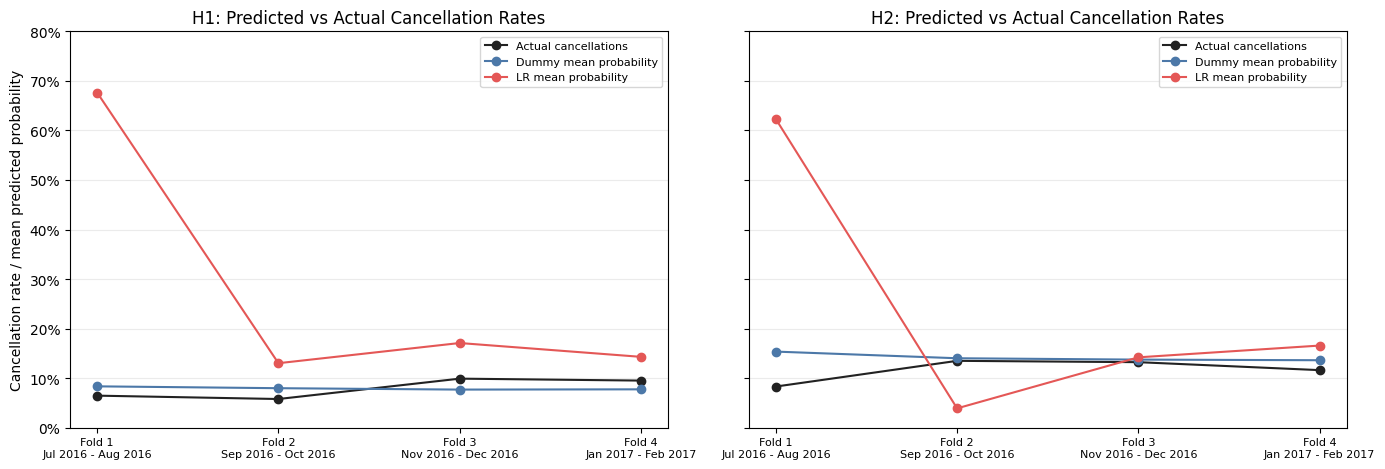

Hotel,Fold,Bookings,ObservedRate,DummyMeanProbability,LRMeanProbability
H1,1,"1,779",6.46%,8.34%,67.62%
H1,2,"1,936",5.79%,7.97%,13.01%
H1,3,"1,152",9.90%,7.69%,17.09%
H1,4,"1,252",9.50%,7.74%,14.30%
H2,1,"3,805",8.30%,15.35%,62.28%
H2,2,"3,958",13.49%,14.01%,3.90%
H2,3,"2,216",13.22%,13.74%,14.20%
H2,4,"2,359",11.62%,13.62%,16.57%


In [22]:
# Summarize validation outcomes and mean predictions by window
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

prediction_rates = oof_predictions.groupby(['Hotel', 'Fold', 'Model']).agg(
    Bookings=('Booking_ID', 'size'),
    ObservedRate=('IsCanceled', 'mean'),
    MeanProbability=('RawProbability', 'mean'),
).reset_index()
diagnostic_rate_summary = prediction_rates.pivot(
    index=['Hotel', 'Fold'], columns='Model', values='MeanProbability'
).reset_index().rename(columns={
    'dummy': 'DummyMeanProbability', 'logistic_regression': 'LRMeanProbability',
})
observed_rates = prediction_rates.loc[
    prediction_rates['Model'].eq('dummy'), ['Hotel', 'Fold', 'Bookings', 'ObservedRate']
]
diagnostic_rate_summary = observed_rates.merge(
    diagnostic_rate_summary, on=['Hotel', 'Fold'], validate='one_to_one'
)

# Compare actual cancellation rates with both baselines in two panels
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), sharey=True)
for ax, hotel in zip(axes, config['hotels']):
    panel = diagnostic_rate_summary.loc[diagnostic_rate_summary['Hotel'].eq(hotel)]
    windows = fold_metrics.loc[
        fold_metrics['Hotel'].eq(hotel) & fold_metrics['Model'].eq('dummy')
    ].sort_values('Fold')
    labels = [
        f'Fold {row.Fold}\n{row.ValidationStart:%b %Y} - '
        f'{row.ValidationEnd - pd.Timedelta(days=1):%b %Y}'
        for row in windows.itertuples()
    ]
    for column, label, color in [
        ('ObservedRate', 'Actual cancellations', '#222222'),
        ('DummyMeanProbability', 'Dummy mean probability', '#4c78a8'),
        ('LRMeanProbability', 'LR mean probability', '#e45756'),
    ]:
        ax.plot(panel['Fold'], panel[column], marker='o', label=label, color=color)
    ax.set_title(f'{hotel}: Predicted vs Actual Cancellation Rates')
    ax.set_xticks(panel['Fold'], labels, fontsize=8)
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.set_ylim(0, 0.8)
    ax.grid(axis='y', alpha=0.25)
    ax.legend(fontsize=8)
axes[0].set_ylabel('Cancellation rate / mean predicted probability')
fig.tight_layout()
plt.show()

# Keep the exact values visible alongside the plot
display(diagnostic_rate_summary.style.format({
    'Bookings': '{:,.0f}', 'ObservedRate': '{:.2%}',
    'DummyMeanProbability': '{:.2%}', 'LRMeanProbability': '{:.2%}',
}).hide(axis='index'))

**Observation:** Fold 1 has severe overprediction: LR averages 67.62% versus 6.46% actual cancellations for H1, and 62.28% versus 8.30% for H2. H1 remains above the observed rate in later windows. H2 reverses direction in fold 2 (3.90% predicted versus 13.49% actual), so the aggregate probability error is not a stable offset.

#### 5.7.2 Training Cohorts and Label Availability

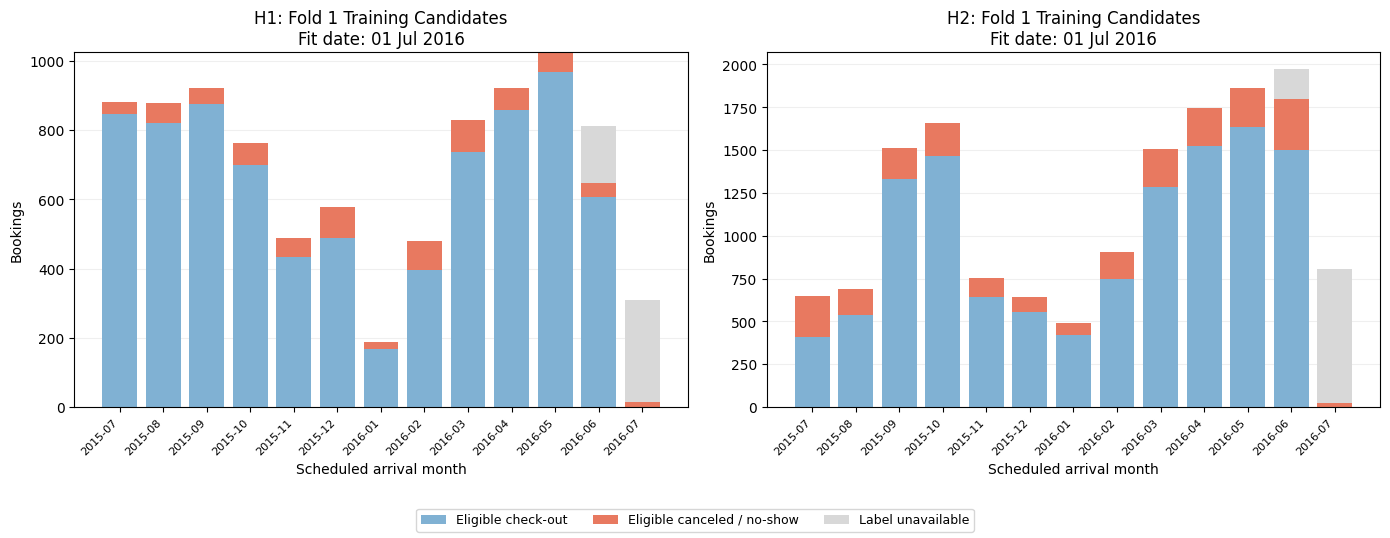

Hotel,ArrivalMonth,EligibleRows,EligiblePositives,EligibleCancelRate,UnavailableRows
H1,2016-05,"1,025",56,5.46%,0
H1,2016-06,648,42,6.48%,164
H1,2016-07,15,15,100.00%,295
H2,2016-05,"1,864",231,12.39%,0
H2,2016-06,"1,798",295,16.41%,174
H2,2016-07,22,22,100.00%,784


In [23]:
# Join fold-1 training candidates with their recorded label eligibility
first_fit_date = pd.Timestamp(split_config['first_fit_date'])
cohort_parts = []
cohort_plot_data = {}
cohort_order = ['Eligible check-out', 'Eligible canceled / no-show', 'Label unavailable']
for hotel in config['hotels']:
    candidates = model_data[hotel].loc[
        model_data[hotel]['CutoffDate'].lt(first_fit_date),
        ['Hotel', 'Booking_ID', 'CutoffDate', 'ArrivalDate', config['target']],
    ].copy()
    eligibility = split_results[hotel]['fit_eligibility']
    eligibility = eligibility.loc[
        eligibility['Stage'].eq('CV') & eligibility['Fold'].eq(1).fillna(False),
        ['Hotel', 'Booking_ID', 'Eligible'],
    ]
    candidates = candidates.merge(
        eligibility, on=['Hotel', 'Booking_ID'], how='left', validate='one_to_one',
    )
    if candidates['Eligible'].isna().any():
        raise AssertionError(f'{hotel}: a fold-1 candidate has no eligibility record')
    candidates['ArrivalMonth'] = candidates['ArrivalDate'].dt.to_period('M').astype(str)
    candidates['Cohort'] = np.where(
        ~candidates['Eligible'], 'Label unavailable',
        np.where(candidates[config['target']].eq(1),
                 'Eligible canceled / no-show', 'Eligible check-out'),
    )

    # Count observed training labels separately from unavailable outcomes
    counts = (candidates.groupby(['ArrivalMonth', 'Cohort']).size().unstack(fill_value=0)
              .reindex(columns=cohort_order, fill_value=0))
    cohort_plot_data[hotel] = counts
    report = counts.rename(columns={
        'Eligible check-out': 'EligibleCheckOut',
        'Eligible canceled / no-show': 'EligiblePositives',
        'Label unavailable': 'UnavailableRows',
    }).reset_index()
    report.insert(0, 'Hotel', hotel)
    report['EligibleRows'] = report['EligibleCheckOut'] + report['EligiblePositives']
    report['EligibleCancelRate'] = report['EligiblePositives'].div(
        report['EligibleRows'].replace(0, np.nan))
    expected_rows = fold_metrics.loc[
        fold_metrics['Hotel'].eq(hotel) & fold_metrics['Fold'].eq(1)
        & fold_metrics['Model'].eq('dummy'), 'TrainRows'
    ].iloc[0]
    if report['EligibleRows'].sum() != expected_rows:
        raise AssertionError(f'{hotel}: cohort counts do not match fold-1 training')
    cohort_parts.append(report)
training_cohort_summary = pd.concat(cohort_parts, ignore_index=True)

# Plot arrival-month cohorts as seen at the first fit date
fig, axes = plt.subplots(1, 2, figsize=(14, 5.4))
colors = ['#80b1d3', '#e87960', '#d8d8d8']
for ax, hotel in zip(axes, config['hotels']):
    counts = cohort_plot_data[hotel]
    bottom = np.zeros(len(counts))
    for column, color in zip(cohort_order, colors):
        ax.bar(range(len(counts)), counts[column], bottom=bottom, color=color, label=column)
        bottom += counts[column].to_numpy()
    ax.set_title(f'{hotel}: Fold 1 Training Candidates\nFit date: {first_fit_date:%d %b %Y}')
    ax.set_xticks(range(len(counts)), counts.index, rotation=45, ha='right', fontsize=8)
    ax.set_xlabel('Scheduled arrival month')
    ax.set_ylabel('Bookings')
    ax.grid(axis='y', alpha=0.2)
    ax.set_axisbelow(True)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=3, fontsize=9)
fig.tight_layout(rect=[0, 0.08, 1, 1])
plt.show()

# Focus the table on the three most recent arrival-month cohorts
recent_months = sorted(training_cohort_summary['ArrivalMonth'].unique())[-3:]
display(training_cohort_summary.loc[
    training_cohort_summary['ArrivalMonth'].isin(recent_months),
    ['Hotel', 'ArrivalMonth', 'EligibleRows', 'EligiblePositives',
     'EligibleCancelRate', 'UnavailableRows'],
].style.format({
    'EligibleRows': '{:,.0f}', 'EligiblePositives': '{:,.0f}',
    'EligibleCancelRate': '{:.2%}', 'UnavailableRows': '{:,.0f}',
}, na_rep='No eligible rows').hide(axis='index'))

**Observation:** At the 1 July fit, the July 2016 arrival cohort contributes only 15 eligible H1 bookings and 22 eligible H2 bookings, all canceled/no-show; another 295 and 784 bookings respectively remain unavailable. Early cancellations can be known while check-out outcomes from this arrival month are still unavailable. The availability filter preserves chronology but leaves the newest observed arrival cohort strongly skewed toward cancellations.

#### 5.7.3 Features Driving Fold 1 Predictions

Compare each feature's mean contribution in validation with train. Positive shifts raise the mean LR score; values are in log-odds, not probability percentage points. Sum one-hot levels back to their original feature.

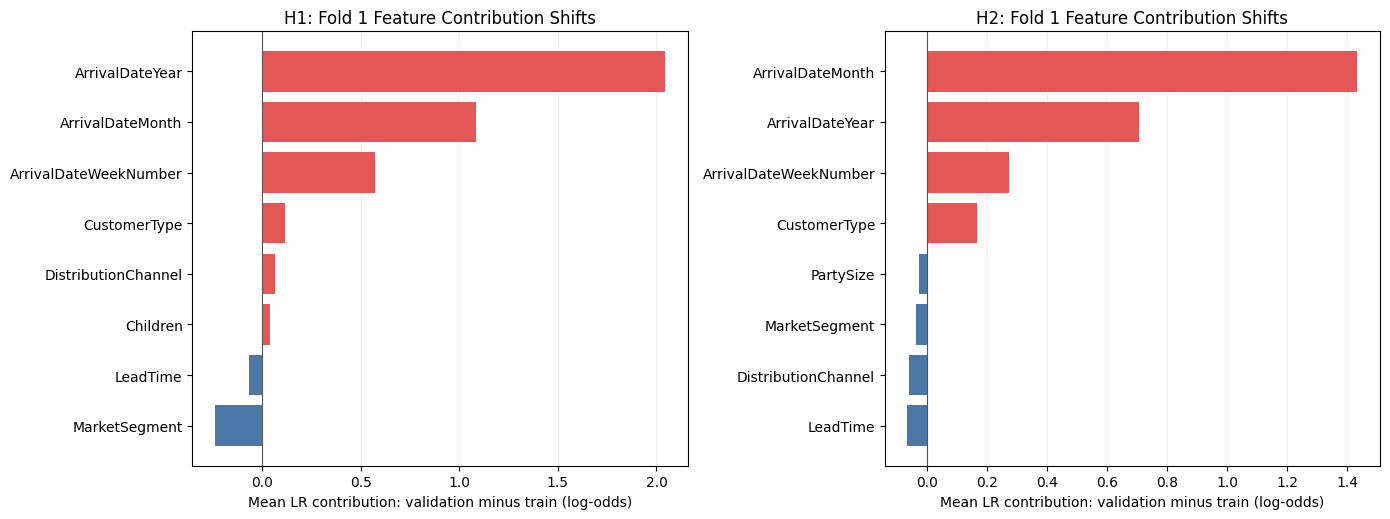

Hotel,MeanScoreShift,SumOfFeatureShifts,Reconciliation
H1,3.5372,3.5372,PASS
H2,2.3853,2.3853,PASS


In [24]:
# Use the fitted fold-1 LR to calculate additive score contributions
contribution_parts = []
score_shift_rows = []
for hotel in config['hotels']:
    pipeline = baseline_models[hotel][1]['logistic_regression']
    before_diagnostics = pickle.dumps(pipeline)
    fitted = pipeline.named_steps['preprocessor']
    estimator = pipeline.named_steps['model']
    train_inputs, valid_inputs = select_fold_features(hotel, 1)
    train_matrix = fitted.transform(train_inputs)
    valid_matrix = fitted.transform(valid_inputs)
    encoded_names = fitted.get_feature_names_out()
    coefficients = estimator.coef_[0]

    # Map encoded columns to original inputs, including categorical levels
    source_names = feature_config['numeric'] + feature_config['binary']
    encoder = fitted.named_transformers_['categorical'].named_steps['encoder']
    for column, categories in zip(feature_config['categorical'], encoder.categories_):
        source_names += [column] * len(categories)
    if len(source_names) != len(encoded_names):
        raise AssertionError(f'{hotel}: encoded feature mapping is incomplete')
    shifts = (valid_matrix.mean(axis=0) - train_matrix.mean(axis=0)) * coefficients
    contributions = pd.DataFrame({
        'Hotel': hotel, 'EncodedFeature': encoded_names,
        'SourceFeature': source_names, 'Coefficient': coefficients,
        'MeanContributionShift': shifts,
    })
    contribution_parts.append(contributions)

    # Reconcile the contributions with the model's actual score shift
    train_score = pipeline.decision_function(train_inputs)
    valid_score = pipeline.decision_function(valid_inputs)
    score_shift = float(valid_score.mean() - train_score.mean())
    if not np.isclose(shifts.sum(), score_shift):
        raise AssertionError(f'{hotel}: contributions do not reconcile with LR scores')
    if pickle.dumps(pipeline) != before_diagnostics:
        raise AssertionError(f'{hotel}: diagnostics changed the fitted model')
    score_shift_rows.append({
        'Hotel': hotel, 'MeanScoreShift': score_shift,
        'SumOfFeatureShifts': float(shifts.sum()), 'Reconciliation': 'PASS',
    })
encoded_contribution_shifts = pd.concat(contribution_parts, ignore_index=True)
feature_contribution_shifts = encoded_contribution_shifts.groupby(
    ['Hotel', 'SourceFeature'], sort=False
)['MeanContributionShift'].sum().reset_index()
score_shift_summary = pd.DataFrame(score_shift_rows)

# Plot the eight largest mean contribution shifts for each hotel
fig, axes = plt.subplots(1, 2, figsize=(14, 5.3))
for ax, hotel in zip(axes, config['hotels']):
    panel = feature_contribution_shifts.loc[feature_contribution_shifts['Hotel'].eq(hotel)]
    largest = panel['MeanContributionShift'].abs().nlargest(8).index
    panel = panel.loc[largest].sort_values('MeanContributionShift')
    colors = ['#e45756' if value > 0 else '#4c78a8' for value in panel['MeanContributionShift']]
    ax.barh(panel['SourceFeature'], panel['MeanContributionShift'], color=colors)
    ax.axvline(0, color='#555555', linewidth=0.8)
    ax.set_title(f'{hotel}: Fold 1 Feature Contribution Shifts')
    ax.set_xlabel('Mean LR contribution: validation minus train (log-odds)')
    ax.grid(axis='x', alpha=0.2)
    ax.set_axisbelow(True)
fig.tight_layout()
plt.show()
display(score_shift_summary.style.format({
    'MeanScoreShift': '{:.4f}', 'SumOfFeatureShifts': '{:.4f}',
}).hide(axis='index'))

**Observation:** Arrival year, month and week number provide the three largest upward mean contribution shifts for both hotels. Year dominates H1; month dominates H2. Feature shifts reconcile with the model score changes for both hotels. The fitted calendar effects therefore account for most of the upward score shift in fold 1. Combined with the cohort imbalance above, this identifies a hypothesis for controlled development experiments; it does not establish the imbalance as the sole cause.

## 6. Candidate Experiments

### 6.1 Calendar Feature Ablation

#### 6.1.1 Experiment Config

In [25]:
# Load the frozen baseline settings for a matched feature comparison
ablation_run_id = 'lr_calendar_ablation_v1'
baseline_directory = project_root / 'Model pipeline' / 'reports' / 'baseline_v1'
baseline_reference_config = json.loads(
    (baseline_directory / 'run_config.json').read_text(encoding='utf-8')
)
if (baseline_reference_config['split_id'] != split_id
        or baseline_reference_config['feature_config'] != feature_config
        or baseline_reference_config['split_config_sha256'] != hashlib.sha256(
            (split_directory / 'config.json').read_bytes()).hexdigest()):
    raise ValueError('Feature experiments require the same baseline split and Core inputs')
for filename in ('utils/model_evaluation.py',):
    digest = baseline_reference_config['code_sha256'][filename]
    if hashlib.sha256((project_root / 'Model pipeline' / filename).read_bytes()).hexdigest() != digest:
        raise ValueError(f'{filename} changed since the baseline')

# Create independent feature lists without changing the Core config
removed_features = {
    'core_no_year': ['ArrivalDateYear'],
    'core_no_year_month_week': [
        'ArrivalDateYear', 'ArrivalDateMonth', 'ArrivalDateWeekNumber',
    ],
}
ablation_feature_sets = {
    name: {group: [column for column in columns if column not in dropped]
           for group, columns in baseline_reference_config['feature_config'].items()}
    for name, dropped in removed_features.items()
}
ablation_model_params = baseline_reference_config['model_params']['logistic_regression'].copy()
original_feature_config = {group: columns.copy() for group, columns in feature_config.items()}
display(pd.DataFrame([
    {'FeatureSet': 'core', 'InputColumns': len(feature_columns), 'Removed': 'None'},
    *[{'FeatureSet': name, 'InputColumns': sum(map(len, groups.values())),
       'Removed': ', '.join(removed_features[name])}
      for name, groups in ablation_feature_sets.items()],
]).style.hide(axis='index'))

FeatureSet,InputColumns,Removed
core,21,None
core_no_year,20,ArrivalDateYear
core_no_year_month_week,18,"ArrivalDateYear, ArrivalDateMonth, ArrivalDateWeekNumber"


#### 6.1.2 Fit and Check H1 Fold 1

In [26]:
# Select the same bookings for an explicitly supplied feature set
def run_candidate_fold(hotel, fold, model_name, feature_set_name, input_config, model_params,
                       training_lookback_months=None):
    if training_lookback_months is not None and (
        isinstance(training_lookback_months, bool)
        or not isinstance(training_lookback_months, int) or training_lookback_months < 1
    ):
        raise ValueError('training_lookback_months must be a positive integer or None')
    columns = [column for group in input_config.values() for column in group]
    membership = cv_memberships[hotel]
    window = membership.loc[membership['Fold'].eq(fold)]
    fit_dates = window['FitDate'].unique()
    if len(fit_dates) != 1:
        raise ValueError(f'{hotel} fold {fold}: expected one fit date')
    fit_date = pd.Timestamp(fit_dates[0])
    cohorts = {}
    for role in ('Train', 'Validation'):
        keys = window.loc[window['Role'].eq(role), ['Hotel', 'Booking_ID']]
        joined = keys.merge(
            model_data[hotel][['Hotel', 'Booking_ID', 'CutoffDate', config['target']] + columns],
            on=['Hotel', 'Booking_ID'], how='left', validate='one_to_one', indicator=True,
        )
        if joined.empty or not joined['_merge'].eq('both').all():
            raise ValueError(f'{hotel} fold {fold}: unmatched or empty {role} cohort')
        cohorts[role] = joined.drop(columns='_merge')
    train, valid = cohorts['Train'], cohorts['Validation']
    expanding_train = train

    # Restrict eligible train to the requested calendar history when configured
    if training_lookback_months is not None:
        train_start = fit_date - pd.DateOffset(months=training_lookback_months)
        train = train.loc[train['CutoffDate'].ge(train_start)].copy()
        if train.empty:
            raise ValueError(f'{hotel} fold {fold}: rolling train is empty')
    train_X, valid_X = train[columns].copy(), valid[columns].copy()
    train_y, valid_y = train[config['target']], valid[config['target']]

    # Fit a fresh pipeline using only this candidate's training features
    pipeline = model_pipeline.build_pipeline(model_name, input_config, model_params)
    if hasattr(pipeline.named_steps['model'], 'classes_'):
        raise AssertionError('Candidate pipeline must start unfitted')
    with warnings.catch_warnings(record=True) as captured:
        warnings.simplefilter('always')
        pipeline.fit(train_X, train_y)
    convergence_warnings = [item for item in captured
                            if issubclass(item.category, ConvergenceWarning)]
    for item in captured:
        if not issubclass(item.category, ConvergenceWarning):
            warnings.warn(str(item.message), item.category)
    estimator = pipeline.named_steps['model']
    if model_name == 'xgboost':
        fitted_state = (pickle.dumps(pipeline.named_steps['preprocessor']),
                        bytes(estimator.get_booster().save_raw()))
    else:
        fitted_state = pickle.dumps(pipeline)
    probabilities = pipeline.predict_proba(valid_X)[:, list(estimator.classes_).index(1)].astype(float)
    metrics = model_evaluation.evaluate_predictions(valid_y, probabilities)
    if model_name == 'xgboost':
        prediction_state = (pickle.dumps(pipeline.named_steps['preprocessor']),
                            bytes(estimator.get_booster().save_raw()))
    else:
        prediction_state = pickle.dumps(pipeline)

    # Audit unchanged cohorts and train-only preprocessing
    preprocessor = pipeline.named_steps['preprocessor']
    numeric = preprocessor.named_transformers_['numeric']
    encoder = preprocessor.named_transformers_['categorical'].named_steps['encoder']
    reference = fold_metrics.loc[
        fold_metrics['Hotel'].eq(hotel) & fold_metrics['Fold'].eq(fold)
        & fold_metrics['Model'].eq('logistic_regression')
    ].iloc[0]
    checks = {
        'Saved training cohort matches baseline': len(expanding_train) == reference['TrainRows']
            and int(expanding_train[config['target']].sum()) == reference['TrainPositives'],
        'Validation cohort matches baseline': len(valid) == reference['ValidationRows']
            and int(valid_y.sum()) == reference['ValidationPositives'],
        'Model parameters match config': all(
            estimator.get_params()[name] == value for name, value in model_params.items()),
        'Preprocessing uses only candidate inputs': list(preprocessor.feature_names_in_) == columns
            and estimator.n_features_in_ == len(preprocessor.get_feature_names_out()),
        'Numeric statistics fitted on eligible train': np.allclose(
            numeric.named_steps['imputer'].statistics_, train_X[input_config['numeric']].median())
            and ('scaler' not in numeric.named_steps
                 or np.all(numeric.named_steps['scaler'].n_samples_seen_ == len(train))),
        'Encoder vocabulary fitted on eligible train': all(
            np.array_equal(categories, np.sort(train_X[column].fillna('__MISSING__').unique()))
            for column, categories in zip(input_config['categorical'], encoder.categories_)),
        'Predictions preserve the fitted pipeline': prediction_state == fitted_state,
        'One finite class-1 probability per booking': probabilities.shape == (len(valid),)
            and np.isfinite(probabilities).all()
            and ((probabilities >= 0) & (probabilities <= 1)).all(),
        'Train and validation bookings are disjoint':
            not set(train['Booking_ID']).intersection(valid['Booking_ID']),
    }
    # Check the rolling history against the independent eligibility records
    if training_lookback_months is not None:
        eligibility = split_results[hotel]['fit_eligibility']
        eligibility = eligibility.loc[
            eligibility['Stage'].eq('CV') & eligibility['Fold'].eq(fold).fillna(False)
            & eligibility['Eligible'], ['Hotel', 'Booking_ID', 'LabelAvailableDate'],
        ]
        expected_history = eligibility.merge(
            model_data[hotel][['Hotel', 'Booking_ID', 'CutoffDate']],
            on=['Hotel', 'Booking_ID'], validate='one_to_one',
        )
        expected_history = expected_history.loc[
            expected_history['CutoffDate'].ge(train_start)
            & expected_history['CutoffDate'].lt(fit_date)
            & expected_history['LabelAvailableDate'].lt(fit_date)
        ]
        checks['Rolling membership matches eligible calendar history'] = (
            set(train['Booking_ID']) == set(expected_history['Booking_ID']))
        checks['Rolling history boundaries respected'] = (
            train['CutoffDate'].ge(train_start).all() and train['CutoffDate'].lt(fit_date).all())
        checks['Rolling labels available before fit'] = (
            expected_history['LabelAvailableDate'].lt(fit_date).all())

    # Inspect optimization or tree construction for the selected model
    if model_name == 'logistic_regression':
        checks['Optimization converged'] = not convergence_warnings
    elif model_name == 'random_forest':
        checks['All configured trees fitted'] = len(estimator.estimators_) == model_params['n_estimators']
        checks['Numeric scaling disabled'] = 'scaler' not in numeric.named_steps
        checks['Every leaf meets the minimum size'] = all(
            tree.tree_.n_node_samples[tree.tree_.children_left == -1].min()
            >= model_params['min_samples_leaf'] for tree in estimator.estimators_
        )
    elif model_name == 'xgboost':
        booster = estimator.get_booster()
        tree_structures = [json.loads(tree) for tree in booster.get_dump(dump_format='json')]

        def tree_depth(node):
            return (0 if 'leaf' in node else
                    1 + max(tree_depth(child) for child in node['children']))

        max_tree_depth = max(tree_depth(tree) for tree in tree_structures)
        checks['All configured boosting rounds fitted'] = (
            booster.num_boosted_rounds() == model_params['n_estimators'])
        checks['Numeric scaling disabled'] = 'scaler' not in numeric.named_steps
        checks['Trees respect the configured depth'] = max_tree_depth <= model_params['max_depth']
        checks['Early stopping and eval_set unused'] = (
            estimator.get_params()['early_stopping_rounds'] is None
            and not getattr(estimator, 'evals_result_', {}))
    audit = pd.DataFrame([
        {'Hotel': hotel, 'Fold': fold, 'Model': model_name, 'FeatureSet': feature_set_name,
         'Check': name, 'Passed': bool(passed)} for name, passed in checks.items()
    ])
    if not audit['Passed'].all():
        display(audit.loc[~audit['Passed']])
        raise AssertionError(f'{hotel} fold {fold}: {feature_set_name} failed checks')

    # Return comparable validation metrics and keyed OOF predictions
    row = {
        'Hotel': hotel, 'Model': model_name, 'FeatureSet': feature_set_name, 'Fold': fold,
        'FitDate': fit_date, 'ValidationStart': fit_date,
        'ValidationEnd': fit_date + pd.DateOffset(months=split_config['validation_months']),
        'TrainRows': len(train), 'TrainPositives': int(train_y.sum()),
        'TrainCancelRate': float(train_y.mean()),
        'ValidationRows': metrics.pop('Rows'), 'ValidationPositives': metrics.pop('Positives'),
        'ValidationCancelRate': metrics.pop('CancelRate'), **metrics,
        'InputColumns': len(columns),
        'ProcessedColumns': len(preprocessor.get_feature_names_out()),
    }
    if model_name == 'logistic_regression':
        row.update({'Iterations': int(estimator.n_iter_[0]), 'Converged': not convergence_warnings})
    elif model_name == 'random_forest':
        row.update({
            'Trees': len(estimator.estimators_),
            'MaxTreeDepth': max(tree.tree_.max_depth for tree in estimator.estimators_),
        })
    elif model_name == 'xgboost':
        row.update({'BoostingRounds': booster.num_boosted_rounds(),
                    'MaxTreeDepth': max_tree_depth})
    if training_lookback_months is not None:
        row.update({'TrainWindowStart': train_start,
                    'HistoryRemovedRows': len(expanding_train) - len(train),
                    'HistoryRemovedPositives': int(expanding_train[config['target']].sum() - train_y.sum())})
    predictions = valid[['Hotel', 'Booking_ID', 'CutoffDate', config['target']]].rename(
        columns={'CutoffDate': 'PredictionDate'}).copy()
    predictions.insert(2, 'Model', model_name)
    predictions.insert(3, 'FeatureSet', feature_set_name)
    predictions.insert(4, 'Fold', fold)
    predictions['RawProbability'] = probabilities
    return {'pipeline': pipeline, 'metrics': row, 'predictions': predictions, 'checks': audit}

# Check both feature sets on H1 fold 1 before expanding the experiment
ablation_prototypes = {
    name: run_candidate_fold('H1', 1, 'logistic_regression', name, groups, ablation_model_params)
    for name, groups in ablation_feature_sets.items()
}
prototype_metrics = pd.DataFrame([result['metrics'] for result in ablation_prototypes.values()])
display(prototype_metrics[['FeatureSet', 'InputColumns', 'ValidationRows'] + metric_columns]
        .style.format({metric: '{:.4f}' for metric in metric_columns}).hide(axis='index'))
print('Both H1 fold 1 candidate audits passed')

FeatureSet,InputColumns,ValidationRows,LogLoss,BrierScore,ROC_AUC,AveragePrecision
core_no_year,20,1779,0.2378,0.0605,0.6056,0.0878
core_no_year_month_week,18,1779,0.2381,0.0607,0.6080,0.0887


Both H1 fold 1 candidate audits passed


**Observation:** Both H1 fold 1 variants pass the checks. Removing Year reduces Log Loss from 1.1801 to 0.2378; removing Year/Month/Week gives 0.2381. Both are slightly better than Dummy (0.2420) in this window.

#### 6.1.3 Run H1/H2 Temporal CV

In [27]:
# Fit both feature sets on all four shared validation windows
ablation_models = {hotel: {} for hotel in config['hotels']}
ablation_metric_rows, ablation_prediction_parts, ablation_check_parts = [], [], []
for hotel in config['hotels']:
    for fold in range(1, split_config['n_folds'] + 1):
        ablation_models[hotel][fold] = {}
        for name, groups in ablation_feature_sets.items():
            result = (ablation_prototypes[name] if hotel == 'H1' and fold == 1
                      else run_candidate_fold(hotel, fold, 'logistic_regression',
                                              name, groups, ablation_model_params))
            ablation_models[hotel][fold][name] = result['pipeline']
            ablation_metric_rows.append(result['metrics'])
            ablation_prediction_parts.append(result['predictions'])
            ablation_check_parts.append(result['checks'])
ablation_metrics = pd.DataFrame(ablation_metric_rows)
ablation_predictions = pd.concat(ablation_prediction_parts, ignore_index=True)
ablation_checks = pd.concat(ablation_check_parts, ignore_index=True)

# Verify exact OOF alignment with the frozen baseline for each feature set
reference_predictions = pd.concat([
    pd.read_csv(baseline_directory / hotel / 'oof_predictions.csv',
                parse_dates=['PredictionDate'], float_precision='round_trip')
    for hotel in config['hotels']
], ignore_index=True)
reference_predictions = reference_predictions.loc[
    reference_predictions['Model'].eq('logistic_regression')
]
ablation_oof_checks = []
for hotel in config['hotels']:
    expected = reference_predictions.loc[reference_predictions['Hotel'].eq(hotel)]
    for name in ablation_feature_sets:
        observed = ablation_predictions.loc[
            ablation_predictions['Hotel'].eq(hotel) & ablation_predictions['FeatureSet'].eq(name)
        ]
        joined = observed.merge(
            expected, on=['Hotel', 'Booking_ID', 'Model'], how='outer', indicator=True,
            suffixes=('', '_reference'), validate='one_to_one',
        )
        passed = (len(observed) == len(expected) and joined['_merge'].eq('both').all()
                  and joined['Fold'].eq(joined['Fold_reference']).all()
                  and joined['PredictionDate'].eq(joined['PredictionDate_reference']).all()
                  and joined[config['target']].eq(joined[f'{config["target"]}_reference']).all())
        ablation_oof_checks.append({'Hotel': hotel, 'FeatureSet': name, 'Passed': bool(passed)})
ablation_oof_checks = pd.DataFrame(ablation_oof_checks)
if not ablation_oof_checks['Passed'].all():
    display(ablation_oof_checks.loc[~ablation_oof_checks['Passed']])
    raise AssertionError('Feature-set OOF predictions do not match baseline cohorts')
if feature_config != original_feature_config:
    raise AssertionError('The original Core config changed during the experiment')
expected_fits = len(config['hotels']) * split_config['n_folds'] * len(ablation_feature_sets)
if len(ablation_metrics) != expected_fits:
    raise AssertionError('Missing feature-set fits')
print(f'All {expected_fits} feature-set fits passed ({len(ablation_checks)} checks); '
      'OOF cohorts match baseline')

All 16 feature-set fits passed (160 checks); OOF cohorts match baseline


**Observation:** All 16 candidate fits pass the checks and converge within 44-85 iterations. Both feature sets use exactly the baseline validation bookings, labels, folds and prediction dates. The original Core config remains unchanged.

#### 6.1.4 Compare Feature Sets

In [28]:
# Read the frozen Core and Dummy metrics as comparison references
reference_metrics = pd.concat([
    pd.read_csv(baseline_directory / hotel / 'fold_metrics.csv',
                parse_dates=['FitDate', 'ValidationStart', 'ValidationEnd'],
                float_precision='round_trip')
    for hotel in config['hotels']
], ignore_index=True)
reference_metrics['FeatureSet'] = np.where(reference_metrics['Model'].eq('dummy'), 'prior', 'core')
comparison_columns = ['Hotel', 'Model', 'FeatureSet', 'Fold', 'ValidationRows',
                      'ValidationPositives', 'ValidationCancelRate'] + metric_columns
ablation_comparison_metrics = pd.concat([
    reference_metrics[comparison_columns], ablation_metrics[comparison_columns],
], ignore_index=True)
counts = ablation_comparison_metrics.groupby(['Hotel', 'Model', 'FeatureSet'])['Fold'].nunique()
if not counts.eq(split_config['n_folds']).all():
    raise AssertionError('Each comparison needs all four validation windows')

# Rank equal-weight CV means and retain every window for inspection
ablation_cv_summary = (ablation_comparison_metrics.groupby(
    ['Hotel', 'Model', 'FeatureSet'], sort=False)[metric_columns].mean().reset_index()
    .sort_values(['Hotel', 'LogLoss']))
ablation_cv_summary.insert(3, 'Rank', ablation_cv_summary.groupby('Hotel').cumcount() + 1)
display(ablation_cv_summary.style.format({metric: '{:.4f}' for metric in metric_columns})
        .hide(axis='index'))
ablation_window_log_loss = ablation_comparison_metrics.pivot(
    index=['Hotel', 'Fold'], columns='FeatureSet', values='LogLoss'
).reset_index()[['Hotel', 'Fold', 'prior', 'core', 'core_no_year', 'core_no_year_month_week']]
display(ablation_window_log_loss.style.format({
    column: '{:.4f}' for column in ablation_window_log_loss.columns if column not in ('Hotel', 'Fold')
}).hide(axis='index'))

# Compare mean predicted probabilities with actual cancellation rates
rate_predictions = reference_predictions.copy()
rate_predictions['FeatureSet'] = 'core'
rate_predictions = pd.concat([rate_predictions, ablation_predictions], ignore_index=True)
ablation_rates = rate_predictions.groupby(['Hotel', 'Fold', 'FeatureSet']).agg(
    ObservedRate=('IsCanceled', 'mean'), MeanProbability=('RawProbability', 'mean'),
).reset_index()
ablation_rate_comparison = ablation_rates.pivot(
    index=['Hotel', 'Fold'], columns='FeatureSet', values='MeanProbability'
).reset_index()
observed = ablation_rates.loc[ablation_rates['FeatureSet'].eq('core'),
                             ['Hotel', 'Fold', 'ObservedRate']]
ablation_rate_comparison = observed.merge(
    ablation_rate_comparison, on=['Hotel', 'Fold'], validate='one_to_one')
display(ablation_rate_comparison.style.format({
    column: '{:.2%}' for column in ablation_rate_comparison.columns if column not in ('Hotel', 'Fold')
}).hide(axis='index'))

Hotel,Model,FeatureSet,Rank,LogLoss,BrierScore,ROC_AUC,AveragePrecision
H1,logistic_regression,core_no_year_month_week,1,0.2707,0.0728,0.6331,0.1245
H1,logistic_regression,core_no_year,2,0.2741,0.0736,0.6254,0.1208
H1,dummy,prior,3,0.2772,0.0729,0.5000,0.0791
H1,logistic_regression,core,4,0.5197,0.1742,0.6285,0.1219
H2,dummy,prior,1,0.3640,0.1039,0.5000,0.1166
H2,logistic_regression,core_no_year_month_week,2,0.3736,0.1095,0.5931,0.1532
H2,logistic_regression,core_no_year,3,0.4085,0.1229,0.5815,0.1437
H2,logistic_regression,core,4,0.5683,0.1878,0.5767,0.1400


Hotel,Fold,prior,core,core_no_year,core_no_year_month_week
H1,1,0.2420,1.1801,0.2378,0.2381
H1,2,0.2246,0.2426,0.2176,0.2137
H1,3,0.3260,0.3400,0.3251,0.3193
H1,4,0.3161,0.3162,0.3160,0.3119
H2,1,0.3085,1.0102,0.4130,0.3044
H2,2,0.3957,0.4678,0.3927,0.3857
H2,3,0.3907,0.4251,0.4322,0.4287
H2,4,0.3610,0.3702,0.3961,0.3758


Hotel,Fold,ObservedRate,core,core_no_year,core_no_year_month_week
H1,1,6.46%,67.62%,5.95%,6.66%
H1,2,5.79%,13.01%,7.94%,7.15%
H1,3,9.90%,17.09%,13.67%,13.45%
H1,4,9.50%,14.30%,14.31%,12.78%
H2,1,8.30%,62.28%,27.03%,15.48%
H2,2,13.49%,3.90%,10.61%,13.63%
H2,3,13.22%,14.20%,18.50%,19.44%
H2,4,11.62%,16.57%,21.60%,18.07%


**Observation:**

- **H1:** The 18-feature LR has the lowest mean Log Loss (0.2707), compared with 0.2741 without Year and 0.2772 for Dummy. It beats Dummy in all four windows, with a small margin.
- **H2:** The 18-feature LR improves mean Log Loss to 0.3736, but remains worse than Dummy (0.3640). Relative to Core LR, windows 1-2 improve while windows 3-4 worsen.
- Calendar removal improves these LR experiments, especially fold 1. Training cohorts were unchanged, so this comparison does not isolate the effect of label-availability selection.

#### 6.1.5 Save Experiment Results

In [29]:
# Require successful fits, aligned OOF cohorts and unchanged Core settings
if (not ablation_checks['Passed'].all() or not ablation_oof_checks['Passed'].all()
        or not ablation_metrics['Converged'].all() or feature_config != original_feature_config):
    raise ValueError('Feature-set experiment checks must pass before saving')
ablation_report_directory = project_root / 'Model pipeline' / 'reports' / ablation_run_id

# Record the changed feature lists and the fixed baseline settings
ablation_run_config = {
    'run_id': ablation_run_id, 'reference_run_id': 'baseline_v1', 'split_id': split_id,
    'model': 'logistic_regression', 'model_params': ablation_model_params,
    'feature_sets': ablation_feature_sets, 'removed_features': removed_features,
    'evaluation': baseline_reference_config['evaluation'],
    'environment': {
        'python': sys.version.split()[0], 'numpy': np.__version__,
        'pandas': pd.__version__, 'scikit_learn': sklearn.__version__,
    },
    'reference_config_sha256': hashlib.sha256((baseline_directory / 'run_config.json').read_bytes()).hexdigest(),
    'split_config_sha256': hashlib.sha256((split_directory / 'config.json').read_bytes()).hexdigest(),
    'code_sha256': {
        filename: hashlib.sha256((project_root / 'Model pipeline' / filename).read_bytes()).hexdigest()
        for filename in ('utils/model_pipeline.py', 'utils/model_evaluation.py')
    },
    'output_schema': {},
}
ablation_report_tables = {}
for hotel in config['hotels']:
    ablation_report_tables[f'{hotel}/fold_metrics.csv'] = ablation_metrics.loc[
        ablation_metrics['Hotel'].eq(hotel)
    ].reset_index(drop=True)
    ablation_report_tables[f'{hotel}/oof_predictions.csv'] = ablation_predictions.loc[
        ablation_predictions['Hotel'].eq(hotel)
    ].reset_index(drop=True)

# Serialize date columns consistently and record types for reloading
ablation_report_contents = {}
for relative_path, table in ablation_report_tables.items():
    dates = [column for column in table if pd.api.types.is_datetime64_any_dtype(table[column])]
    ablation_run_config['output_schema'][relative_path] = {
        'dtypes': {column: str(dtype) for column, dtype in table.dtypes.items()},
        'date_columns': dates,
    }
    ablation_report_contents[relative_path] = table.to_csv(
        index=False, date_format='%Y-%m-%d', lineterminator='\n'
    ).encode('utf-8')
ablation_config_contents = (json.dumps(ablation_run_config, indent=2) + '\n').encode('utf-8')
# Retain original code provenance when verifying an existing frozen run
frozen_config_path = ablation_report_directory / 'run_config.json'
if frozen_config_path.exists():
    frozen_config = json.loads(frozen_config_path.read_text(encoding='utf-8'))
    current_settings = {key: value for key, value in ablation_run_config.items()
                        if key != 'code_sha256'}
    frozen_settings = {key: value for key, value in frozen_config.items()
                       if key != 'code_sha256'}
    if current_settings == frozen_settings:
        ablation_run_config['code_sha256'] = frozen_config['code_sha256']
        ablation_config_contents = (json.dumps(ablation_run_config, indent=2) + '\n').encode('utf-8')
ablation_expected_contents = {**ablation_report_contents, 'run_config.json': ablation_config_contents}

# Preserve previous experiments if their contents differ
for relative_path, contents in ablation_expected_contents.items():
    destination = ablation_report_directory / relative_path
    if destination.exists():
        existing = destination.read_bytes()
        matches = (json.loads(existing) == json.loads(contents)
                   if destination.suffix == '.json' else existing == contents)
        if not matches:
            raise FileExistsError(f'{destination} differs from this experiment; use a new ablation_run_id')

# Save and verify every table, preserving floating-point probabilities
ablation_save_rows = []
for relative_path, table in ablation_report_tables.items():
    destination = ablation_report_directory / relative_path
    destination.parent.mkdir(parents=True, exist_ok=True)
    if not destination.exists():
        destination.write_bytes(ablation_report_contents[relative_path])
    schema = ablation_run_config['output_schema'][relative_path]
    dtype_map = {column: dtype for column, dtype in schema['dtypes'].items()
                 if column not in schema['date_columns']}
    restored = pd.read_csv(
        destination, dtype=dtype_map, parse_dates=schema['date_columns'],
        keep_default_na=False, float_precision='round_trip',
    )
    for column in schema['date_columns']:
        restored[column] = restored[column].astype(schema['dtypes'][column])
    pd.testing.assert_frame_equal(table.reset_index(drop=True), restored, check_exact=True)
    ablation_save_rows.append({'Hotel': relative_path.split('/')[0], 'File': destination.name,
                             'Rows': len(restored), 'Read-back check': 'PASS'})

# Publish the run config after all read-back checks pass
config_destination = ablation_report_directory / 'run_config.json'
if not config_destination.exists():
    config_destination.write_bytes(ablation_config_contents)
if json.loads(config_destination.read_text(encoding='utf-8')) != ablation_run_config:
    raise AssertionError('Saved run config differs from this experiment')
ablation_save_summary = pd.DataFrame(ablation_save_rows)
display(ablation_save_summary.style.format({'Rows': '{:,.0f}'}).hide(axis='index'))
print(f'Saved {ablation_run_id}: validation metrics, OOF probabilities and run config')
print('Directory:', ablation_report_directory)

Hotel,File,Rows,Read-back check
H1,fold_metrics.csv,8,PASS
H1,oof_predictions.csv,"12,238",PASS
H2,fold_metrics.csv,8,PASS
H2,oof_predictions.csv,"24,676",PASS


Saved lr_calendar_ablation_v1: validation metrics, OOF probabilities and run config
Directory: /workspace/Project/Model pipeline/reports/lr_calendar_ablation_v1


**Observation:** `reports/lr_calendar_ablation_v1/` saves both variants with a `FeatureSet` key in the metrics and OOF tables. Every read-back check passes. Baseline reports, split artifacts and utility functions remain unchanged.

**Observation**
- Removing the three calendar features greatly improves LR’s probability predictions.
- For H1, the 18-feature version achieves the lowest mean Log Loss and outperforms Dummy in all four validation windows.
- For H2, it is the best LR version, but its mean Log Loss remains worse than Dummy.

**Decision**
Use the 18-feature set for subsequent LR experiments, excluding `ArrivalDateYear`, `ArrivalDateMonth`, and `ArrivalDateWeekNumber`.

The Core feature pool remains unchanged at 21 features. This result does not yet determine the feature sets for Random Forest, XGBoost, or the final model.

### 6.2 Random Forest

#### 6.2.1 Experiment Config

In [30]:
# Reload the pipeline factory with Random Forest support
importlib.reload(model_pipeline)
rf_run_id = 'rf_initial_v1'
rf_feature_set_name = 'core_no_year_month_week'
rf_reference_directory = project_root / 'Model pipeline' / 'reports' / 'lr_calendar_ablation_v1'
rf_reference_config = json.loads(
    (rf_reference_directory / 'run_config.json').read_text(encoding='utf-8')
)
if (rf_reference_config['split_id'] != split_id
        or rf_reference_config['evaluation'] != evaluation_config
        or rf_reference_config['split_config_sha256'] != hashlib.sha256(
            (split_directory / 'config.json').read_bytes()).hexdigest()):
    raise ValueError('RF and LR comparisons require the same split and evaluation settings')

# Copy the 18-feature LR input set and keep the original Core pool unchanged
rf_feature_config = {
    group: columns.copy()
    for group, columns in rf_reference_config['feature_sets'][rf_feature_set_name].items()
}
rf_columns = [column for columns in rf_feature_config.values() for column in columns]
if len(rf_columns) != 18 or set(rf_columns) & forbidden_inputs:
    raise ValueError('RF must use the selected 18 predictors without metadata or outcome fields')

# Define the initial RF settings for both hotels
rf_model_params = {
    'n_estimators': 300, 'max_depth': None, 'min_samples_leaf': 20,
    'max_features': 'sqrt', 'criterion': 'gini', 'bootstrap': True,
    'class_weight': None, 'random_state': 42, 'n_jobs': 2,
}
display(pd.DataFrame([
    {'Parameter': name, 'Value': str(value)} for name, value in rf_model_params.items()
]).style.hide(axis='index'))
print('Inputs:', len(rf_columns), '| Numeric scaling: disabled')

Parameter,Value
n_estimators,300
max_depth,None
min_samples_leaf,20
max_features,sqrt
criterion,gini
bootstrap,True
class_weight,None
random_state,42
n_jobs,2


Inputs: 18 | Numeric scaling: disabled


#### 6.2.2 Fit and Check H1 Fold 1

In [31]:
# Fit one fresh RF pipeline before expanding to both hotels
rf_prototype = run_candidate_fold(
    'H1', 1, 'random_forest', rf_feature_set_name, rf_feature_config, rf_model_params,
)
rf_prototype_metrics = pd.DataFrame([rf_prototype['metrics']])
display(rf_prototype_metrics[
    ['Hotel', 'Fold', 'TrainRows', 'ValidationRows', 'InputColumns', 'Trees'] + metric_columns
].style.format({metric: '{:.4f}' for metric in metric_columns}).hide(axis='index'))
display(rf_prototype['checks'][['Check', 'Passed']].style.hide(axis='index'))

Hotel,Fold,TrainRows,ValidationRows,InputColumns,Trees,LogLoss,BrierScore,ROC_AUC,AveragePrecision
H1,1,8618,1779,18,300,0.2328,0.0596,0.6444,0.1102


Check,Passed
Saved training cohort matches baseline,True
Validation cohort matches baseline,True
Model parameters match config,True
Preprocessing uses only candidate inputs,True
Numeric statistics fitted on eligible train,True
Encoder vocabulary fitted on eligible train,True
Predictions preserve the fitted pipeline,True
One finite class-1 probability per booking,True
Train and validation bookings are disjoint,True
All configured trees fitted,True


**Observation:** H1 fold 1 passes all 12 checks. RF Log Loss is 0.2328, compared with 0.2381 for LR18 and 0.2420 for Dummy.

#### 6.2.3 Run H1/H2 Temporal CV

In [32]:
# Reuse the checked prototype and fit the remaining seven hotel/fold combinations
rf_models = {hotel: {} for hotel in config['hotels']}
rf_metric_rows, rf_prediction_parts, rf_check_parts = [], [], []
for hotel in config['hotels']:
    for fold in range(1, split_config['n_folds'] + 1):
        result = (rf_prototype if hotel == 'H1' and fold == 1 else run_candidate_fold(
            hotel, fold, 'random_forest', rf_feature_set_name, rf_feature_config, rf_model_params,
        ))
        rf_models[hotel][fold] = result['pipeline']
        rf_metric_rows.append(result['metrics'])
        rf_prediction_parts.append(result['predictions'])
        rf_check_parts.append(result['checks'])
rf_metrics = pd.DataFrame(rf_metric_rows)
rf_predictions = pd.concat(rf_prediction_parts, ignore_index=True)
rf_checks = pd.concat(rf_check_parts, ignore_index=True)

# Match every RF validation booking, label and prediction date to the saved LR18 OOF rows
rf_lr_reference_predictions = pd.concat([
    pd.read_csv(rf_reference_directory / hotel / 'oof_predictions.csv',
                parse_dates=['PredictionDate'], float_precision='round_trip')
    for hotel in config['hotels']
], ignore_index=True)
rf_lr_reference_predictions = rf_lr_reference_predictions.loc[
    rf_lr_reference_predictions['FeatureSet'].eq(rf_feature_set_name)
]
rf_oof_rows = []
for hotel in config['hotels']:
    observed = rf_predictions.loc[rf_predictions['Hotel'].eq(hotel)]
    expected = rf_lr_reference_predictions.loc[rf_lr_reference_predictions['Hotel'].eq(hotel)]
    matched = observed.merge(
        expected, on=['Hotel', 'Booking_ID'], how='outer', indicator=True,
        suffixes=('', '_lr'), validate='one_to_one',
    )
    passed = (len(observed) == len(expected) and matched['_merge'].eq('both').all()
              and matched['Fold'].eq(matched['Fold_lr']).all()
              and matched['PredictionDate'].eq(matched['PredictionDate_lr']).all()
              and matched[config['target']].eq(matched[f'{config["target"]}_lr']).all()
              and not observed.duplicated(['Hotel', 'Booking_ID']).any())
    rf_oof_rows.append({'Hotel': hotel, 'Validation bookings': len(observed),
                        'OOF alignment': 'PASS' if passed else 'FAIL'})
rf_oof_checks = pd.DataFrame(rf_oof_rows)
if (len(rf_metrics) != len(config['hotels']) * split_config['n_folds']
        or not rf_checks['Passed'].all()
        or not rf_oof_checks['OOF alignment'].eq('PASS').all()
        or feature_config != original_feature_config):
    raise AssertionError('RF fits, OOF alignment or Core preservation failed')

# Display a compact audit summary for each hotel
rf_audit_summary = rf_checks.groupby('Hotel', sort=False).agg(
    Fits=('Fold', 'nunique'), Checks=('Passed', 'size'), Passed=('Passed', 'sum'),
).reset_index().merge(rf_oof_checks, on='Hotel', validate='one_to_one')
display(rf_audit_summary.style.hide(axis='index'))

Hotel,Fits,Checks,Passed,Validation bookings,OOF alignment
H1,4,48,48,6119,PASS
H2,4,48,48,12338,PASS


**Observation:** All eight RF fits pass 96 checks. The OOF bookings, labels, folds and prediction dates match LR18 exactly: 6,119 bookings for H1 and 12,338 for H2. Numeric scaling is disabled and the original Core feature config remains unchanged.

#### 6.2.4 Compare Dummy, LR18 and RF18

In [33]:
# Read the frozen Dummy and LR18 validation metrics
rf_dummy_reference = pd.concat([
    pd.read_csv(baseline_directory / hotel / 'fold_metrics.csv', float_precision='round_trip')
    for hotel in config['hotels']
], ignore_index=True)
rf_dummy_reference = rf_dummy_reference.loc[rf_dummy_reference['Model'].eq('dummy')].copy()
rf_dummy_reference['FeatureSet'] = 'prior'
rf_lr_reference_metrics = pd.concat([
    pd.read_csv(rf_reference_directory / hotel / 'fold_metrics.csv', float_precision='round_trip')
    for hotel in config['hotels']
], ignore_index=True)
rf_lr_reference_metrics = rf_lr_reference_metrics.loc[
    rf_lr_reference_metrics['FeatureSet'].eq(rf_feature_set_name)
]
rf_comparison_columns = ['Hotel', 'Model', 'FeatureSet', 'Fold', 'ValidationRows',
                         'ValidationPositives', 'ValidationCancelRate'] + metric_columns
rf_comparison_metrics = pd.concat([
    table[rf_comparison_columns]
    for table in (rf_dummy_reference, rf_lr_reference_metrics, rf_metrics)
], ignore_index=True)
rf_fold_counts = rf_comparison_metrics.groupby(['Hotel', 'Model'])['Fold'].nunique()
if not rf_fold_counts.eq(split_config['n_folds']).all():
    raise AssertionError('Every model must have all four validation windows')

# Rank models using equal-weight mean Log Loss across the four windows
rf_cv_summary = (rf_comparison_metrics.groupby(
    ['Hotel', 'Model', 'FeatureSet'], sort=False)[metric_columns].mean().reset_index()
    .sort_values(['Hotel', 'LogLoss']))
rf_cv_summary.insert(3, 'Rank', rf_cv_summary.groupby('Hotel').cumcount() + 1)
display(rf_cv_summary.style.format({metric: '{:.4f}' for metric in metric_columns}).hide(axis='index'))

# Keep the individual windows and mean predicted probabilities visible
rf_window_comparison = rf_comparison_metrics.pivot(
    index=['Hotel', 'Fold'], columns='Model', values='LogLoss',
).rename(columns={
    'dummy': 'Dummy LogLoss', 'logistic_regression': 'LR18 LogLoss', 'random_forest': 'RF18 LogLoss',
}).reset_index()
rf_window_counts = rf_metrics[['Hotel', 'Fold', 'ValidationRows', 'ValidationPositives']]
rf_window_comparison = rf_window_counts.merge(
    rf_window_comparison, on=['Hotel', 'Fold'], validate='one_to_one',
)
display(rf_window_comparison.style.format({
    column: '{:.4f}' for column in ['Dummy LogLoss', 'LR18 LogLoss', 'RF18 LogLoss']
}).hide(axis='index'))
rf_rate_comparison = pd.concat([
    rf_lr_reference_predictions, rf_predictions,
], ignore_index=True).groupby(['Hotel', 'Fold', 'Model']).agg(
    ActualRate=('IsCanceled', 'mean'), MeanProbability=('RawProbability', 'mean'),
).reset_index()
rf_rate_display = rf_rate_comparison.pivot(
    index=['Hotel', 'Fold', 'ActualRate'], columns='Model', values='MeanProbability',
).rename(columns={
    'logistic_regression': 'LR18 Mean Probability', 'random_forest': 'RF18 Mean Probability',
}).reset_index()
display(rf_rate_display.style.format({
    column: '{:.2%}' for column in ['ActualRate', 'LR18 Mean Probability', 'RF18 Mean Probability']
}).hide(axis='index'))

Hotel,Model,FeatureSet,Rank,LogLoss,BrierScore,ROC_AUC,AveragePrecision
H1,random_forest,core_no_year_month_week,1,0.2663,0.0716,0.6574,0.1504
H1,logistic_regression,core_no_year_month_week,2,0.2707,0.0728,0.6331,0.1245
H1,dummy,prior,3,0.2772,0.0729,0.5000,0.0791
H2,dummy,prior,1,0.3640,0.1039,0.5000,0.1166
H2,random_forest,core_no_year_month_week,2,0.3670,0.1060,0.5840,0.1708
H2,logistic_regression,core_no_year_month_week,3,0.3736,0.1095,0.5931,0.1532


Hotel,Fold,ValidationRows,ValidationPositives,Dummy LogLoss,LR18 LogLoss,RF18 LogLoss
H1,1,1779,115,0.2420,0.2381,0.2328
H1,2,1936,112,0.2246,0.2137,0.2034
H1,3,1152,114,0.3260,0.3193,0.3133
H1,4,1252,119,0.3161,0.3119,0.3158
H2,1,3805,316,0.3085,0.3044,0.3095
H2,2,3958,534,0.3957,0.3857,0.3863
H2,3,2216,293,0.3907,0.4287,0.3937
H2,4,2359,274,0.3610,0.3758,0.3783


Hotel,Fold,ActualRate,LR18 Mean Probability,RF18 Mean Probability
H1,1,6.46%,6.66%,7.31%
H1,2,5.79%,7.15%,7.12%
H1,3,9.90%,13.45%,12.41%
H1,4,9.50%,12.78%,12.84%
H2,1,8.30%,15.48%,16.08%
H2,2,13.49%,13.63%,14.13%
H2,3,13.22%,19.44%,18.11%
H2,4,11.62%,18.07%,17.64%


**Observation:**

- **H1:** RF has the lowest mean Log Loss (0.2663 versus 0.2707 for LR18 and 0.2772 for Dummy). It beats LR18 in three windows and Dummy in all four. All four mean metrics improve over LR18.
- **H2:** RF improves mean Log Loss over LR18 (0.3670 versus 0.3736), but Dummy remains better (0.3640). The gain over LR18 comes from window 3; the other three windows are slightly worse. Mean AP improves, while mean ROC-AUC is lower than LR18.
- RF mean predictions exceed the observed cancellation rates in every window for both hotels. This compares average levels; it does not measure calibration across the full probability range.

#### 6.2.5 Save Experiment Results

In [34]:
# Require successful RF fits and matching OOF cohorts before saving
if (not rf_checks['Passed'].all() or not rf_oof_checks['OOF alignment'].eq('PASS').all()
        or feature_config != original_feature_config):
    raise ValueError('RF checks must pass before saving')
rf_report_directory = project_root / 'Model pipeline' / 'reports' / rf_run_id
rf_replay_tolerance = 1e-12

# Record the estimator, inputs, preprocessing and reference versions
rf_run_config = {
    'run_id': rf_run_id, 'split_id': split_id,
    'model': 'random_forest', 'model_params': rf_model_params,
    'feature_set': rf_feature_set_name, 'feature_config': rf_feature_config,
    'preprocessing': {'numeric_scaling': False, 'numeric_imputation': 'median',
                      'binary_imputation': 'most_frequent', 'categorical_imputation': '__MISSING__',
                      'categorical_encoding': 'one_hot', 'handle_unknown': 'ignore'},
    'evaluation': evaluation_config,
    'environment': {
        'python': sys.version.split()[0], 'numpy': np.__version__,
        'pandas': pd.__version__, 'scikit_learn': sklearn.__version__,
    },
    'references': {
        name: hashlib.sha256((directory / 'run_config.json').read_bytes()).hexdigest()
        for name, directory in [('baseline_v1', baseline_directory),
                                 ('lr_calendar_ablation_v1', rf_reference_directory)]
    },
    'split_config_sha256': hashlib.sha256((split_directory / 'config.json').read_bytes()).hexdigest(),
    'code_sha256': {
        filename: hashlib.sha256((project_root / 'Model pipeline' / filename).read_bytes()).hexdigest()
        for filename in ('utils/model_pipeline.py', 'utils/model_evaluation.py')
    },
    'replay_absolute_tolerance': rf_replay_tolerance,
    'output_schema': {},
}
rf_report_tables = {}
for hotel in config['hotels']:
    rf_report_tables[f'{hotel}/fold_metrics.csv'] = rf_metrics.loc[
        rf_metrics['Hotel'].eq(hotel)
    ].reset_index(drop=True)
    rf_report_tables[f'{hotel}/oof_predictions.csv'] = rf_predictions.loc[
        rf_predictions['Hotel'].eq(hotel)
    ].reset_index(drop=True)

# Serialize the four tables and record their types
rf_report_contents = {}
for relative_path, table in rf_report_tables.items():
    dates = [column for column in table if pd.api.types.is_datetime64_any_dtype(table[column])]
    rf_run_config['output_schema'][relative_path] = {
        'dtypes': {column: str(dtype) for column, dtype in table.dtypes.items()},
        'date_columns': dates,
    }
    rf_report_contents[relative_path] = table.to_csv(
        index=False, date_format='%Y-%m-%d', lineterminator='\n',
    ).encode('utf-8')
rf_config_contents = (json.dumps(rf_run_config, indent=2) + '\n').encode('utf-8')

# Reload saved tables with their original column types
def read_rf_table(destination, schema):
    dtype_map = {column: dtype for column, dtype in schema['dtypes'].items()
                 if column not in schema['date_columns']}
    restored = pd.read_csv(
        destination, dtype=dtype_map, parse_dates=schema['date_columns'],
        keep_default_na=False, float_precision='round_trip',
    )
    for column in schema['date_columns']:
        restored[column] = restored[column].astype(schema['dtypes'][column])
    return restored

# Preserve an existing run and allow only negligible parallel summation differences
rf_config_destination = rf_report_directory / 'run_config.json'
if rf_config_destination.exists():
    frozen_rf_config = json.loads(rf_config_destination.read_text(encoding='utf-8'))
    current_rf_settings = {key: value for key, value in rf_run_config.items() if key != 'code_sha256'}
    frozen_rf_settings = {key: value for key, value in frozen_rf_config.items() if key != 'code_sha256'}
    if current_rf_settings != frozen_rf_settings:
        raise FileExistsError('RF run settings changed; use a new rf_run_id')
    rf_run_config['code_sha256'] = frozen_rf_config['code_sha256']
for relative_path, table in rf_report_tables.items():
    destination = rf_report_directory / relative_path
    if destination.exists():
        restored = read_rf_table(destination, rf_run_config['output_schema'][relative_path])
        pd.testing.assert_frame_equal(
            table, restored, check_exact=False, rtol=0, atol=rf_replay_tolerance,
        )

# Save new files and verify their contents without replacing earlier runs
rf_save_rows = []
for relative_path, table in rf_report_tables.items():
    destination = rf_report_directory / relative_path
    destination.parent.mkdir(parents=True, exist_ok=True)
    existed = destination.exists()
    if not existed:
        destination.write_bytes(rf_report_contents[relative_path])
    restored = read_rf_table(destination, rf_run_config['output_schema'][relative_path])
    pd.testing.assert_frame_equal(
        table, restored, check_exact=not existed, rtol=0, atol=rf_replay_tolerance,
    )
    rf_save_rows.append({'Hotel': relative_path.split('/')[0], 'File': destination.name,
                          'Rows': len(restored), 'Read-back check': 'PASS'})
if not rf_config_destination.exists():
    rf_config_destination.write_bytes(rf_config_contents)
if json.loads(rf_config_destination.read_text(encoding='utf-8')) != rf_run_config:
    raise AssertionError('Saved RF config differs from this experiment')
rf_save_summary = pd.DataFrame(rf_save_rows)
display(rf_save_summary.style.format({'Rows': '{:,.0f}'}).hide(axis='index'))
print('Directory:', rf_report_directory)

Hotel,File,Rows,Read-back check
H1,fold_metrics.csv,4,PASS
H1,oof_predictions.csv,"6,119",PASS
H2,fold_metrics.csv,4,PASS
H2,oof_predictions.csv,"12,338",PASS


Directory: /workspace/Project/Model pipeline/reports/rf_initial_v1


**Observation:** `reports/rf_initial_v1/` contains the run config and separate H1/H2 validation metrics and OOF predictions. All read-back checks pass. Historical baseline, ablation and split artifacts remain unchanged.

### 6.3 XGBoost

#### 6.3.1 Experiment Config

In [35]:
# Import XGBoost and reload the pipeline factory
import xgboost
importlib.reload(model_pipeline)
xgb_run_id = 'xgb_initial_v1'
xgb_feature_set_name = 'core_no_year_month_week'
xgb_reference_directory = project_root / 'Model pipeline' / 'reports' / 'lr_calendar_ablation_v1'
xgb_rf_reference_directory = project_root / 'Model pipeline' / 'reports' / 'rf_initial_v1'
xgb_reference_config = json.loads(
    (xgb_reference_directory / 'run_config.json').read_text(encoding='utf-8')
)
xgb_rf_reference_config = json.loads(
    (xgb_rf_reference_directory / 'run_config.json').read_text(encoding='utf-8')
)

# Match the split, metrics and 18-feature inputs used by LR18 and RF18
xgb_feature_config = {
    group: columns.copy()
    for group, columns in xgb_reference_config['feature_sets'][xgb_feature_set_name].items()
}
xgb_columns = [column for columns in xgb_feature_config.values() for column in columns]
for reference in (xgb_reference_config, xgb_rf_reference_config):
    if (reference['split_id'] != split_id or reference['evaluation'] != evaluation_config
            or reference['split_config_sha256'] != hashlib.sha256(
                (split_directory / 'config.json').read_bytes()).hexdigest()):
        raise ValueError('Candidates must share the same split and evaluation settings')
if (len(xgb_columns) != 18 or set(xgb_columns) & forbidden_inputs
        or xgb_feature_config != xgb_rf_reference_config['feature_config']):
    raise ValueError('XGBoost must use the same 18 predictors as LR18 and RF18')

# Define fixed boosting rounds and conservative initial tree settings
xgb_model_params = {
    'n_estimators': 300, 'learning_rate': 0.05, 'max_depth': 3,
    'min_child_weight': 5, 'subsample': 0.8, 'colsample_bytree': 0.8,
    'reg_lambda': 1, 'scale_pos_weight': 1,
    'objective': 'binary:logistic', 'eval_metric': 'logloss',
    'tree_method': 'hist', 'device': 'cpu',
    'random_state': 42, 'n_jobs': 2, 'early_stopping_rounds': None,
}
display(pd.DataFrame([
    {'Parameter': name, 'Value': str(value)} for name, value in xgb_model_params.items()
]).style.hide(axis='index'))
print('XGBoost version:', xgboost.__version__)
print('Inputs:', len(xgb_columns), '| Numeric scaling: disabled')

Parameter,Value
n_estimators,300
learning_rate,0.05
max_depth,3
min_child_weight,5
subsample,0.8
colsample_bytree,0.8
reg_lambda,1
scale_pos_weight,1
objective,binary:logistic
eval_metric,logloss


XGBoost version: 3.0.5
Inputs: 18 | Numeric scaling: disabled


#### 6.3.2 Fit and Check H1 Fold 1

In [36]:
# Fit one fresh XGBoost pipeline before expanding to both hotels
xgb_prototype = run_candidate_fold(
    'H1', 1, 'xgboost', xgb_feature_set_name, xgb_feature_config, xgb_model_params,
)
xgb_prototype_metrics = pd.DataFrame([xgb_prototype['metrics']])
display(xgb_prototype_metrics[
    ['Hotel', 'Fold', 'TrainRows', 'ValidationRows', 'InputColumns', 'BoostingRounds'] + metric_columns
].style.format({metric: '{:.4f}' for metric in metric_columns}).hide(axis='index'))
display(xgb_prototype['checks'][['Check', 'Passed']].style.hide(axis='index'))

Hotel,Fold,TrainRows,ValidationRows,InputColumns,BoostingRounds,LogLoss,BrierScore,ROC_AUC,AveragePrecision
H1,1,8618,1779,18,300,0.2389,0.0614,0.6299,0.0973


Check,Passed
Saved training cohort matches baseline,True
Validation cohort matches baseline,True
Model parameters match config,True
Preprocessing uses only candidate inputs,True
Numeric statistics fitted on eligible train,True
Encoder vocabulary fitted on eligible train,True
Predictions preserve the fitted pipeline,True
One finite class-1 probability per booking,True
Train and validation bookings are disjoint,True
All configured boosting rounds fitted,True


**Observation:** H1 fold 1 passes all 13 checks. XGBoost completes 300 boosting rounds with tree depth at most 3. Its Log Loss is 0.2389, slightly above LR18 (0.2381) and RF18 (0.2328).

#### 6.3.3 Run H1/H2 Temporal CV

In [37]:
# Reuse the checked prototype and fit the remaining seven hotel/fold combinations
xgb_models = {hotel: {} for hotel in config['hotels']}
xgb_metric_rows, xgb_prediction_parts, xgb_check_parts = [], [], []
for hotel in config['hotels']:
    for fold in range(1, split_config['n_folds'] + 1):
        result = (xgb_prototype if hotel == 'H1' and fold == 1 else run_candidate_fold(
            hotel, fold, 'xgboost', xgb_feature_set_name, xgb_feature_config, xgb_model_params,
        ))
        xgb_models[hotel][fold] = result['pipeline']
        xgb_metric_rows.append(result['metrics'])
        xgb_prediction_parts.append(result['predictions'])
        xgb_check_parts.append(result['checks'])
xgb_metrics = pd.DataFrame(xgb_metric_rows)
xgb_predictions = pd.concat(xgb_prediction_parts, ignore_index=True)
xgb_checks = pd.concat(xgb_check_parts, ignore_index=True)

# Match every XGBoost validation booking, label and prediction date to the saved LR18 OOF rows
xgb_lr_reference_predictions = pd.concat([
    pd.read_csv(xgb_reference_directory / hotel / 'oof_predictions.csv',
                parse_dates=['PredictionDate'], float_precision='round_trip')
    for hotel in config['hotels']
], ignore_index=True)
xgb_lr_reference_predictions = xgb_lr_reference_predictions.loc[
    xgb_lr_reference_predictions['FeatureSet'].eq(xgb_feature_set_name)
]
xgb_oof_rows = []
for hotel in config['hotels']:
    observed = xgb_predictions.loc[xgb_predictions['Hotel'].eq(hotel)]
    expected = xgb_lr_reference_predictions.loc[xgb_lr_reference_predictions['Hotel'].eq(hotel)]
    matched = observed.merge(
        expected, on=['Hotel', 'Booking_ID'], how='outer', indicator=True,
        suffixes=('', '_lr'), validate='one_to_one',
    )
    passed = (len(observed) == len(expected) and matched['_merge'].eq('both').all()
              and matched['Fold'].eq(matched['Fold_lr']).all()
              and matched['PredictionDate'].eq(matched['PredictionDate_lr']).all()
              and matched[config['target']].eq(matched[f'{config["target"]}_lr']).all()
              and not observed.duplicated(['Hotel', 'Booking_ID']).any())
    xgb_oof_rows.append({'Hotel': hotel, 'Validation bookings': len(observed),
                        'OOF alignment': 'PASS' if passed else 'FAIL'})
xgb_oof_checks = pd.DataFrame(xgb_oof_rows)
if (len(xgb_metrics) != len(config['hotels']) * split_config['n_folds']
        or not xgb_checks['Passed'].all()
        or not xgb_oof_checks['OOF alignment'].eq('PASS').all()
        or feature_config != original_feature_config):
    raise AssertionError('XGBoost fits, OOF alignment or Core preservation failed')

# Display a compact audit summary for each hotel
xgb_audit_summary = xgb_checks.groupby('Hotel', sort=False).agg(
    Fits=('Fold', 'nunique'), Checks=('Passed', 'size'), Passed=('Passed', 'sum'),
).reset_index().merge(xgb_oof_checks, on='Hotel', validate='one_to_one')
display(xgb_audit_summary.style.hide(axis='index'))

Hotel,Fits,Checks,Passed,Validation bookings,OOF alignment
H1,4,52,52,6119,PASS
H2,4,52,52,12338,PASS


**Observation:** All eight XGBoost fits pass 104 checks. Every fit uses 300 boosting rounds without early stopping. The OOF bookings, labels, folds and prediction dates match LR18 exactly; both hotels retain their original training cohorts and the 21-feature Core config remains unchanged.

#### 6.3.4 Compare Dummy, LR18, RF18 and XGB18

In [38]:
# Read the saved validation metrics for the three comparison models
xgb_reference_metrics = []
for model_name, directory in [
    ('dummy', baseline_directory), ('logistic_regression', xgb_reference_directory),
    ('random_forest', xgb_rf_reference_directory),
]:
    for hotel in config['hotels']:
        table = pd.read_csv(directory / hotel / 'fold_metrics.csv', float_precision='round_trip')
        table = table.loc[table['Model'].eq(model_name)].copy()
        if model_name == 'dummy':
            table['FeatureSet'] = 'prior'
        else:
            table = table.loc[table['FeatureSet'].eq(xgb_feature_set_name)]
        xgb_reference_metrics.append(table)
xgb_comparison_columns = ['Hotel', 'Model', 'FeatureSet', 'Fold', 'ValidationRows',
                          'ValidationPositives', 'ValidationCancelRate'] + metric_columns
xgb_comparison_metrics = pd.concat([
    table[xgb_comparison_columns] for table in [*xgb_reference_metrics, xgb_metrics]
], ignore_index=True)
if (xgb_comparison_metrics.duplicated(['Hotel', 'Model', 'Fold']).any()
        or not xgb_comparison_metrics.groupby(['Hotel', 'Model'])['Fold'].nunique()
        .eq(split_config['n_folds']).all()):
    raise AssertionError('Every model must have exactly four validation results per hotel')

# Rank all four models using equal-weight CV means
xgb_cv_summary = (xgb_comparison_metrics.groupby(
    ['Hotel', 'Model', 'FeatureSet'], sort=False)[metric_columns].mean().reset_index()
    .sort_values(['Hotel', 'LogLoss']))
xgb_cv_summary.insert(3, 'Rank', xgb_cv_summary.groupby('Hotel').cumcount() + 1)
display(xgb_cv_summary.style.format({metric: '{:.4f}' for metric in metric_columns}).hide(axis='index'))

# Compare Log Loss in each validation window
xgb_model_labels = {'dummy': 'Dummy', 'logistic_regression': 'LR18',
                    'random_forest': 'RF18', 'xgboost': 'XGB18'}
xgb_window_comparison = xgb_comparison_metrics.pivot(
    index=['Hotel', 'Fold'], columns='Model', values='LogLoss',
).rename(columns=xgb_model_labels).reset_index()
xgb_window_comparison = xgb_metrics[
    ['Hotel', 'Fold', 'ValidationRows', 'ValidationPositives']
].merge(xgb_window_comparison, on=['Hotel', 'Fold'], validate='one_to_one')
display(xgb_window_comparison.style.format({
    name: '{:.4f}' for name in xgb_model_labels.values()
}).hide(axis='index'))

# Compare the mean probabilities with the observed cancellation rates
xgb_rf_predictions = pd.concat([
    pd.read_csv(xgb_rf_reference_directory / hotel / 'oof_predictions.csv',
                parse_dates=['PredictionDate'], float_precision='round_trip')
    for hotel in config['hotels']
], ignore_index=True)
xgb_rate_comparison = pd.concat([
    xgb_lr_reference_predictions, xgb_rf_predictions, xgb_predictions,
], ignore_index=True).groupby(['Hotel', 'Fold', 'Model']).agg(
    ActualRate=('IsCanceled', 'mean'), MeanProbability=('RawProbability', 'mean'),
).reset_index()
xgb_rate_display = xgb_rate_comparison.pivot(
    index=['Hotel', 'Fold', 'ActualRate'], columns='Model', values='MeanProbability',
).rename(columns=xgb_model_labels).reset_index()
display(xgb_rate_display.style.format({
    name: '{:.2%}' for name in ['ActualRate', 'LR18', 'RF18', 'XGB18']
}).hide(axis='index'))

Hotel,Model,FeatureSet,Rank,LogLoss,BrierScore,ROC_AUC,AveragePrecision
H1,random_forest,core_no_year_month_week,1,0.2663,0.0716,0.6574,0.1504
H1,logistic_regression,core_no_year_month_week,2,0.2707,0.0728,0.6331,0.1245
H1,dummy,prior,3,0.2772,0.0729,0.5000,0.0791
H1,xgboost,core_no_year_month_week,4,0.2815,0.0781,0.6466,0.1292
H2,dummy,prior,1,0.3640,0.1039,0.5000,0.1166
H2,random_forest,core_no_year_month_week,2,0.3670,0.1060,0.5840,0.1708
H2,logistic_regression,core_no_year_month_week,3,0.3736,0.1095,0.5931,0.1532
H2,xgboost,core_no_year_month_week,4,0.4021,0.1206,0.5641,0.1583


Hotel,Fold,ValidationRows,ValidationPositives,Dummy,LR18,RF18,XGB18
H1,1,1779,115,0.2420,0.2381,0.2328,0.2389
H1,2,1936,112,0.2246,0.2137,0.2034,0.2039
H1,3,1152,114,0.3260,0.3193,0.3133,0.3166
H1,4,1252,119,0.3161,0.3119,0.3158,0.3668
H2,1,3805,316,0.3085,0.3044,0.3095,0.3704
H2,2,3958,534,0.3957,0.3857,0.3863,0.3857
H2,3,2216,293,0.3907,0.4287,0.3937,0.4306
H2,4,2359,274,0.3610,0.3758,0.3783,0.4217


Hotel,Fold,ActualRate,LR18,RF18,XGB18
H1,1,6.46%,6.66%,7.31%,7.20%
H1,2,5.79%,7.15%,7.12%,6.38%
H1,3,9.90%,13.45%,12.41%,9.64%
H1,4,9.50%,12.78%,12.84%,17.37%
H2,1,8.30%,15.48%,16.08%,19.22%
H2,2,13.49%,13.63%,14.13%,12.31%
H2,3,13.22%,19.44%,18.11%,18.20%
H2,4,11.62%,18.07%,17.64%,19.31%


**Observation:**

- **H1:** Initial XGBoost has mean Log Loss 0.2815, above RF18 (0.2663), LR18 (0.2707) and Dummy (0.2772). RF18 wins all four windows against XGBoost. Window 4 is notably weaker: XGBoost averages 17.37% predicted cancellations versus 9.50% observed.
- **H2:** Initial XGBoost has the highest mean Log Loss (0.4021). It slightly beats RF18 in window 2, but loses in the other three. Window 4 has ROC-AUC 0.5026.
- RF18 has better means for all four metrics than this XGBoost configuration in both hotels. By mean Log Loss, RF18 remains first for H1 and Dummy remains first for H2. These results apply to the initial configurations and the shared 18-feature set.

#### 6.3.5 Save Experiment Results

In [39]:
# Require successful XGBoost fits and matching OOF cohorts before saving
if (not xgb_checks['Passed'].all() or not xgb_oof_checks['OOF alignment'].eq('PASS').all()
        or feature_config != original_feature_config):
    raise ValueError('XGBoost checks must pass before saving')
xgb_report_directory = project_root / 'Model pipeline' / 'reports' / xgb_run_id
xgb_replay_tolerance = 1e-12

# Record the estimator, inputs, preprocessing and reference versions
xgb_run_config = {
    'run_id': xgb_run_id, 'split_id': split_id,
    'model': 'xgboost', 'model_params': xgb_model_params,
    'feature_set': xgb_feature_set_name, 'feature_config': xgb_feature_config,
    'preprocessing': {'numeric_scaling': False, 'numeric_imputation': 'median',
                      'binary_imputation': 'most_frequent', 'categorical_imputation': '__MISSING__',
                      'categorical_encoding': 'one_hot', 'handle_unknown': 'ignore'},
    'evaluation': evaluation_config,
    'environment': {
        'python': sys.version.split()[0], 'numpy': np.__version__,
        'pandas': pd.__version__, 'scikit_learn': sklearn.__version__,
        'xgboost': xgboost.__version__, 'xgboost_distribution': 'xgboost-cpu',
    },
    'references': {
        name: hashlib.sha256((directory / 'run_config.json').read_bytes()).hexdigest()
        for name, directory in [('baseline_v1', baseline_directory),
                                 ('lr_calendar_ablation_v1', xgb_reference_directory),
                                 ('rf_initial_v1', xgb_rf_reference_directory)]
    },
    'split_config_sha256': hashlib.sha256((split_directory / 'config.json').read_bytes()).hexdigest(),
    'code_sha256': {
        filename: hashlib.sha256((project_root / 'Model pipeline' / filename).read_bytes()).hexdigest()
        for filename in ('utils/model_pipeline.py', 'utils/model_evaluation.py',
                         'requirements.txt', 'Dockerfile')
    },
    'replay_absolute_tolerance': xgb_replay_tolerance,
    'output_schema': {},
}
xgb_report_tables = {}
for hotel in config['hotels']:
    xgb_report_tables[f'{hotel}/fold_metrics.csv'] = xgb_metrics.loc[
        xgb_metrics['Hotel'].eq(hotel)
    ].reset_index(drop=True)
    xgb_report_tables[f'{hotel}/oof_predictions.csv'] = xgb_predictions.loc[
        xgb_predictions['Hotel'].eq(hotel)
    ].reset_index(drop=True)

# Serialize the four tables and record their types
xgb_report_contents = {}
for relative_path, table in xgb_report_tables.items():
    dates = [column for column in table if pd.api.types.is_datetime64_any_dtype(table[column])]
    xgb_run_config['output_schema'][relative_path] = {
        'dtypes': {column: str(dtype) for column, dtype in table.dtypes.items()},
        'date_columns': dates,
    }
    xgb_report_contents[relative_path] = table.to_csv(
        index=False, date_format='%Y-%m-%d', lineterminator='\n',
    ).encode('utf-8')
xgb_config_contents = (json.dumps(xgb_run_config, indent=2) + '\n').encode('utf-8')

# Reload saved tables with their original column types
def read_xgb_table(destination, schema):
    dtype_map = {column: dtype for column, dtype in schema['dtypes'].items()
                 if column not in schema['date_columns']}
    restored = pd.read_csv(
        destination, dtype=dtype_map, parse_dates=schema['date_columns'],
        keep_default_na=False, float_precision='round_trip',
    )
    for column in schema['date_columns']:
        restored[column] = restored[column].astype(schema['dtypes'][column])
    return restored

# Preserve an existing run and allow only negligible parallel summation differences
xgb_config_destination = xgb_report_directory / 'run_config.json'
if xgb_config_destination.exists():
    frozen_xgb_config = json.loads(xgb_config_destination.read_text(encoding='utf-8'))
    current_xgb_settings = {key: value for key, value in xgb_run_config.items() if key != 'code_sha256'}
    frozen_xgb_settings = {key: value for key, value in frozen_xgb_config.items() if key != 'code_sha256'}
    if current_xgb_settings != frozen_xgb_settings:
        raise FileExistsError('XGBoost run settings changed; use a new xgb_run_id')
    xgb_run_config['code_sha256'] = frozen_xgb_config['code_sha256']
for relative_path, table in xgb_report_tables.items():
    destination = xgb_report_directory / relative_path
    if destination.exists():
        restored = read_xgb_table(destination, xgb_run_config['output_schema'][relative_path])
        pd.testing.assert_frame_equal(
            table, restored, check_exact=False, rtol=0, atol=xgb_replay_tolerance,
        )

# Save new files and verify their contents without replacing earlier runs
xgb_save_rows = []
for relative_path, table in xgb_report_tables.items():
    destination = xgb_report_directory / relative_path
    destination.parent.mkdir(parents=True, exist_ok=True)
    existed = destination.exists()
    if not existed:
        destination.write_bytes(xgb_report_contents[relative_path])
    restored = read_xgb_table(destination, xgb_run_config['output_schema'][relative_path])
    pd.testing.assert_frame_equal(
        table, restored, check_exact=not existed, rtol=0, atol=xgb_replay_tolerance,
    )
    xgb_save_rows.append({'Hotel': relative_path.split('/')[0], 'File': destination.name,
                          'Rows': len(restored), 'Read-back check': 'PASS'})
if not xgb_config_destination.exists():
    xgb_config_destination.write_bytes(xgb_config_contents)
if json.loads(xgb_config_destination.read_text(encoding='utf-8')) != xgb_run_config:
    raise AssertionError('Saved XGBoost config differs from this experiment')
xgb_save_summary = pd.DataFrame(xgb_save_rows)
display(xgb_save_summary.style.format({'Rows': '{:,.0f}'}).hide(axis='index'))
print('Directory:', xgb_report_directory)

Hotel,File,Rows,Read-back check
H1,fold_metrics.csv,4,PASS
H1,oof_predictions.csv,"6,119",PASS
H2,fold_metrics.csv,4,PASS
H2,oof_predictions.csv,"12,338",PASS


Directory: /workspace/Project/Model pipeline/reports/xgb_initial_v1


**Observation:** `reports/xgb_initial_v1/` contains the run config and separate H1/H2 validation metrics and OOF probabilities. All read-back checks pass. The 28 existing baseline, ablation, RF and split artifacts remain unchanged.

### 6.4 Overall Results Review

**Overall Observation**

- **Best model versus Dummy:** RF18 has the lowest mean Log Loss among the three trained models for both hotels. It improves on Dummy for H1 (0.2663 vs 0.2772), but remains slightly worse for H2 (0.3670 vs 0.3640). The initial features and configurations therefore provide modest probability improvement for H1, but none for H2.

- **Probability quality versus ranking:** All three models outperform Dummy in mean ROC-AUC and AP for both hotels. However, only LR18 and RF18 improve both probability metrics for H1; none does so for H2. Ranking signal is present but varies: RF18 ROC-AUC falls from 0.744 in H1 fold 2 to 0.588 in fold 4; H2-XGB18 reaches only 0.503 in fold 4. Ranking therefore remains weak in some windows and does not consistently translate into better probability predictions.

- **Variation across validation windows:** RF18 beats Dummy in all four H1 windows, but only window 2 for H2. H1-XGB18 predictions closely match observed cancellations in window 3 (9.6% vs 9.9%) but overpredict in window 4 (17.4% vs 9.5%). CV averages therefore hide periods of weaker performance and overprediction.

**Problem Statement**

Why does the ranking signal yield only modest probability improvement for H1 and no improvement for H2, with performance varying across validation windows?

**Diagnostic Hypotheses**

1. **Model Fit and Generalization:** The initial configurations may learn too little on train or learn patterns that do not carry over to future bookings. Compare train and validation Log Loss, using Dummy as a reference on each cohort.
2. **Temporal Base-Rate Shift:** Cancellation frequencies may differ between eligible train and future validation, making historical risk levels less representative.
3. **Probability Miscalibration:** Predicted probabilities may be too high, too low or too extreme relative to observed cancellation frequencies, including within similar-score groups.
4. **Feature Limitations and Instability:** Some inputs or their association with cancellation may be weak or change across windows. The current set may also lack useful information; descriptive EDA can identify candidates for feature experiments, but cannot establish what missing information would improve the model.


### 6.5 Diagnostics

#### 6.5.1 Train vs Validation Log Loss

Do models improve on Dummy on train, and does that improvement carry over to validation? Lower Log Loss is better. Dummy predicts the eligible training cancellation rate on both cohorts.

Hotel,Fold,Model,TrainLogLoss,DummyTrainLogLoss,ValidationLogLoss,DummyValidationLogLoss
H1,1,LR18,0.2606,0.2871,0.2381,0.2420
H1,1,RF18,0.2150,0.2871,0.2328,0.2420
H1,1,XGB18,0.2136,0.2871,0.2389,0.2420
H1,2,LR18,0.2547,0.2780,0.2137,0.2246
H1,2,RF18,0.2115,0.2780,0.2034,0.2246
H1,2,XGB18,0.2131,0.2780,0.2039,0.2246
H1,3,LR18,0.2481,0.2711,0.3193,0.3260
H1,3,RF18,0.2054,0.2711,0.3133,0.3260
H1,3,XGB18,0.2092,0.2711,0.3166,0.3260
H1,4,LR18,0.2502,0.2724,0.3119,0.3161


All 96 cohort and fitted-state checks passed


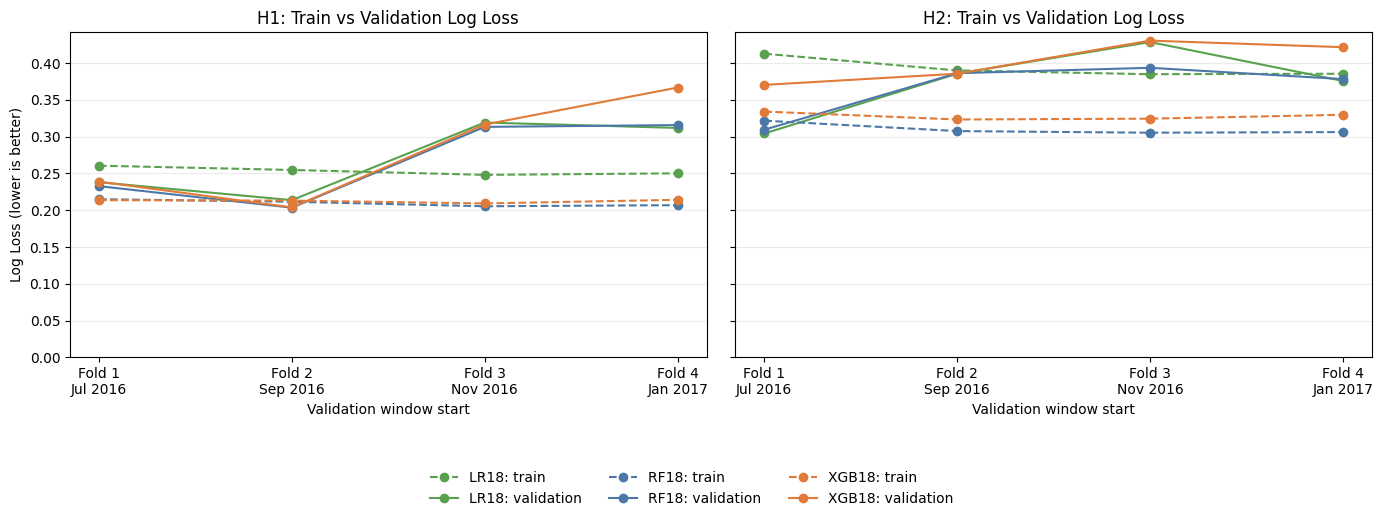

In [40]:
# Align the four models on exactly the same validation bookings
diagnostic_sources = {
    'Dummy': oof_predictions.loc[oof_predictions['Model'].eq('dummy')],
    'LR18': ablation_predictions.loc[
        ablation_predictions['FeatureSet'].eq('core_no_year_month_week')],
    'RF18': rf_predictions,
    'XGB18': xgb_predictions,
}
diagnostic_keys = ['Hotel', 'Booking_ID', 'Fold']
diagnostic_parts = []
for label, source in diagnostic_sources.items():
    part = source[diagnostic_keys + ['PredictionDate', 'IsCanceled', 'RawProbability']].copy()
    if part.duplicated(diagnostic_keys).any():
        raise AssertionError(f'{label}: duplicate OOF bookings')
    part['Model'] = label
    diagnostic_parts.append(part)
diagnostic_oof = pd.concat(diagnostic_parts, ignore_index=True)
reference = diagnostic_sources['Dummy'][
    diagnostic_keys + ['PredictionDate', 'IsCanceled']]
for label, part in diagnostic_oof.groupby('Model'):
    aligned = reference.merge(part, on=diagnostic_keys, how='outer',
                              validate='one_to_one', indicator=True, suffixes=('_ref', ''))
    if (not aligned['_merge'].eq('both').all()
            or not aligned['IsCanceled'].eq(aligned['IsCanceled_ref']).all()
            or not aligned['PredictionDate'].eq(aligned['PredictionDate_ref']).all()
            or not np.isfinite(aligned['RawProbability']).all()
            or not aligned['RawProbability'].between(0, 1).all()):
        raise AssertionError(f'{label}: OOF alignment or probability check failed')
for hotel in config['hotels']:
    expected = cv_memberships[hotel].loc[
        cv_memberships[hotel]['Role'].eq('Validation'), diagnostic_keys]
    actual = reference.loc[reference['Hotel'].eq(hotel), diagnostic_keys]
    matched = expected.merge(actual, on=diagnostic_keys, how='outer',
                             validate='one_to_one', indicator=True)
    if not matched['_merge'].eq('both').all():
        raise AssertionError(f'{hotel}: diagnostics differ from saved validation membership')

# Use consistent labels and colors across the four checks
diagnostic_labels = ['LR18', 'RF18', 'XGB18']
diagnostic_colors = {'Dummy': '#777777', 'LR18': '#59a14f',
                     'RF18': '#4c78a8', 'XGB18': '#e07b39'}

# Select the existing 18-feature pipelines without refitting
diagnostic_models = {
    'LR18': {'name': 'logistic_regression',
             'models': {hotel: {fold: ablation_models[hotel][fold]['core_no_year_month_week']
                                for fold in range(1, 5)} for hotel in config['hotels']},
             'features': ablation_feature_sets['core_no_year_month_week'],
             'params': ablation_model_params,
             'metrics': ablation_metrics.loc[
                 ablation_metrics['FeatureSet'].eq('core_no_year_month_week')]},
    'RF18': {'name': 'random_forest', 'models': rf_models, 'features': rf_feature_config,
             'params': rf_model_params, 'metrics': rf_metrics},
    'XGB18': {'name': 'xgboost', 'models': xgb_models, 'features': xgb_feature_config,
              'params': xgb_model_params, 'metrics': xgb_metrics},
}

# Record fitted preprocessing and model state before and after prediction
def diagnostic_model_state(pipeline, model_name):
    if model_name == 'xgboost':
        return (hashlib.sha256(pickle.dumps(pipeline.named_steps['preprocessor'])).hexdigest(),
                hashlib.sha256(bytes(pipeline.named_steps['model'].get_booster().save_raw())).hexdigest())
    return hashlib.sha256(pickle.dumps(pipeline)).hexdigest()


# Score only the eligible training bookings from each saved CV membership
train_validation_rows = []
train_validation_checks = []
for hotel in config['hotels']:
    membership = cv_memberships[hotel]
    for model_label, settings in diagnostic_models.items():
        columns = [column for group in settings['features'].values() for column in group]
        for fold in range(1, split_config['n_folds'] + 1):
            pipeline = settings['models'][hotel][fold]
            estimator = pipeline.named_steps['model']
            keys = membership.loc[
                membership['Fold'].eq(fold) & membership['Role'].eq('Train'),
                ['Hotel', 'Booking_ID'],
            ]
            train = keys.merge(
                model_data[hotel][['Hotel', 'Booking_ID', config['target']] + columns],
                on=['Hotel', 'Booking_ID'], how='left', validate='one_to_one', indicator=True,
            )
            if train.empty or not train['_merge'].eq('both').all():
                raise ValueError(f'{hotel} {model_label} fold {fold}: unmatched training bookings')
            reference = settings['metrics'].loc[
                settings['metrics']['Hotel'].eq(hotel) & settings['metrics']['Fold'].eq(fold)
            ].iloc[0]
            state_before = diagnostic_model_state(pipeline, settings['name'])
            probabilities = pipeline.predict_proba(train[columns])[
                :, list(estimator.classes_).index(1)
            ].astype(float)
            train_metrics = model_evaluation.evaluate_predictions(train[config['target']], probabilities)

            # Evaluate a constant training-prior prediction on both cohorts
            train_rate = train_metrics['CancelRate']
            dummy_train = model_evaluation.evaluate_predictions(
                train[config['target']], np.full(len(train), train_rate))
            dummy_oof = diagnostic_oof.loc[
                diagnostic_oof['Hotel'].eq(hotel) & diagnostic_oof['Fold'].eq(fold)
                & diagnostic_oof['Model'].eq('Dummy')]
            if not np.allclose(dummy_oof['RawProbability'], train_rate, rtol=0, atol=1e-12):
                raise AssertionError('Dummy OOF probabilities do not match the training prior')
            dummy_valid = model_evaluation.evaluate_predictions(
                dummy_oof['IsCanceled'], dummy_oof['RawProbability'])

            # Verify that scoring preserves the model, inputs and original training cohort
            checks = {
                'Training cohort matches the candidate run':
                    len(train) == reference['TrainRows']
                    and train_metrics['Positives'] == reference['TrainPositives'],
                'Input feature set unchanged': len(columns) == 18
                    and list(pipeline.named_steps['preprocessor'].feature_names_in_) == columns,
                'Model parameters unchanged': all(
                    estimator.get_params()[name] == value for name, value in settings['params'].items()),
                'Fitted pipeline unchanged':
                    diagnostic_model_state(pipeline, settings['name']) == state_before,
            }
            train_validation_checks.extend([
                {'Hotel': hotel, 'Model': model_label, 'Fold': fold, 'Check': name,
                 'Passed': bool(passed)} for name, passed in checks.items()
            ])
            train_validation_rows.append({
                'Hotel': hotel, 'Model': model_label, 'Fold': fold,
                'TrainRows': len(train), 'ValidationRows': int(reference['ValidationRows']),
                'TrainCancelRate': train_metrics['CancelRate'],
                'ValidationCancelRate': reference['ValidationCancelRate'],
                'TrainLogLoss': train_metrics['LogLoss'],
                'ValidationLogLoss': reference['LogLoss'],
                'Gap': reference['LogLoss'] - train_metrics['LogLoss'],
                'DummyTrainLogLoss': dummy_train['LogLoss'],
                'DummyValidationLogLoss': dummy_valid['LogLoss'],
                'TrainGainVsDummy': dummy_train['LogLoss'] - train_metrics['LogLoss'],
                'ValidationGainVsDummy': dummy_valid['LogLoss'] - reference['LogLoss'],
            })
train_validation_scores = pd.DataFrame(train_validation_rows).sort_values(['Hotel', 'Fold', 'Model'])
train_validation_checks = pd.DataFrame(train_validation_checks)
if (len(train_validation_scores) != len(config['hotels']) * len(diagnostic_models) * split_config['n_folds']
        or not train_validation_checks['Passed'].all()):
    display(train_validation_checks.loc[~train_validation_checks['Passed']])
    raise AssertionError('Train-versus-validation diagnostic checks failed')

# Display the Dummy reference beside each model on the same cohort
loss_columns = ['TrainLogLoss', 'DummyTrainLogLoss',
                'ValidationLogLoss', 'DummyValidationLogLoss']
display(train_validation_scores[['Hotel', 'Fold', 'Model'] + loss_columns].style.format(
    {column: '{:.4f}' for column in loss_columns}).hide(axis='index'))
print(f'All {len(train_validation_checks)} cohort and fitted-state checks passed')

# Plot train and validation losses with the same scale for both hotels
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2), sharey=True)
colors = diagnostic_colors
folds = list(range(1, split_config['n_folds'] + 1))
window_labels = [
    f'Fold {fold}\n{(pd.Timestamp(split_config["first_fit_date"]) + pd.DateOffset(months=(fold - 1) * split_config["validation_months"])).strftime("%b %Y")}'
    for fold in folds
]
for ax, hotel in zip(axes, config['hotels']):
    for model_label in diagnostic_models:
        panel = train_validation_scores.loc[
            train_validation_scores['Hotel'].eq(hotel)
            & train_validation_scores['Model'].eq(model_label)
        ].sort_values('Fold')
        ax.plot(panel['Fold'], panel['TrainLogLoss'], color=colors[model_label],
                marker='o', linestyle='--', label=f'{model_label}: train')
        ax.plot(panel['Fold'], panel['ValidationLogLoss'], color=colors[model_label],
                marker='o', linestyle='-', label=f'{model_label}: validation')
    ax.set_title(f'{hotel}: Train vs Validation Log Loss')
    ax.set_xticks(folds, window_labels)
    ax.set_xlabel('Validation window start')
    ax.grid(axis='y', alpha=0.25)
    ax.set_axisbelow(True)
axes[0].set_ylabel('Log Loss (lower is better)')
axes[0].set_ylim(bottom=0)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=3, frameon=False)
fig.tight_layout(rect=[0, 0.16, 1, 1])
plt.show()

**Observation:**

- All three models beat Dummy on train in every window, so they learn information beyond the training cancellation rate. RF18 and XGB18 have much larger train improvements than LR18, but those gains shrink sharply on validation; none improves mean validation Log Loss over Dummy for H2.
- XGB18 has a particularly large train-validation gap in H1 fold 4 (0.214 vs 0.367). This is a warning about generalization, not proof of overfitting alone: cancellation rates and booking characteristics also differ. The results do not establish underfitting.

#### 6.5.2 Cancellation Rate by Window

Does the actual cancellation rate change between eligible train and validation? These rates describe the cohorts used in each fit; they do not isolate calendar effects from label-availability selection.

Hotel,Fold,TrainRows,TrainPositives,ValidationRows,ValidationPositives,TrainRate,ValidationRate
H1,1,"8,618",719,"1,779",115,8.3%,6.5%
H1,2,"10,353",825,"1,936",112,8.0%,5.8%
H1,3,"12,291",945,"1,152",114,7.7%,9.9%
H1,4,"13,631","1,055","1,252",119,7.7%,9.5%
H2,1,"14,230","2,185","3,805",316,15.4%,8.3%
H2,2,"17,962","2,517","3,958",534,14.0%,13.5%
H2,3,"22,069","3,032","2,216",293,13.7%,13.2%
H2,4,"24,605","3,350","2,359",274,13.6%,11.6%


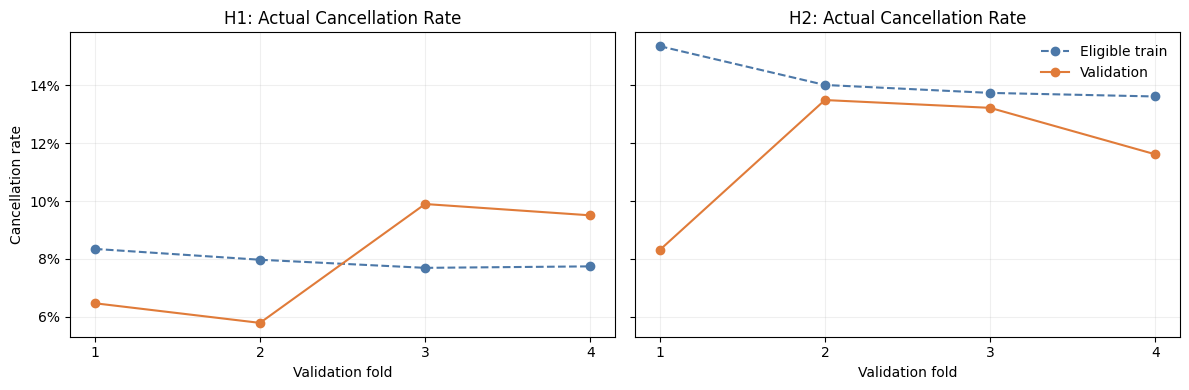

In [41]:
# Select each train and validation cohort from the saved split membership
diagnostic_cohorts, rate_rows = {}, []
for hotel in config['hotels']:
    for fold in range(1, split_config['n_folds'] + 1):
        for role in ['Train', 'Validation']:
            membership = cv_memberships[hotel]
            keys = membership.loc[membership['Fold'].eq(fold) & membership['Role'].eq(role),
                                  ['Hotel', 'Booking_ID']]
            cohort = keys.merge(model_data[hotel], on=['Hotel', 'Booking_ID'],
                                how='left', validate='one_to_one', indicator=True)
            if cohort.empty or not cohort['_merge'].eq('both').all():
                raise AssertionError('Missing bookings in the cohort comparison')
            diagnostic_cohorts[(hotel, fold, role)] = cohort.drop(columns='_merge')
        train = diagnostic_cohorts[(hotel, fold, 'Train')]
        valid = diagnostic_cohorts[(hotel, fold, 'Validation')]
        reference = train_validation_scores.loc[
            train_validation_scores['Hotel'].eq(hotel) & train_validation_scores['Fold'].eq(fold)]
        if (not reference['TrainRows'].eq(len(train)).all()
                or not reference['ValidationRows'].eq(len(valid)).all()):
            raise AssertionError('Rate comparison differs from the scored cohorts')
        rate_rows.append({'Hotel': hotel, 'Fold': fold, 'TrainRows': len(train),
            'TrainPositives': int(train['IsCanceled'].sum()),
            'ValidationRows': len(valid), 'ValidationPositives': int(valid['IsCanceled'].sum()),
            'TrainRate': train['IsCanceled'].mean(), 'ValidationRate': valid['IsCanceled'].mean()})
cohort_rates = pd.DataFrame(rate_rows)

# Keep counts and cancellation rates together
display(cohort_rates.style.format({
    **{column: '{:,}' for column in ['TrainRows', 'TrainPositives', 'ValidationRows', 'ValidationPositives']},
    'TrainRate': '{:.1%}', 'ValidationRate': '{:.1%}',
}).hide(axis='index'))

# Plot only the two observed rates in each hotel
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, hotel in zip(axes, config['hotels']):
    panel = cohort_rates.loc[cohort_rates['Hotel'].eq(hotel)]
    ax.plot(panel['Fold'], panel['TrainRate'], '--o', color='#4c78a8', label='Eligible train')
    ax.plot(panel['Fold'], panel['ValidationRate'], '-o', color='#e07b39', label='Validation')
    ax.set(title=f'{hotel}: Actual Cancellation Rate', xlabel='Validation fold', xticks=[1, 2, 3, 4])
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f'{value:.0%}'))
    ax.grid(alpha=0.2)
axes[0].set_ylabel('Cancellation rate')
axes[1].legend(frameon=False)
fig.tight_layout()
plt.show()

**Observation:**

- **H1:** Validation cancellation rates are below train in folds 1-2, then above train in folds 3-4. A single historical cancellation rate does not represent every future window equally well.
- **H2:** The largest mismatch is fold 1: 15.4% in eligible train versus 8.3% in validation. Later differences are smaller. This supports a cohort base-rate mismatch, while calendar change and label-availability selection remain combined in the comparison.

#### 6.5.3 Predicted Probabilities and Calibration

Do predictions overstate or understate cancellations, overall and within similar-score groups? Curves use up to five groups per model and window; identical scores stay together. Points below the diagonal indicate overprediction.

Hotel,Fold,Rows,Positives,ActualRate,Dummy,LR18,RF18,XGB18
H1,1,"1,779",115,6.5%,8.3%,6.7%,7.3%,7.2%
H1,2,"1,936",112,5.8%,8.0%,7.1%,7.1%,6.4%
H1,3,"1,152",114,9.9%,7.7%,13.4%,12.4%,9.6%
H1,4,"1,252",119,9.5%,7.7%,12.8%,12.8%,17.4%
H2,1,"3,805",316,8.3%,15.4%,15.5%,16.1%,19.2%
H2,2,"3,958",534,13.5%,14.0%,13.6%,14.1%,12.3%
H2,3,"2,216",293,13.2%,13.7%,19.4%,18.1%,18.2%
H2,4,"2,359",274,11.6%,13.6%,18.1%,17.6%,19.3%


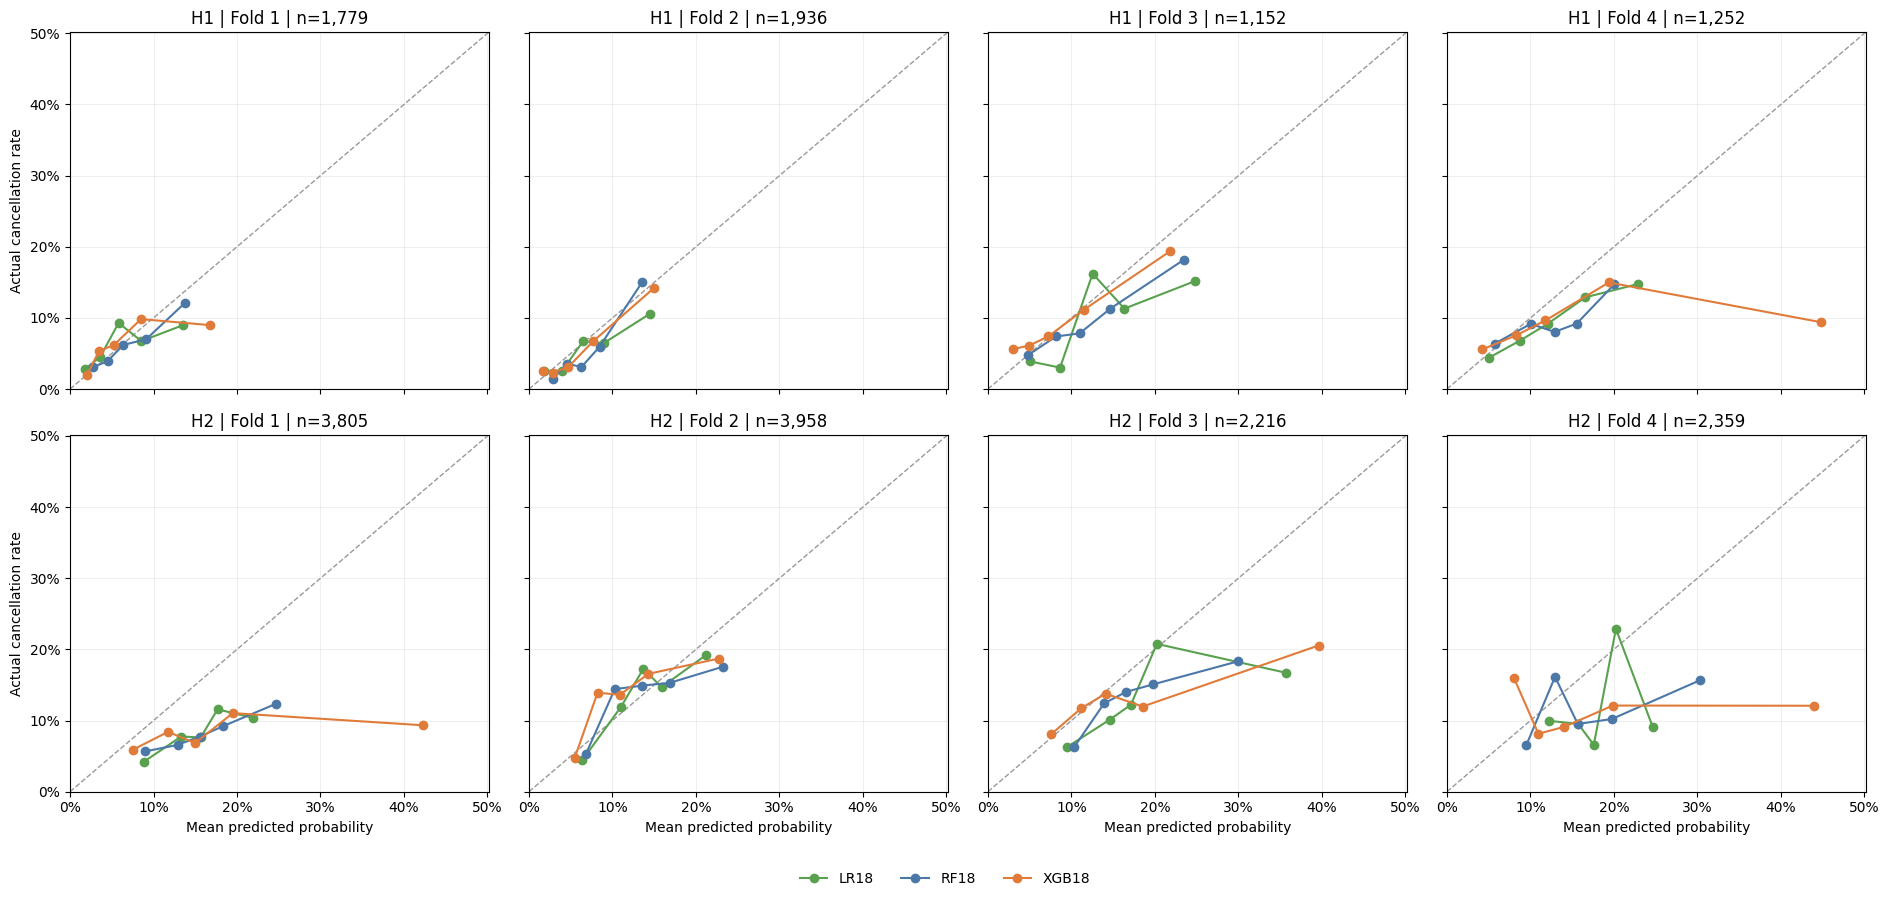

In [42]:
# Summarize observed and predicted cancellation rates without pooling windows
diagnostic_colors = {'Dummy': '#777777', 'LR18': '#59a14f',
                     'RF18': '#4c78a8', 'XGB18': '#e07b39'}
diagnostic_labels = ['LR18', 'RF18', 'XGB18']
probability_rates = diagnostic_oof.groupby(['Hotel', 'Fold', 'Model']).agg(
    Rows=('IsCanceled', 'size'), Positives=('IsCanceled', 'sum'),
    ActualRate=('IsCanceled', 'mean'), MeanProbability=('RawProbability', 'mean'),
).reset_index()
probability_rates['Bias'] = probability_rates['MeanProbability'] - probability_rates['ActualRate']
rate_context = probability_rates.loc[probability_rates['Model'].eq('Dummy'),
    ['Hotel', 'Fold', 'Rows', 'Positives', 'ActualRate']]
rate_display = rate_context.merge(probability_rates.pivot(
    index=['Hotel', 'Fold'], columns='Model', values='MeanProbability').reset_index(),
    on=['Hotel', 'Fold'], validate='one_to_one')
display(rate_display.style.format({
    'Rows': '{:,}', 'Positives': '{:,}',
    **{c: '{:.1%}' for c in ['ActualRate', 'Dummy'] + diagnostic_labels},
}).hide(axis='index'))


# Group similar scores without splitting bookings with identical probabilities
def score_groups(frame, groups=5):
    result = frame.copy()
    scores = result['RawProbability']
    if scores.nunique() == 1:
        result['ScoreGroup'] = 1
    else:
        bins = pd.qcut(scores, q=groups, duplicates='drop')
        if bins.isna().all():
            result['ScoreGroup'] = 1
        else:
            result['ScoreGroup'] = bins.cat.codes + 1
    if (result['ScoreGroup'] < 1).any():
        raise AssertionError('A probability was not assigned to a score group')
    return result

score_group_parts, calibration_parts = [], []
for (hotel, fold, label), frame in diagnostic_oof.groupby(['Hotel', 'Fold', 'Model']):
    assigned = score_groups(frame)
    score_group_parts.append(assigned)
    summary = assigned.groupby('ScoreGroup').agg(
        Rows=('IsCanceled', 'size'), Positives=('IsCanceled', 'sum'),
        MeanProbability=('RawProbability', 'mean'),
        MinProbability=('RawProbability', 'min'), MaxProbability=('RawProbability', 'max'),
    ).reset_index()
    summary['ActualRate'] = summary['Positives'] / summary['Rows']
    summary['Error'] = summary['MeanProbability'] - summary['ActualRate']
    if (summary['Rows'].sum() != len(frame)
            or summary['Positives'].sum() != frame['IsCanceled'].sum()):
        raise AssertionError('Calibration bins do not reconcile with the validation cohort')
    calibration_parts.append(summary.assign(Hotel=hotel, Fold=fold, Model=label))
diagnostic_scored = pd.concat(score_group_parts, ignore_index=True)
calibration_bins = pd.concat(calibration_parts, ignore_index=True)

# Compare each observed frequency with the model's mean probability
fig, axes = plt.subplots(2, 4, figsize=(19, 9), sharex=True, sharey=True)
limit = max(calibration_bins['MeanProbability'].max(), calibration_bins['ActualRate'].max()) * 1.12
for row, hotel in enumerate(config['hotels']):
    for column, fold in enumerate(range(1, 5)):
        ax = axes[row, column]
        ax.plot([0, limit], [0, limit], '--', color='#999999', linewidth=1)
        for label in diagnostic_labels:
            panel = calibration_bins.loc[
                calibration_bins['Hotel'].eq(hotel) & calibration_bins['Fold'].eq(fold)
                & calibration_bins['Model'].eq(label)].sort_values('ScoreGroup')
            ax.plot(panel['MeanProbability'], panel['ActualRate'], marker='o',
                    color=diagnostic_colors[label], label=label)
        context = rate_context.loc[rate_context['Hotel'].eq(hotel)
                                   & rate_context['Fold'].eq(fold)].iloc[0]
        ax.set(title=f'{hotel} | Fold {fold} | n={int(context["Rows"]):,}',
               xlim=(0, limit), ylim=(0, limit))
        ax.grid(alpha=0.2)
        if row == 1:
            ax.set_xlabel('Mean predicted probability')
        if column == 0:
            ax.set_ylabel('Actual cancellation rate')
        ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
        ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=3, frameon=False)
fig.tight_layout(rect=[0, 0.05, 1, 1])
plt.show()

**Observation:**

- **H1:** RF18 overpredicts on average in every window, particularly folds 3-4. XGB18 is close to the overall rate in fold 3 but strongly overpredicts in fold 4; its highest-risk group averages 44.8% predicted against 9.4% observed. The problem therefore extends beyond the overall mean.
- **H2:** All three models overpredict on average in folds 1, 3 and 4, and their highest-risk groups are overpredicted in every fold. Fold 2 is closer overall. Calibration errors vary by model, score range and window; five-bin frequencies describe the observed samples rather than proving a fixed calibration relationship.

#### 6.5.4 Feature Changes by Window

Which inputs change, and do cancellation rates within feature groups also change? Screen all 18 inputs, then inspect EURUSD, LeadTime and the Transient customer group.

Boxplots show the middle 50% and 5th-95th percentile whiskers. G1-G4 use fixed initial-train quartiles with open-ended outer groups. The support table gives bookings/cancellations; absent groups have no rate. These are marginal relationships, not isolated feature effects.

Numeric: absolute mean difference / train SD | Categorical: total variation of category shares


Hotel,Fold,Numeric,Categorical
H1,1,LeadTime (0.47); PartySize (0.46),MarketSegment (0.20); CustomerType (0.17)
H1,2,LeadTime (0.69); PartySize (0.18),MarketSegment (0.15); CustomerType (0.13)
H1,3,EURUSD (2.79); LeadTime (0.51),MarketSegment (0.16); CustomerType (0.08)
H1,4,EURUSD (2.43); LeadTime (0.45),MarketSegment (0.19); CustomerType (0.17)
H2,1,LeadTime (0.64); PartySize (0.63),CustomerType (0.28); MarketSegment (0.27)
H2,2,LeadTime (0.37); EURUSD (0.15),CustomerType (0.20); MarketSegment (0.11)
H2,3,EURUSD (2.84); LeadTime (0.23),CustomerType (0.27); MarketSegment (0.15)
H2,4,EURUSD (2.61); LeadTime (0.42),MarketSegment (0.18); CustomerType (0.16)


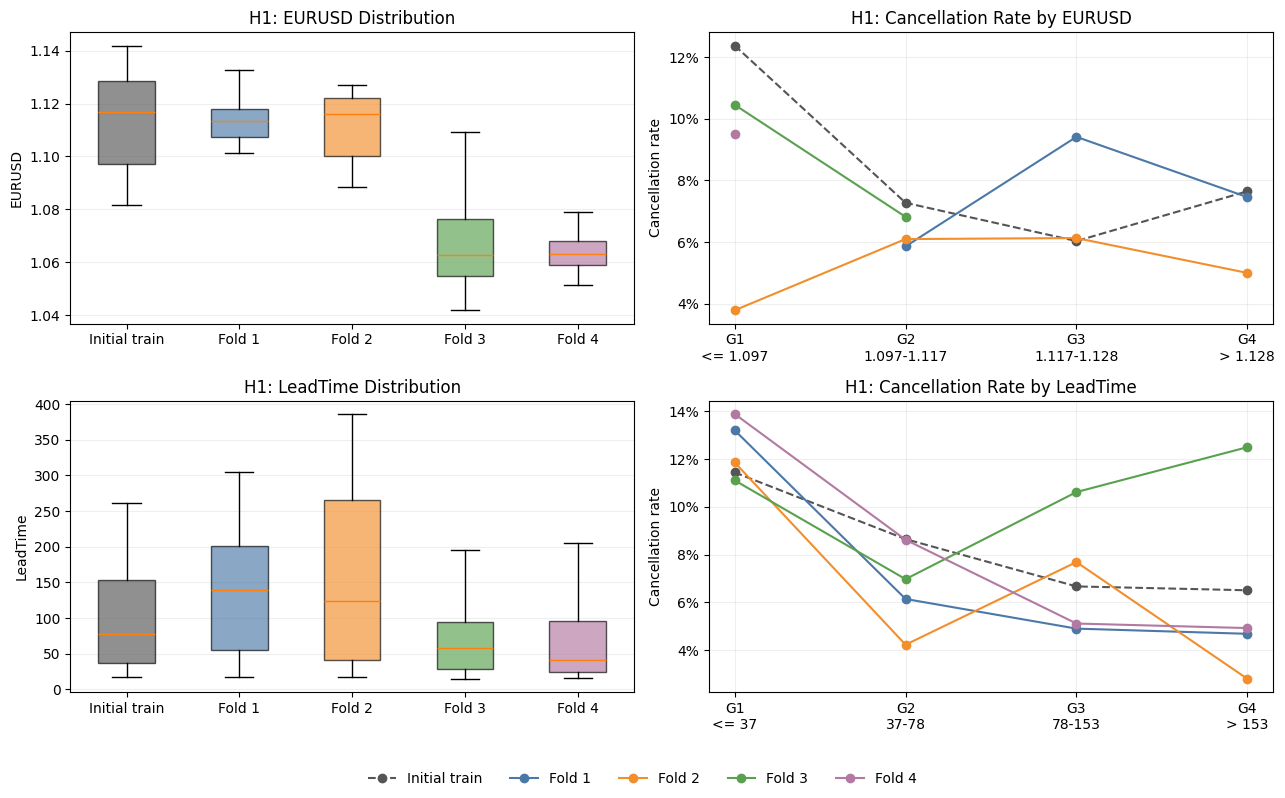

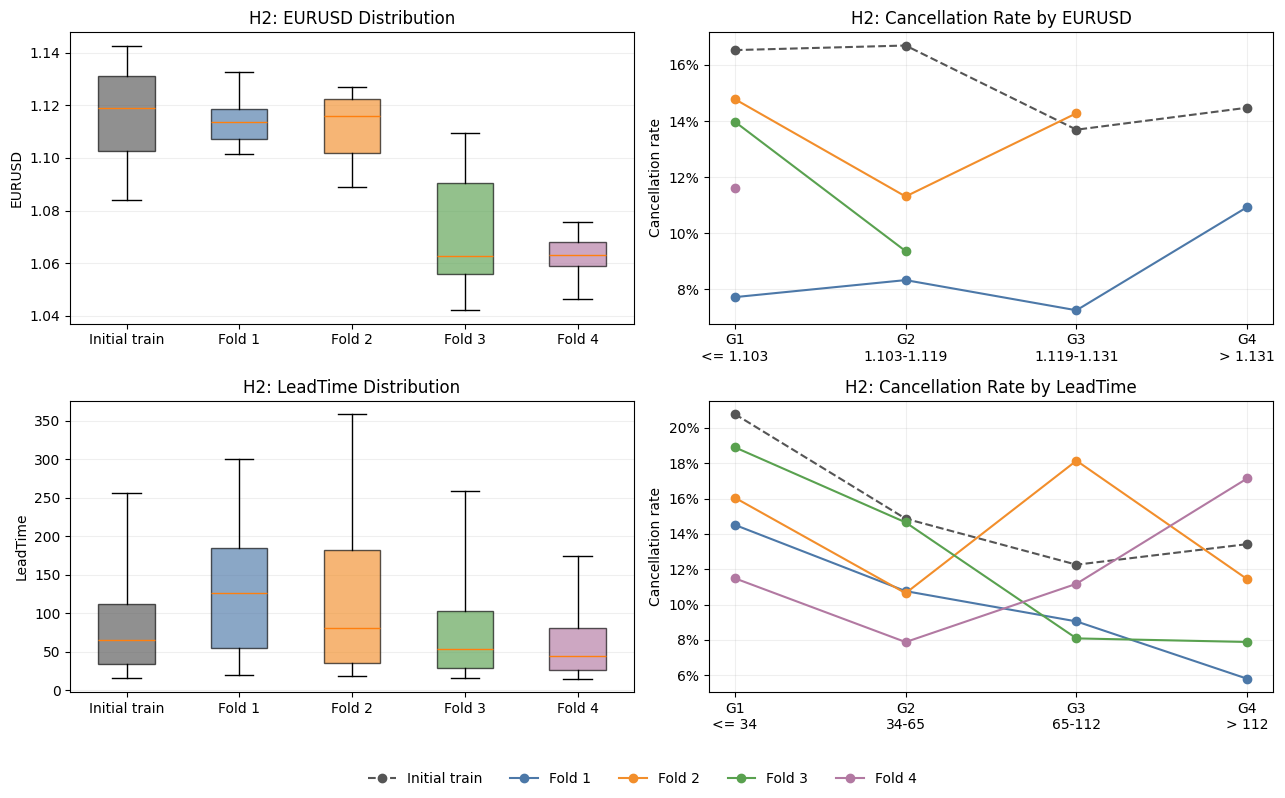

Numeric value-group support: bookings / cancellations


ValueGroup                            G1          G2          G3          G4
Hotel Feature  Window                                                       
H1    EURUSD   Initial train  2182 / 270  2241 / 163  2155 / 130  2040 / 156
               Fold 1              0 / 0   1314 / 77    170 / 16    295 / 22
               Fold 2           264 / 10    820 / 50    832 / 51      20 / 1
               Fold 3          976 / 102    176 / 12       0 / 0       0 / 0
               Fold 4         1252 / 119       0 / 0       0 / 0       0 / 0
      LeadTime Initial train  2202 / 252  2138 / 185  2128 / 142  2150 / 140
               Fold 1           318 / 42    244 / 15    428 / 21    789 / 37
               Fold 2           430 / 51    378 / 16    273 / 21    855 / 24
               Fold 3           423 / 47    344 / 24    273 / 29    112 / 14
               Fold 4           504 / 70    313 / 27    293 / 15     142 / 7
H2    EURUSD   Initial train  3564 / 589  3619 / 604  3579 / 490  3468 / 502
               Fold 1           453 / 35  2412 / 201    620 / 45    320 / 35
               Fold 2         1008 / 149  1220 / 138  1730 / 247       0 / 0
               Fold 3         1853 / 259    363 / 34       0 / 0       0 / 0
               Fold 4         2359 / 274       0 / 0       0 / 0       0 / 0
      LeadTime Initial train  3594 / 747  3580 / 532  3501 / 429  3555 / 477
               Fold 1           510 / 74    660 / 71    564 / 51  2071 / 120
               Fold 2          891 / 143    827 / 88   700 / 127  1540 / 176
               Fold 3          656 / 124    669 / 98    396 / 32    495 / 39
               Fold 4          949 / 109    597 / 47    358 / 40    455 / 78

Transient customer share and cancellation rate


Hotel,Fold,CustomerType,TrainShare,TrainRate,TrainRows,ValidationShare,ValidationRate,ValidationRows
H1,1,Transient,63.2%,8.6%,"5,444",80.1%,7.6%,"1,425"
H1,2,Transient,66.3%,8.3%,"6,867",57.9%,6.8%,"1,120"
H1,3,Transient,64.3%,8.3%,"7,906",68.7%,8.1%,791
H1,4,Transient,65.3%,8.0%,"8,899",54.5%,10.7%,682
H2,1,Transient,46.7%,17.7%,"6,639",74.3%,9.4%,"2,827"
H2,2,Transient,52.8%,15.3%,"9,487",73.0%,15.1%,"2,888"
H2,3,Transient,55.8%,15.1%,"12,305",82.6%,13.0%,"1,831"
H2,4,Transient,59.2%,14.7%,"14,556",75.3%,10.7%,"1,776"


In [43]:
# Screen all 18 features using the matched train and validation cohorts
shift_rows = []
for hotel in config['hotels']:
    for fold in range(1, split_config['n_folds'] + 1):
        train = diagnostic_cohorts[(hotel, fold, 'Train')]
        valid = diagnostic_cohorts[(hotel, fold, 'Validation')]
        for feature in rf_feature_config['numeric']:
            a, b = train[feature].dropna(), valid[feature].dropna()
            difference, scale = abs(b.mean() - a.mean()), a.std(ddof=0)
            shift = difference / scale if scale > 0 else (0 if difference == 0 else np.nan)
            shift_rows.append({'Hotel': hotel, 'Fold': fold, 'Feature': feature,
                              'Type': 'Numeric', 'Shift': shift})
        for feature in rf_feature_config['categorical'] + rf_feature_config['binary']:
            a = train[feature].fillna('__MISSING__').astype(str).value_counts(normalize=True)
            b = valid[feature].fillna('__MISSING__').astype(str).value_counts(normalize=True)
            levels = a.index.union(b.index)
            shift = 0.5 * (a.reindex(levels, fill_value=0) - b.reindex(levels, fill_value=0)).abs().sum()
            shift_rows.append({'Hotel': hotel, 'Fold': fold, 'Feature': feature,
                              'Type': 'Categorical', 'Shift': shift})
feature_shift = pd.DataFrame(shift_rows)
screening_rows = []
for (hotel, fold), panel in feature_shift.groupby(['Hotel', 'Fold']):
    row = {'Hotel': hotel, 'Fold': fold}
    for kind in ['Numeric', 'Categorical']:
        largest = panel.loc[panel['Type'].eq(kind)].nlargest(2, 'Shift')
        row[kind] = '; '.join(f'{item.Feature} ({item.Shift:.2f})' for item in largest.itertuples())
    screening_rows.append(row)
feature_screening = pd.DataFrame(screening_rows)
print('Numeric: absolute mean difference / train SD | Categorical: total variation of category shares')
display(feature_screening.style.hide(axis='index'))

# Build fixed value groups from initial train and retain counts beside rates
detail_features = ['EURUSD', 'LeadTime']
detail_rows, distribution_rows, feature_group_edges = [], [], {}
for hotel in config['hotels']:
    initial_train = diagnostic_cohorts[(hotel, 1, 'Train')]
    cohorts = {'Initial train': initial_train}
    cohorts.update({f'Fold {fold}': diagnostic_cohorts[(hotel, fold, 'Validation')]
                    for fold in range(1, split_config['n_folds'] + 1)})
    for feature in detail_features:
        inner_edges = np.unique(initial_train[feature].quantile([0.25, 0.5, 0.75]).to_numpy())
        edges = np.r_[-np.inf, inner_edges, np.inf]
        feature_group_edges[(hotel, feature)] = edges
        for window, cohort in cohorts.items():
            values = cohort[feature]
            if values.isna().any():
                raise AssertionError(f'{hotel} {feature}: handle missing values before numeric grouping')
            distribution_rows.append({'Hotel': hotel, 'Feature': feature, 'Window': window,
                **{f'Q{int(q * 100)}': values.quantile(q) for q in [0.05, 0.25, 0.5, 0.75, 0.95]}})
            assigned = pd.cut(values, bins=edges, labels=False, include_lowest=True)
            grouped = cohort.assign(ValueGroup=assigned + 1).groupby('ValueGroup').agg(
                Rows=('IsCanceled', 'size'), Positives=('IsCanceled', 'sum'))
            if (grouped['Rows'].sum() != len(cohort)
                    or grouped['Positives'].sum() != cohort['IsCanceled'].sum()):
                raise AssertionError('Numeric feature groups do not reconcile with the cohort')
            grouped = grouped.reindex(range(1, len(edges)), fill_value=0).reset_index()
            grouped['CancelRate'] = grouped['Positives'].div(grouped['Rows'].replace(0, np.nan))
            detail_rows.extend(grouped.assign(Hotel=hotel, Feature=feature, Window=window).to_dict('records'))
numeric_feature_groups = pd.DataFrame(detail_rows)
numeric_distributions = pd.DataFrame(distribution_rows)

# Show distributions and feature-target relationships together for each hotel
window_order = ['Initial train', 'Fold 1', 'Fold 2', 'Fold 3', 'Fold 4']
window_colors = {'Initial train': '#555555', 'Fold 1': '#4c78a8', 'Fold 2': '#f28e2b',
                 'Fold 3': '#59a14f', 'Fold 4': '#b279a2'}
for hotel in config['hotels']:
    fig, axes = plt.subplots(2, 2, figsize=(13, 8))
    for row, feature in enumerate(detail_features):
        initial_train = diagnostic_cohorts[(hotel, 1, 'Train')]
        arrays = [initial_train[feature].to_numpy()] + [
            diagnostic_cohorts[(hotel, fold, 'Validation')][feature].to_numpy() for fold in range(1, 5)]
        boxes = axes[row, 0].boxplot(arrays, tick_labels=window_order, patch_artist=True,
                                    showfliers=False, whis=(5, 95))
        for box, window in zip(boxes['boxes'], window_order):
            box.set_facecolor(window_colors[window])
            box.set_alpha(0.65)
        axes[row, 0].set(title=f'{hotel}: {feature} Distribution', ylabel=feature)
        axes[row, 0].grid(axis='y', alpha=0.2)
        panel = numeric_feature_groups.loc[numeric_feature_groups['Hotel'].eq(hotel)
                                           & numeric_feature_groups['Feature'].eq(feature)]
        for window in window_order:
            selected = panel.loc[panel['Window'].eq(window)].sort_values('ValueGroup')
            axes[row, 1].plot(selected['ValueGroup'], selected['CancelRate'], marker='o',
                linestyle='--' if window == 'Initial train' else '-',
                color=window_colors[window], label=window)
        edges = feature_group_edges[(hotel, feature)]
        if feature == 'LeadTime':
            bounds = [f'{value:g}' for value in edges[1:-1]]
        else:
            bounds = [f'{value:.3f}' for value in edges[1:-1]]
        labels = [f'G1\n<= {bounds[0]}']
        labels += [f'G{i + 1}\n{bounds[i - 1]}-{bounds[i]}' for i in range(1, len(bounds))]
        labels += [f'G{len(edges) - 1}\n> {bounds[-1]}']
        axes[row, 1].set(title=f'{hotel}: Cancellation Rate by {feature}',
                         ylabel='Cancellation rate', xticks=range(1, len(edges)), xticklabels=labels)
        axes[row, 1].yaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f'{value:.0%}'))
        axes[row, 1].grid(alpha=0.2)
    handles, labels = axes[0, 1].get_legend_handles_labels()
    fig.legend(handles, labels, loc='lower center', ncol=5, frameon=False)
    fig.tight_layout(rect=[0, 0.06, 1, 1])
    plt.show()

# Report support so sparse or absent value groups remain visible
support = numeric_feature_groups.copy()
support['Bookings / cancellations'] = support['Rows'].astype(int).astype(str) + ' / ' + support['Positives'].astype(int).astype(str)
numeric_group_support = support.pivot(index=['Hotel', 'Feature', 'Window'],
                                      columns='ValueGroup', values='Bookings / cancellations')
numeric_group_support = numeric_group_support.reindex(
    pd.MultiIndex.from_product([config['hotels'], detail_features, window_order],
                               names=['Hotel', 'Feature', 'Window']))
print('Numeric value-group support: bookings / cancellations')
display(numeric_group_support.rename(columns=lambda group: f'G{group}'))

# Retain one business-group comparison that was prominent in the screening
customer_rows = []
for hotel in config['hotels']:
    for fold in range(1, 5):
        row = {'Hotel': hotel, 'Fold': fold, 'CustomerType': 'Transient'}
        for role in ['Train', 'Validation']:
            cohort = diagnostic_cohorts[(hotel, fold, role)]
            selected = cohort.loc[cohort['CustomerType'].eq('Transient')]
            row[f'{role}Share'] = len(selected) / len(cohort)
            row[f'{role}Rate'] = selected['IsCanceled'].mean()
            row[f'{role}Rows'] = len(selected)
        customer_rows.append(row)
customer_type_comparison = pd.DataFrame(customer_rows)
print('Transient customer share and cancellation rate')
display(customer_type_comparison.style.format({
    **{column: '{:.1%}' for column in ['TrainShare', 'ValidationShare', 'TrainRate', 'ValidationRate']},
    'TrainRows': '{:,}', 'ValidationRows': '{:,}',
}).hide(axis='index'))

**Observation:**

- **EURUSD:** Values move much lower in folds 3-4 for both hotels. All fold-4 bookings fall in the lowest initial-train value group, leaving no observations in the other three groups. This is a clear change in feature coverage; it does not by itself establish that EURUSD harms the model.
- **LeadTime:** Folds 1-2 contain more long-lead bookings, while later windows move toward shorter lead times. Cancellation rates within the same lead-time bands also vary: in H2 fold 4, the longest-lead group has a higher rate than the shortest-lead group, reversing their initial-train ordering.
- **CustomerType:** Transient becomes a larger share of H2 validation in every fold, while its cancellation frequency also changes. Both booking mix and marginal feature-target relationships vary; these comparisons do not isolate a feature's causal effect or decide which inputs to remove.

**Initial Diagnosis Conclusion**

- All three models learn predictive patterns from the training data, but these patterns do not consistently translate into improved probability estimates on future validation windows. The diagnostics reveal substantial generalization gaps, temporal changes in cancellation rates, probability miscalibration, and shifts in feature distributions and observed feature–target relationships.

- These findings suggest that both model configuration and feature stability warrant further investigation. The next development stage will focus on hyperparameter tuning, targeted feature experiments, and probability calibration to improve predictive accuracy and temporal robustness.

### 6.6 Tuning Round 1

#### 6.6.1 Search Config

Tune complexity and regularization on the fixed 18-feature set and four temporal folds. Rank configurations separately for each hotel by equal-weight mean validation Log Loss. Pooled OOF Log Loss is reported separately.

In [44]:
# Define the approved grids and immutable initial references
from datetime import datetime, timezone
from time import perf_counter
from sklearn.model_selection import ParameterGrid
import scipy
import ast

tuning_run_id = 'tuning_round1_v1'
tuning_directory = project_root / 'Model pipeline' / 'reports' / tuning_run_id
tuning_grids = {
    'LR18': {'C': [0.01, 0.1, 1.0, 10.0]},
    'RF18': {'max_depth': [6, 12, None], 'min_samples_leaf': [20, 50, 100]},
    'XGB18': {'max_depth': [2, 3, 4], 'min_child_weight': [5, 20], 'reg_lambda': [1, 10]},
}
tuning_reference_runs = {
    'LR18': 'lr_calendar_ablation_v1', 'RF18': 'rf_initial_v1', 'XGB18': 'xgb_initial_v1',
}
tuning_feature_name = 'core_no_year_month_week'
tuning_features = {group: columns.copy() for group, columns in rf_feature_config.items()}
tuning_columns = [column for columns in tuning_features.values() for column in columns]
tuning_tolerance = 1e-12

# Fingerprint values and complete estimator/preprocessing parameter dictionaries
def tuning_json(value):
    return json.dumps(value, sort_keys=True, default=repr, separators=(',', ':'))


def tuning_hash(value):
    return hashlib.sha256(tuning_json(value).encode('utf-8')).hexdigest()


def tuning_frame_hash(frame):
    ordered = frame.sort_values(['Hotel', 'Booking_ID']).reset_index(drop=True)
    digest = hashlib.sha256(tuning_json({c: str(t) for c, t in ordered.dtypes.items()}).encode())
    digest.update(pd.util.hash_pandas_object(ordered, index=False).to_numpy().tobytes())
    return digest.hexdigest()


tuning_environment = {
    'python': sys.version.split()[0], 'numpy': np.__version__, 'pandas': pd.__version__,
    'scikit_learn': sklearn.__version__, 'scipy': scipy.__version__, 'xgboost': xgboost.__version__,
    'xgboost_distribution': 'xgboost-cpu',
}
tuning_settings, tuning_candidates = {}, []
for label, grid in tuning_grids.items():
    settings = diagnostic_models[label]
    directory = project_root / 'Model pipeline' / 'reports' / tuning_reference_runs[label]
    reference_config = json.loads((directory / 'run_config.json').read_text(encoding='utf-8'))
    reference_features = (reference_config['feature_sets'][tuning_feature_name]
                          if label == 'LR18' else reference_config['feature_config'])
    if (settings['features'] != tuning_features or reference_features != tuning_features
            or reference_config['model_params'] != settings['params']
            or reference_config['evaluation'] != evaluation_config
            or reference_config['split_id'] != split_id
            or reference_config['split_config_sha256'] != hashlib.sha256(
                (split_directory / 'config.json').read_bytes()).hexdigest()
            or any(tuning_environment.get(k) != v for k, v in reference_config['environment'].items())):
        raise AssertionError(f'{label}: initial reference settings differ from the tuning protocol')
    tuning_settings[label] = {**settings, 'directory': directory, 'reference': reference_config}
    for index, grid_params in enumerate(ParameterGrid(grid), start=1):
        parameters = {**settings['params'], **grid_params}
        tuning_candidates.append({
            'ConfigID': f'{label.lower()}_{index:02d}', 'ModelLabel': label,
            'Model': settings['name'], 'Parameters': parameters, 'GridParameters': grid_params,
            'IsInitial': parameters == settings['params'],
        })
if len(tuning_columns) != 18 or len(tuning_candidates) != 25:
    raise AssertionError('Tuning must contain 18 predictors and 25 configurations')
if sum(c['IsInitial'] for c in tuning_candidates) != 3:
    raise AssertionError('Expected exactly one initial configuration per model')

# Record full input cohorts and the files that define fit conditions
tuning_inputs = {}
for (hotel, fold, role), cohort in diagnostic_cohorts.items():
    tuning_inputs[f'{hotel}/fold_{fold}/{role}'] = tuning_frame_hash(cohort)
tuning_source_files = [split_directory / 'config.json']
for hotel in config['hotels']:
    tuning_source_files.extend(split_directory / hotel / filename
        for filename in ['cv_membership.csv', 'fit_eligibility.csv', 'calibration_membership.csv'])
for run in ['baseline_v1'] + list(tuning_reference_runs.values()):
    directory = project_root / 'Model pipeline' / 'reports' / run
    tuning_source_files.append(directory / 'run_config.json')
    for hotel in config['hotels']:
        tuning_source_files.extend(directory / hotel / name for name in ['fold_metrics.csv', 'oof_predictions.csv'])
tuning_notebook = json.loads((project_root / 'Model pipeline' / 'model_train_main.ipynb').read_text(encoding='utf-8'))
# Hash the actual fitting functions and aggregation rules, allowing presentation-only changes
tuning_function_names = {'run_baseline_fold', 'run_candidate_fold', 'diagnostic_model_state',
    'tuning_json', 'tuning_hash', 'tuning_frame_hash', 'read_tuning_table',
    'run_tuning_fold', 'run_tuning_model'}
tuning_function_sources = {}
for cell in tuning_notebook['cells']:
    if cell['cell_type'] != 'code':
        continue
    source = ''.join(cell['source'])
    for node in ast.parse(source).body:
        if isinstance(node, ast.FunctionDef) and node.name in tuning_function_names:
            tuning_function_sources[node.name] = ast.dump(node, include_attributes=False)
    if source.startswith('# Reconcile all 200 evaluations'):
        tuning_aggregation_source = ast.dump(
            ast.parse(source.split('display(tuning_best')[0]), include_attributes=False)
if set(tuning_function_sources) != tuning_function_names:
    raise AssertionError('Missing fitting function provenance')
tuning_protocol = {
    'run_id': tuning_run_id, 'split_id': split_id, 'feature_set': tuning_feature_name,
    'feature_config': tuning_features, 'grids': tuning_grids, 'candidates': tuning_candidates,
    'evaluation': evaluation_config, 'pooled_log_loss': 'observation_weighted_OOF_log_loss',
    'selection': 'minimum_equal_weight_mean_LogLoss_per_hotel_and_model',
    'expected_evaluations': 200, 'expected_initial_reuses': 24, 'expected_new_fits': 176,
    'replay_absolute_tolerance': tuning_tolerance, 'environment': tuning_environment,
    'input_cohort_sha256': tuning_inputs,
    'source_sha256': {p.relative_to(project_root).as_posix(): hashlib.sha256(p.read_bytes()).hexdigest()
                      for p in tuning_source_files},
    'code_sha256': {filename: hashlib.sha256(
        (project_root / 'Model pipeline' / filename).read_bytes()).hexdigest()
        for filename in ['utils/model_pipeline.py', 'utils/model_evaluation.py', 'utils/model_split.py']},
    'fitting_functions_sha256': tuning_hash(tuning_function_sources),
    'aggregation_sha256': tuning_hash(tuning_aggregation_source),
}

# Restore an identical completed round instead of fitting it again
def read_tuning_table(relative_path, saved_config):
    schema = saved_config['output_schema'][relative_path]
    result = pd.read_csv(tuning_directory / relative_path,
        dtype={c: dtype for c, dtype in schema['dtypes'].items() if c not in schema['date_columns']},
        parse_dates=schema['date_columns'], keep_default_na=False, float_precision='round_trip')
    for column in schema['date_columns']:
        result[column] = result[column].astype(schema['dtypes'][column])
    return result


tuning_saved_config, tuning_saved_tables = None, {}
if (tuning_directory / 'run_config.json').exists():
    tuning_saved_config = json.loads((tuning_directory / 'run_config.json').read_text(encoding='utf-8'))
    if tuning_saved_config['protocol'] != tuning_protocol:
        raise FileExistsError('Tuning conditions changed; use a new tuning_run_id')
    for name, digest in tuning_saved_config['output_sha256'].items():
        if hashlib.sha256((tuning_directory / name).read_bytes()).hexdigest() != digest:
            raise AssertionError(f'Tuning artifact changed: {name}')
        tuning_saved_tables[name] = read_tuning_table(name, tuning_saved_config)
tuning_metric_parts, tuning_prediction_parts, tuning_log_parts = [], [], []
tuning_prototype_results = {}
display(pd.DataFrame([{'Model': label, 'Grid': tuning_json(grid),
                      'Configurations': len(list(ParameterGrid(grid)))}
                     for label, grid in tuning_grids.items()]).style.hide(axis='index'))
print('25 configurations | 200 evaluations | 24 initial reuses | 176 new fits')

Model,Grid,Configurations
LR18,"{""C"":[0.01,0.1,1.0,10.0]}",4
RF18,"{""max_depth"":[6,12,null],""min_samples_leaf"":[20,50,100]}",9
XGB18,"{""max_depth"":[2,3,4],""min_child_weight"":[5,20],""reg_lambda"":[1,10]}",12


25 configurations | 200 evaluations | 24 initial reuses | 176 new fits


#### 6.6.2 Fit and Check One LR Configuration

Check H1 fold 1 at C=0.01 before running the full search. Each evaluation verifies the complete model parameters, preprocessing, saved membership and unchanged fitted state during prediction.

In [45]:
# Load frozen references with their original identifiers and dates
tuning_initial_metrics, tuning_initial_predictions = {}, {}
tuning_dummy = fold_metrics.loc[fold_metrics['Model'].eq('dummy')].copy()
for label, settings in tuning_settings.items():
    metrics = pd.concat([pd.read_csv(settings['directory'] / hotel / 'fold_metrics.csv',
        parse_dates=['FitDate', 'ValidationStart', 'ValidationEnd'], float_precision='round_trip')
        for hotel in config['hotels']], ignore_index=True)
    predictions = pd.concat([pd.read_csv(settings['directory'] / hotel / 'oof_predictions.csv',
        dtype={'Hotel': str, 'Booking_ID': str}, parse_dates=['PredictionDate'],
        float_precision='round_trip') for hotel in config['hotels']], ignore_index=True)
    if label == 'LR18':
        metrics = metrics.loc[metrics['FeatureSet'].eq(tuning_feature_name)].copy()
        predictions = predictions.loc[predictions['FeatureSet'].eq(tuning_feature_name)].copy()
    tuning_initial_metrics[label] = metrics
    tuning_initial_predictions[label] = predictions


# Evaluate a fresh fit or a fully matched initial pipeline
def run_tuning_fold(candidate, hotel, fold):
    started = perf_counter()
    started_utc = datetime.now(timezone.utc).isoformat()
    label, parameters = candidate['ModelLabel'], candidate['Parameters']
    settings = tuning_settings[label]
    train = diagnostic_cohorts[(hotel, fold, 'Train')]
    valid = diagnostic_cohorts[(hotel, fold, 'Validation')]
    reference_metrics = tuning_initial_metrics[label].loc[
        tuning_initial_metrics[label]['Hotel'].eq(hotel)
        & tuning_initial_metrics[label]['Fold'].eq(fold)].iloc[0]
    checks = {}
    if candidate['IsInitial']:
        pipeline = settings['models'][hotel][fold]
        prediction = tuning_initial_predictions[label].loc[
            tuning_initial_predictions[label]['Hotel'].eq(hotel)
            & tuning_initial_predictions[label]['Fold'].eq(fold)].copy()
        row = reference_metrics.to_dict()
        source = 'reused_initial'
    else:
        result = run_candidate_fold(hotel, fold, settings['name'], tuning_feature_name,
                                    tuning_features, parameters)
        pipeline, prediction, row = result['pipeline'], result['predictions'], result['metrics']
        checks.update({f'Fit: {item.Check}': item.Passed for item in result['checks'].itertuples()})
        source = 'new_fit'

    # Compare all effective estimator parameters and preprocessing settings
    expected = model_pipeline.build_pipeline(settings['name'], tuning_features, parameters)
    preprocessor, estimator = pipeline.named_steps['preprocessor'], pipeline.named_steps['model']
    checks['Full estimator parameters match'] = (
        type(estimator) is type(expected.named_steps['model'])
        and tuning_json(estimator.get_params(deep=True)) == tuning_json(expected.named_steps['model'].get_params(deep=True)))
    checks['Full preprocessing parameters match'] = (
        tuning_json(preprocessor.get_params(deep=True))
        == tuning_json(expected.named_steps['preprocessor'].get_params(deep=True)))
    checks['Only the fixed inputs are processed'] = list(preprocessor.feature_names_in_) == tuning_columns
    numeric = preprocessor.named_transformers_['numeric']
    checks['Numeric imputer uses this train'] = np.allclose(
        numeric.named_steps['imputer'].statistics_, train[tuning_features['numeric']].median())
    checks['Scaling follows the model protocol'] = ('scaler' in numeric.named_steps) == (label == 'LR18')
    if label == 'LR18':
        scaler = numeric.named_steps['scaler']
        checks['Scaler statistics use this train'] = (
            np.all(scaler.n_samples_seen_ == len(train))
            and np.allclose(scaler.mean_, train[tuning_features['numeric']].mean())
            and np.allclose(scaler.var_, train[tuning_features['numeric']].var(ddof=0)))
    encoder = preprocessor.named_transformers_['categorical'].named_steps['encoder']
    checks['Encoder vocabulary uses this train'] = all(
        np.array_equal(categories, np.sort(train[column].fillna('__MISSING__').unique()))
        for column, categories in zip(tuning_features['categorical'], encoder.categories_))
    checks['Binary imputer uses this train'] = np.array_equal(
        preprocessor.named_transformers_['binary'].named_steps['imputer'].statistics_,
        train[tuning_features['binary']].mode().iloc[0].to_numpy())

    # Reconcile dates, labels and counts before reusing or evaluating predictions
    aligned = valid[['Hotel', 'Booking_ID', 'CutoffDate', 'IsCanceled']].merge(
        prediction, on=['Hotel', 'Booking_ID'], how='left', validate='one_to_one',
        suffixes=('_gold', ''), indicator=True)
    fit_date = pd.Timestamp(reference_metrics['FitDate'])
    checks['OOF bookings, labels and dates match membership'] = (
        len(aligned) == len(prediction) and aligned['_merge'].eq('both').all()
        and aligned['IsCanceled'].eq(aligned['IsCanceled_gold']).all()
        and aligned['PredictionDate'].eq(aligned['CutoffDate']).all()
        and aligned['Fold'].eq(fold).all())
    checks['Fit and validation boundaries match'] = (
        pd.Timestamp(row['FitDate']) == fit_date
        and pd.Timestamp(row['ValidationStart']) == fit_date
        and pd.Timestamp(row['ValidationEnd']) == pd.Timestamp(reference_metrics['ValidationEnd'])
        and valid['CutoffDate'].ge(fit_date).all()
        and valid['CutoffDate'].lt(pd.Timestamp(row['ValidationEnd'])).all()
        and train['CutoffDate'].lt(fit_date).all())
    checks['Training cohort size and labels match reference'] = (
        row['TrainRows'] == len(train) and row['TrainPositives'] == int(train['IsCanceled'].sum()))
    eligibility = split_results[hotel]['fit_eligibility']
    eligible = eligibility.loc[eligibility['Stage'].eq('CV')
        & eligibility['Fold'].eq(fold).fillna(False) & eligibility['Eligible']]
    checks['Training keys and label maturity match'] = (
        set(train['Booking_ID']) == set(eligible['Booking_ID'])
        and eligible['LabelAvailableDate'].lt(fit_date).all())
    checks['Test excluded from evaluation'] = valid['CutoffDate'].lt(pd.Timestamp(split_config['test_start'])).all()

    # Verify frozen OOF replay and calculate in-sample metrics without refitting
    state_before = diagnostic_model_state(pipeline, settings['name'])
    class_index = list(estimator.classes_).index(1)
    replay = pipeline.predict_proba(valid[tuning_columns])[:, class_index].astype(float)
    checks['Pipeline reproduces the OOF predictions'] = np.allclose(
        replay, aligned['RawProbability'].to_numpy(dtype=float), rtol=0, atol=tuning_tolerance)
    train_probabilities = pipeline.predict_proba(train[tuning_columns])[:, class_index].astype(float)
    train_scores = model_evaluation.evaluate_predictions(train['IsCanceled'], train_probabilities)
    valid_scores = model_evaluation.evaluate_predictions(valid['IsCanceled'], replay)
    checks['All validation metrics reconcile'] = all(np.isclose(
        valid_scores[metric], row[metric], rtol=0, atol=tuning_tolerance) for metric in metric_columns)
    checks['Scoring preserves fitted state'] = diagnostic_model_state(pipeline, settings['name']) == state_before
    if not all(checks.values()):
        raise AssertionError(f'{hotel} {candidate["ConfigID"]} fold {fold}: '
                             + '; '.join(name for name, passed in checks.items() if not passed))

    # Return compact metrics, keyed OOF and a traceable evaluation log
    dummy = tuning_dummy.loc[tuning_dummy['Hotel'].eq(hotel) & tuning_dummy['Fold'].eq(fold)].iloc[0]
    common = ['Hotel', 'Model', 'FeatureSet', 'Fold', 'FitDate', 'ValidationStart', 'ValidationEnd',
              'TrainRows', 'TrainPositives', 'TrainCancelRate', 'ValidationRows',
              'ValidationPositives', 'ValidationCancelRate', 'InputColumns', 'ProcessedColumns']
    metric_row = {key: row[key] for key in common}
    metric_row.update({metric: valid_scores[metric] for metric in metric_columns})
    metric_row.update({f'Train{metric}': train_scores[metric] for metric in metric_columns})
    metric_row.update({'ConfigID': candidate['ConfigID'], 'ModelLabel': label,
        'IsInitial': candidate['IsInitial'], 'Source': source,
        'DummyLogLoss': dummy['LogLoss'], 'InitialLogLoss': reference_metrics['LogLoss'],
        'GainVsDummy': dummy['LogLoss'] - valid_scores['LogLoss'],
        'GainVsInitial': reference_metrics['LogLoss'] - valid_scores['LogLoss'],
        'GeneralizationGap': valid_scores['LogLoss'] - train_scores['LogLoss']})
    prediction = prediction[['Hotel', 'Booking_ID', 'Model', 'FeatureSet', 'Fold',
                             'PredictionDate', 'IsCanceled', 'RawProbability']].copy()
    prediction['ConfigID'], prediction['ModelLabel'] = candidate['ConfigID'], label
    log = {'Hotel': hotel, 'ModelLabel': label, 'ConfigID': candidate['ConfigID'], 'Fold': fold,
        'Source': source, 'Status': 'PASS', 'StartedUTC': started_utc,
        'FinishedUTC': datetime.now(timezone.utc).isoformat(), 'EvaluationSeconds': perf_counter() - started,
        'ChecksPassed': len(checks), 'ParameterSHA256': tuning_hash(parameters),
        'EffectiveEstimatorSHA256': tuning_hash(estimator.get_params(deep=True)),
        'PreprocessingSHA256': tuning_hash(preprocessor.get_params(deep=True)),
        'FittedStateSHA256': tuning_hash(diagnostic_model_state(pipeline, settings['name'])),
        'TrainInputSHA256': tuning_inputs[f'{hotel}/fold_{fold}/Train'],
        'ValidationInputSHA256': tuning_inputs[f'{hotel}/fold_{fold}/Validation'],
        'InitialReference': tuning_reference_runs[label],
        'FitChecksPassed': len(result['checks']) if source == 'new_fit' else 0,
        'Iterations': int(row.get('Iterations', 0)),
        'ObservedTreeDepth': int(row.get('MaxTreeDepth', 0))}
    return metric_row, prediction, log


# Prototype the first new LR configuration and reuse it in the full search
prototype_candidate = next(c for c in tuning_candidates if c['ModelLabel'] == 'LR18' and not c['IsInitial'])
if tuning_saved_config is None:
    prototype_key = (prototype_candidate['ConfigID'], 'H1', 1)
    tuning_prototype_results[prototype_key] = run_tuning_fold(prototype_candidate, 'H1', 1)
    prototype_row = tuning_prototype_results[prototype_key][0]
    display(pd.DataFrame([prototype_row])[
        ['Hotel', 'ConfigID', 'Fold', 'TrainRows', 'ValidationRows', 'TrainLogLoss'] + metric_columns
    ].style.format({key: '{:.4f}' for key in metric_columns + ['TrainLogLoss']}).hide(axis='index'))
    print('Prototype passed; this result will be reused in the LR search')
else:
    print('Verified completed round found; restore its evaluations')

Verified completed round found; restore its evaluations


#### 6.6.3 Run Temporal Grid Search

Run LR18, RF18 and XGB18 in order. All configurations use the same eligible training bookings and validation windows.

In [46]:
# Run one model grid and retain metrics, OOF and logs without storing every fitted model
def run_tuning_model(model_label):
    if tuning_saved_config is not None:
        for hotel in config['hotels']:
            for filename, target in [('fold_metrics.csv', tuning_metric_parts),
                                     ('oof_predictions.csv', tuning_prediction_parts),
                                     ('experiment_log.csv', tuning_log_parts)]:
                table = tuning_saved_tables[f'{hotel}/{filename}']
                target.append(table.loc[table['ModelLabel'].eq(model_label)].copy())
        print(f'{model_label}: restored verified evaluations', flush=True)
        return
    candidates = [c for c in tuning_candidates if c['ModelLabel'] == model_label]
    for index, candidate in enumerate(candidates, start=1):
        metrics, predictions, logs = [], [], []
        for hotel in config['hotels']:
            for fold in range(1, split_config['n_folds'] + 1):
                key = (candidate['ConfigID'], hotel, fold)
                result = tuning_prototype_results.pop(key) if key in tuning_prototype_results else run_tuning_fold(candidate, hotel, fold)
                metrics.append(result[0])
                predictions.append(result[1])
                logs.append(result[2])
        tuning_metric_parts.append(pd.DataFrame(metrics))
        tuning_prediction_parts.append(pd.concat(predictions, ignore_index=True))
        tuning_log_parts.append(pd.DataFrame(logs))
        print(f'{model_label} {index}/{len(candidates)}: {candidate["ConfigID"]} | '
              f'{tuning_json(candidate["GridParameters"])} | {logs[0]["Source"]}', flush=True)


# Complete each model before moving to the next grid
run_tuning_model('LR18')

LR18: restored verified evaluations


In [47]:
# Run the Random Forest grid on the same folds
run_tuning_model('RF18')

RF18: restored verified evaluations


In [48]:
# Run the XGBoost grid on the same folds
run_tuning_model('XGB18')

XGB18: restored verified evaluations


**Observation:** All 200 configuration-hotel-fold evaluations pass: 176 new fits and 24 matched initial reuses. Every configuration has the same validation bookings, labels and dates. A completed round is restored only when the fitting protocol, inputs, source references and output hashes match.

#### 6.6.4 Audit and Rank Configurations

Rank by the unweighted mean of four validation Log Loss values. Positive gains mean lower Log Loss than the reference. Worst-window excess is the largest model-minus-Dummy loss in any window.

In [49]:
# Reconcile all 200 evaluations and booking-level OOF outputs
tuning_metrics = pd.concat(tuning_metric_parts, ignore_index=True).sort_values(
    ['Hotel', 'ModelLabel', 'ConfigID', 'Fold']).reset_index(drop=True)
tuning_predictions = pd.concat(tuning_prediction_parts, ignore_index=True).sort_values(
    ['Hotel', 'ModelLabel', 'ConfigID', 'Fold', 'Booking_ID']).reset_index(drop=True)
tuning_logs = pd.concat(tuning_log_parts, ignore_index=True).sort_values(
    ['Hotel', 'ModelLabel', 'ConfigID', 'Fold']).reset_index(drop=True)
if (len(tuning_metrics) != 200 or len(tuning_logs) != 200
        or tuning_metrics.duplicated(['Hotel', 'ConfigID', 'Fold']).any()
        or tuning_predictions.duplicated(['Hotel', 'ConfigID', 'Booking_ID']).any()
        or not tuning_logs['Status'].eq('PASS').all()
        or tuning_logs['Source'].value_counts().to_dict() != {'new_fit': 176, 'reused_initial': 24}):
    raise AssertionError('Tuning evaluation counts, reuse counts or keys do not match the protocol')

# Calculate fold means and pooled OOF separately for every hotel and configuration
summary_rows = []
for (hotel, config_id), windows in tuning_metrics.groupby(['Hotel', 'ConfigID']):
    windows = windows.sort_values('Fold')
    candidate = next(c for c in tuning_candidates if c['ConfigID'] == config_id)
    if windows['Fold'].tolist() != [1, 2, 3, 4]:
        raise AssertionError('Every configuration requires exactly four temporal windows')
    oof = tuning_predictions.loc[tuning_predictions['Hotel'].eq(hotel)
                                  & tuning_predictions['ConfigID'].eq(config_id)]
    expected = diagnostic_oof.loc[diagnostic_oof['Hotel'].eq(hotel)
                                  & diagnostic_oof['Model'].eq('Dummy')]
    matched = expected[['Hotel', 'Booking_ID', 'Fold', 'PredictionDate', 'IsCanceled']].merge(
        oof, on=['Hotel', 'Booking_ID'], how='outer', validate='one_to_one',
        indicator=True, suffixes=('_expected', ''))
    if (not matched['_merge'].eq('both').all()
            or not all(matched[key].eq(matched[f'{key}_expected']).all()
                       for key in ['Fold', 'PredictionDate', 'IsCanceled'])):
        raise AssertionError(f'{hotel} {config_id}: OOF membership or labels differ')
    for fold, predictions in oof.groupby('Fold'):
        measured = model_evaluation.evaluate_predictions(predictions['IsCanceled'], predictions['RawProbability'])
        reference = windows.loc[windows['Fold'].eq(fold)].iloc[0]
        if (measured['Rows'] != reference['ValidationRows']
                or measured['Positives'] != reference['ValidationPositives']
                or not all(np.isclose(measured[m], reference[m], rtol=0, atol=tuning_tolerance) for m in metric_columns)):
            raise AssertionError('Saved fold metrics do not match the OOF predictions')
    pooled = model_evaluation.evaluate_predictions(oof['IsCanceled'], oof['RawProbability'])
    weighted = np.average(windows['LogLoss'], weights=windows['ValidationRows'])
    if not np.isclose(pooled['LogLoss'], weighted, rtol=0, atol=tuning_tolerance):
        raise AssertionError('Pooled Log Loss differs from the observation-weighted fold losses')
    worst = windows.loc[windows['LogLoss'].idxmax()]
    excess = windows['LogLoss'] - windows['DummyLogLoss']
    worst_excess = windows.loc[excess.idxmax()]
    summary = {'Hotel': hotel, 'ModelLabel': candidate['ModelLabel'], 'ConfigID': config_id,
        'IsInitial': candidate['IsInitial'], 'GridParameters': tuning_json(candidate['GridParameters']),
        'ValidationRows': int(windows['ValidationRows'].sum()),
        'ValidationPositives': int(windows['ValidationPositives'].sum()),
        'MeanTrainLogLoss': windows['TrainLogLoss'].mean(),
        'MeanGap': windows['GeneralizationGap'].mean(),
        'LogLossSD': windows['LogLoss'].std(ddof=0),
        'DummyLogLoss': windows['DummyLogLoss'].mean(),
        'InitialLogLoss': windows['InitialLogLoss'].mean(),
        'GainVsDummy': windows['GainVsDummy'].mean(), 'GainVsInitial': windows['GainVsInitial'].mean(),
        'FoldsBeatingDummy': int((windows['GainVsDummy'] > tuning_tolerance).sum()),
        'FoldsBeatingInitial': int((windows['GainVsInitial'] > tuning_tolerance).sum()),
        'WorstFold': int(worst['Fold']), 'WorstLogLoss': worst['LogLoss'],
        'WorstExcessFold': int(worst_excess['Fold']), 'WorstExcessVsDummy': excess.max(),
        'PooledOOFLogLoss': pooled['LogLoss'],
        **{metric: windows[metric].mean() for metric in metric_columns},
    }
    summary_rows.append(summary)
tuning_summary = pd.DataFrame(summary_rows).sort_values(
    ['Hotel', 'ModelLabel', 'LogLoss', 'ConfigID'], kind='stable').reset_index(drop=True)
tuning_summary['RankWithinModel'] = tuning_summary.groupby(['Hotel', 'ModelLabel']).cumcount() + 1
tuning_summary['BestWithinModel'] = tuning_summary['RankWithinModel'].eq(1)
tuning_best = tuning_summary.loc[tuning_summary['BestWithinModel']].copy()
display(tuning_best[['Hotel', 'ModelLabel', 'ConfigID', 'GridParameters', 'LogLoss',
                     'InitialLogLoss', 'DummyLogLoss', 'FoldsBeatingDummy', 'PooledOOFLogLoss']]
    .style.format({column: '{:.4f}' for column in ['LogLoss', 'InitialLogLoss', 'DummyLogLoss', 'PooledOOFLogLoss']})
    .hide(axis='index'))
# Show close alternatives for review without changing the primary ranking
display(tuning_summary.loc[tuning_summary['RankWithinModel'].le(3),
    ['Hotel', 'ModelLabel', 'RankWithinModel', 'ConfigID', 'LogLoss',
     'FoldsBeatingDummy', 'WorstExcessVsDummy']].style.format({
         'LogLoss': '{:.6f}', 'WorstExcessVsDummy': '{:+.6f}'}).hide(axis='index'))
print('PASS: 200 evaluations | 24 reused initial fits | 176 new fits | '
      f'{len(tuning_predictions):,} aligned OOF rows | all metrics reconcile')

Hotel,ModelLabel,ConfigID,GridParameters,LogLoss,InitialLogLoss,DummyLogLoss,FoldsBeatingDummy,PooledOOFLogLoss
H1,LR18,lr18_02,"{""C"":0.1}",0.2691,0.2707,0.2772,4,0.2592
H1,RF18,rf18_07,"{""max_depth"":null,""min_samples_leaf"":20}",0.2663,0.2663,0.2772,4,0.2556
H1,XGB18,xgb18_04,"{""max_depth"":2,""min_child_weight"":20,""reg_lambda"":10}",0.2693,0.2815,0.2772,3,0.2586
H2,LR18,lr18_01,"{""C"":0.01}",0.3651,0.3736,0.3640,2,0.3603
H2,RF18,rf18_02,"{""max_depth"":6,""min_samples_leaf"":50}",0.3595,0.3670,0.3640,4,0.3560
H2,XGB18,xgb18_04,"{""max_depth"":2,""min_child_weight"":20,""reg_lambda"":10}",0.3799,0.4021,0.3640,1,0.3749


Hotel,ModelLabel,RankWithinModel,ConfigID,LogLoss,FoldsBeatingDummy,WorstExcessVsDummy
H1,LR18,1,lr18_02,0.269074,4,-0.004957
H1,LR18,2,lr18_01,0.269723,4,-0.005138
H1,LR18,3,lr18_03,0.270738,4,-0.003961
H1,RF18,1,rf18_07,0.266339,4,-0.000293
H1,RF18,2,rf18_01,0.266659,4,-0.000690
H1,RF18,3,rf18_05,0.266989,4,-0.000754
H1,XGB18,1,xgb18_04,0.269298,3,+0.000225
H1,XGB18,2,xgb18_03,0.269465,3,+0.000108
H1,XGB18,3,xgb18_08,0.270536,3,+0.007294
H2,LR18,1,lr18_01,0.365110,2,+0.013075


PASS: 200 evaluations | 24 reused initial fits | 176 new fits | 461,425 aligned OOF rows | all metrics reconcile


**Observation:**

- **H1:** The lowest mean Log Loss within each grid is LR18 at C=0.1, RF18 at its initial configuration, and XGB18 at depth=2, child weight=20, lambda=10. RF18 remains best overall at 0.2663.
- **H2:** The grid winners are LR18 at C=0.01, RF18 at depth=6 and leaf size=50, and XGB18 at depth=2, child weight=20, lambda=10. RF18 is best overall at 0.3595. RF leaf sizes 50 and 100 are very close (0.359526 vs 0.359564); the primary ranking retains leaf size 50 without claiming that this small difference is conclusive.
- Pooled OOF Log Loss differs from the equal-weight fold mean because window sizes differ. Selection uses the fold mean throughout.

#### 6.6.5 Compare Performance and Generalization

Compare each model's winning configuration with its initial reference and Dummy. Review probability metrics, ranking, train-validation gaps and gains in every window; no near-tie stability override is applied.

Hotel,ModelLabel,ConfigID,LogLoss,BrierScore,ROC_AUC,AveragePrecision,MeanTrainLogLoss,MeanGap,GainVsInitial,FoldsBeatingDummy,WorstExcessVsDummy
H1,LR18,lr18_02,0.2691,0.0722,0.6445,0.1306,0.2543,0.0148,0.0017,4,-0.0050
H1,RF18,rf18_07,0.2663,0.0716,0.6574,0.1504,0.2097,0.0567,0.0000,4,-0.0003
H1,XGB18,xgb18_04,0.2693,0.0728,0.6498,0.1346,0.2340,0.0353,0.0122,3,0.0002
H2,LR18,lr18_01,0.3651,0.1050,0.5855,0.1457,0.3968,-0.0317,0.0085,2,0.0131
H2,RF18,rf18_02,0.3595,0.1031,0.6072,0.1768,0.3658,-0.0063,0.0074,4,-0.0000
H2,XGB18,xgb18_04,0.3799,0.1117,0.5791,0.1597,0.3583,0.0215,0.0223,1,0.0391


Hotel,ModelLabel,MeanTrainLogLoss_initial,MeanTrainLogLoss_tuned,MeanGap_initial,MeanGap_tuned,WorstExcessVsDummy_initial,WorstExcessVsDummy_tuned
H1,LR18,0.2534,0.2543,0.0173,0.0148,-0.0040,-0.0050
H1,RF18,0.2097,0.2097,0.0567,0.0567,-0.0003,-0.0003
H1,XGB18,0.2125,0.2340,0.0690,0.0353,0.0507,0.0002
H2,LR18,0.3934,0.3968,-0.0197,-0.0317,0.0380,0.0131
H2,RF18,0.3103,0.3658,0.0567,-0.0063,0.0174,-0.0000
H2,XGB18,0.3280,0.3583,0.0742,0.0215,0.0620,0.0391


Hotel,ModelLabel,Fold,ValidationRows,ValidationPositives,LogLoss,InitialLogLoss,DummyLogLoss,GainVsDummy,TrainLogLoss,GeneralizationGap
H1,LR18,1,1779,115,0.2371,0.2381,0.2420,0.0050,0.2619,-0.0248
H1,LR18,2,1936,112,0.2122,0.2137,0.2246,0.0124,0.2558,-0.0436
H1,LR18,3,1152,114,0.3167,0.3193,0.3260,0.0093,0.2488,0.0679
H1,LR18,4,1252,119,0.3103,0.3119,0.3161,0.0058,0.2507,0.0596
H1,RF18,1,1779,115,0.2328,0.2328,0.2420,0.0093,0.2150,0.0178
H1,RF18,2,1936,112,0.2034,0.2034,0.2246,0.0211,0.2115,-0.0081
H1,RF18,3,1152,114,0.3133,0.3133,0.3260,0.0126,0.2054,0.1080
H1,RF18,4,1252,119,0.3158,0.3158,0.3161,0.0003,0.2069,0.1089
H1,XGB18,1,1779,115,0.2343,0.2389,0.2420,0.0077,0.2387,-0.0044
H1,XGB18,2,1936,112,0.2081,0.2039,0.2246,0.0165,0.2350,-0.0269


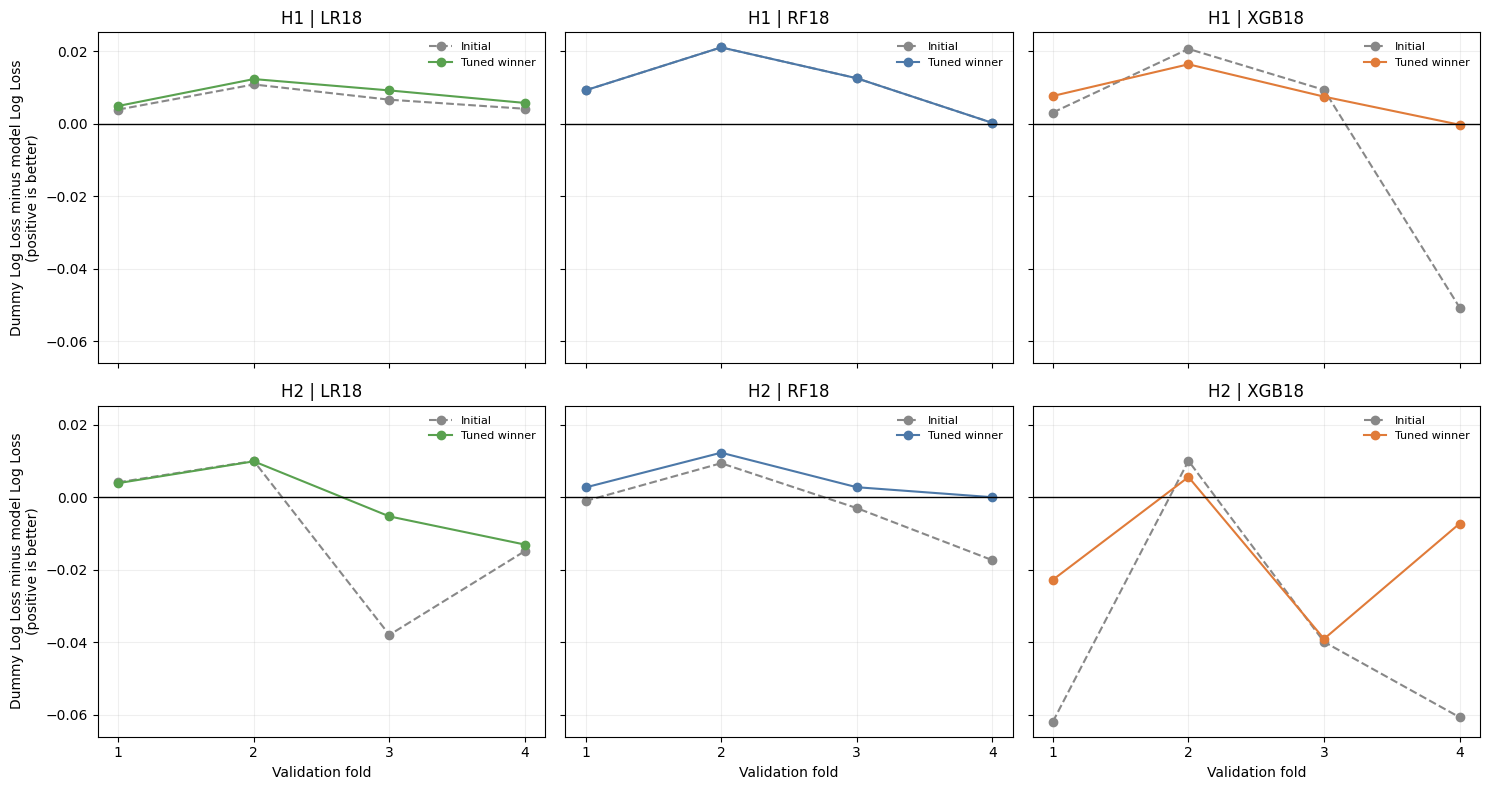

In [50]:
# Compare the six within-model winners using all four validation metrics
comparison_columns = ['Hotel', 'ModelLabel', 'ConfigID', 'LogLoss', 'BrierScore',
    'ROC_AUC', 'AveragePrecision', 'MeanTrainLogLoss', 'MeanGap', 'GainVsInitial',
    'FoldsBeatingDummy', 'WorstExcessVsDummy']
display(tuning_best[comparison_columns].style.format({
    column: '{:.4f}' for column in comparison_columns if column not in
    ['Hotel', 'ModelLabel', 'ConfigID', 'FoldsBeatingDummy']}).hide(axis='index'))

# Compare train-validation gaps before and after tuning on the same windows
initial_summary = tuning_summary.loc[tuning_summary['IsInitial'],
    ['Hotel', 'ModelLabel', 'MeanTrainLogLoss', 'MeanGap', 'LogLossSD', 'WorstExcessVsDummy']]
tuning_generalization = tuning_best.merge(initial_summary, on=['Hotel', 'ModelLabel'],
    validate='one_to_one', suffixes=('_tuned', '_initial'))
gap_columns = ['MeanTrainLogLoss_initial', 'MeanTrainLogLoss_tuned', 'MeanGap_initial', 'MeanGap_tuned',
               'WorstExcessVsDummy_initial', 'WorstExcessVsDummy_tuned']
display(tuning_generalization[['Hotel', 'ModelLabel'] + gap_columns].style.format({
    column: '{:.4f}' for column in gap_columns}).hide(axis='index'))

# Retain exact winner and initial losses for each validation window
winner_keys = tuning_best[['Hotel', 'ConfigID']]
tuning_best_windows = tuning_metrics.merge(winner_keys, on=['Hotel', 'ConfigID'], validate='many_to_one')
display(tuning_best_windows[['Hotel', 'ModelLabel', 'Fold', 'ValidationRows', 'ValidationPositives',
    'LogLoss', 'InitialLogLoss', 'DummyLogLoss', 'GainVsDummy', 'TrainLogLoss', 'GeneralizationGap']]
    .style.format({column: '{:.4f}' for column in ['LogLoss', 'InitialLogLoss', 'DummyLogLoss',
        'GainVsDummy', 'TrainLogLoss', 'GeneralizationGap']}).hide(axis='index'))

# Plot same-window improvement so prevalence changes do not obscure the Dummy comparison
fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharex=True, sharey=True)
for row, hotel in enumerate(config['hotels']):
    for column, label in enumerate(tuning_grids):
        panel = tuning_best_windows.loc[tuning_best_windows['Hotel'].eq(hotel)
                                        & tuning_best_windows['ModelLabel'].eq(label)].sort_values('Fold')
        ax = axes[row, column]
        ax.plot(panel['Fold'], panel['DummyLogLoss'] - panel['InitialLogLoss'], '--o',
                color='#888888', label='Initial')
        ax.plot(panel['Fold'], panel['GainVsDummy'], '-o',
                color=diagnostic_colors[label], label='Tuned winner')
        ax.axhline(0, color='black', linewidth=1)
        ax.set(title=f'{hotel} | {label}', xticks=[1, 2, 3, 4])
        ax.grid(alpha=0.2)
        if row == 1:
            ax.set_xlabel('Validation fold')
        if column == 0:
            ax.set_ylabel('Dummy Log Loss minus model Log Loss\n(positive is better)')
        ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
plt.show()

**Observation:**

- **H1:** LR18 improves slightly in all four windows. XGB18's mean improves from 0.2815 to 0.2693, largely by reducing the fold-4 loss from 0.3668 to 0.3163; folds 2-3 worsen relative to initial. RF18's initial configuration remains the winner, so stronger restrictions do not improve every model-hotel combination.
- **H2:** Shallower RF improves mean Log Loss from 0.3670 to 0.3595, below Dummy at 0.3640, and also improves Brier, ROC-AUC and AP. It beats Dummy in all four windows, but fold 4 is effectively a near tie (gain about 0.000004). LR18 and XGB18 improve mean probability metrics but remain worse than Dummy; LR18's ranking metrics decline.
- More restricted XGB configurations have smaller mean train-validation gaps for both hotels. H2 RF also fits train less closely while improving validation, showing that configuration changes can help. A smaller or negative mean gap is not itself the objective or proof that shift is resolved; probability performance and window-level gains remain decisive.

#### 6.6.6 Save Tuning Results

In [51]:
# Save one metrics, OOF, summary and log table per hotel
tuning_report_tables = {}
for hotel in config['hotels']:
    for filename, table in [('fold_metrics.csv', tuning_metrics), ('oof_predictions.csv', tuning_predictions),
                            ('cv_summary.csv', tuning_summary), ('experiment_log.csv', tuning_logs)]:
        tuning_report_tables[f'{hotel}/{filename}'] = table.loc[table['Hotel'].eq(hotel)].reset_index(drop=True)
tuning_schemas, tuning_contents = {}, {}
for relative_path, table in tuning_report_tables.items():
    dates = [column for column in table if pd.api.types.is_datetime64_any_dtype(table[column])]
    tuning_schemas[relative_path] = {'dtypes': {c: str(t) for c, t in table.dtypes.items()}, 'date_columns': dates}
    tuning_contents[relative_path] = table.to_csv(index=False, date_format='%Y-%m-%d', lineterminator='\n').encode('utf-8')
tuning_execution_hash = (tuning_saved_config['execution_notebook_code_sha256']
    if tuning_saved_config is not None else tuning_hash([
        ''.join(cell['source']) for cell in tuning_notebook['cells'] if cell['cell_type'] == 'code']))
tuning_run_config = {'protocol': tuning_protocol,
    'execution_notebook_code_sha256': tuning_execution_hash, 'output_schema': tuning_schemas,
    'output_sha256': {name: hashlib.sha256(value).hexdigest() for name, value in tuning_contents.items()}}

# Preserve completed runs and publish the config only after exact read-back checks
tuning_save_rows = []
for relative_path, table in tuning_report_tables.items():
    destination = tuning_directory / relative_path
    destination.parent.mkdir(parents=True, exist_ok=True)
    if destination.exists() and destination.read_bytes() != tuning_contents[relative_path]:
        raise FileExistsError(f'{destination} differs; use a new tuning_run_id')
    if not destination.exists():
        temporary = destination.with_suffix('.csv.tmp')
        temporary.write_bytes(tuning_contents[relative_path])
        temporary.replace(destination)
    restored = read_tuning_table(relative_path, tuning_run_config)
    pd.testing.assert_frame_equal(table, restored, check_exact=True)
    tuning_save_rows.append({'Hotel': relative_path.split('/')[0], 'File': destination.name,
                             'Rows': len(restored), 'ReadBack': 'PASS'})
configuration_path = tuning_directory / 'run_config.json'
if configuration_path.exists():
    if json.loads(configuration_path.read_text(encoding='utf-8')) != tuning_run_config:
        raise FileExistsError('Existing tuning config differs')
else:
    temporary = configuration_path.with_suffix('.json.tmp')
    temporary.write_text(json.dumps(tuning_run_config, indent=2) + '\n', encoding='utf-8')
    temporary.replace(configuration_path)
display(pd.DataFrame(tuning_save_rows).style.format({'Rows': '{:,}'}).hide(axis='index'))
print('Directory:', tuning_directory)

Hotel,File,Rows,ReadBack
H1,fold_metrics.csv,100,PASS
H1,oof_predictions.csv,"152,975",PASS
H1,cv_summary.csv,25,PASS
H1,experiment_log.csv,100,PASS
H2,fold_metrics.csv,100,PASS
H2,oof_predictions.csv,"308,450",PASS
H2,cv_summary.csv,25,PASS
H2,experiment_log.csv,100,PASS


Directory: /workspace/Project/Model pipeline/reports/tuning_round1_v1


**Observation:** `reports/tuning_round1_v1/` contains one run config and four tables per hotel: fold metrics, OOF predictions, CV summary and experiment log. All eight tables pass exact read-back checks. `BestWithinModel` identifies each grid winner, and the run config maps every ConfigID to its complete parameters.

### 6.7 Targeted Feature Ablation

#### 6.7.1 Experiment Config

Compare four feature sets using each hotel's RF configuration selected in Tuning Round 1. Hyperparameters and temporal folds stay fixed; preprocessing is fitted separately on each training portion.

In [52]:
# Define the four feature sets and the fixed RF reference for each hotel
feature_run_id = 'feature_ablation_round1_v1'
feature_directory = project_root / 'Model pipeline' / 'reports' / feature_run_id
feature_drops = {'F0': [], 'F1': ['EURUSD'], 'F2': ['LeadTime'], 'F3': ['EURUSD', 'LeadTime']}
feature_sets = {name: {group: [column for column in columns if column not in dropped]
    for group, columns in tuning_features.items()} for name, dropped in feature_drops.items()}
feature_reference_ids, feature_model_params = {}, {}
for hotel in config['hotels']:
    reference = tuning_best.loc[tuning_best['Hotel'].eq(hotel) & tuning_best['ModelLabel'].eq('RF18')]
    if len(reference) != 1:
        raise AssertionError('Expected one RF reference per hotel')
    config_id = reference.iloc[0]['ConfigID']
    candidate = next(c for c in tuning_candidates if c['ConfigID'] == config_id)
    feature_reference_ids[hotel] = config_id
    feature_model_params[hotel] = candidate['Parameters'].copy()
if (feature_model_params['H1'] != rf_model_params
        or feature_model_params['H2'] != {**rf_model_params, 'max_depth': 6, 'min_samples_leaf': 50}):
    raise AssertionError('RF references differ from the approved ablation configurations')

# Verify all frozen tuning artifacts before reusing F0 metrics and OOF
feature_source_config = json.loads((tuning_directory / 'run_config.json').read_text(encoding='utf-8'))
if feature_source_config['protocol'] != tuning_protocol:
    raise AssertionError('Tuning reference protocol changed')
for name, digest in feature_source_config['output_sha256'].items():
    if hashlib.sha256((tuning_directory / name).read_bytes()).hexdigest() != digest:
        raise AssertionError(f'Tuning source changed: {name}')
feature_inputs = {f'{hotel}/fold_{fold}/{role}': tuning_frame_hash(cohort)
    for (hotel, fold, role), cohort in diagnostic_cohorts.items()}
if feature_inputs != tuning_protocol['input_cohort_sha256']:
    raise AssertionError('Ablation cohorts differ from the tuning reference')
feature_reference_metrics, feature_reference_predictions, feature_reference_logs = {}, {}, {}
for hotel, config_id in feature_reference_ids.items():
    feature_reference_metrics[hotel] = tuning_metrics.loc[
        tuning_metrics['Hotel'].eq(hotel) & tuning_metrics['ConfigID'].eq(config_id)].copy()
    feature_reference_predictions[hotel] = tuning_predictions.loc[
        tuning_predictions['Hotel'].eq(hotel) & tuning_predictions['ConfigID'].eq(config_id)].copy()
    feature_reference_logs[hotel] = tuning_logs.loc[
        tuning_logs['Hotel'].eq(hotel) & tuning_logs['ConfigID'].eq(config_id)].copy()

# Fingerprint fit and aggregation methods while allowing presentation-only changes
feature_notebook = json.loads((project_root / 'Model pipeline' / 'model_train_main.ipynb').read_text(encoding='utf-8'))
feature_method_names = {'run_candidate_fold', 'diagnostic_model_state', 'tuning_json', 'tuning_hash',
    'tuning_frame_hash', 'run_feature_fold', 'read_feature_table'}
feature_methods = {}
for cell in feature_notebook['cells']:
    if cell['cell_type'] != 'code':
        continue
    source = ''.join(cell['source'])
    for node in ast.parse(source).body:
        if isinstance(node, ast.FunctionDef) and node.name in feature_method_names:
            feature_methods[node.name] = ast.dump(node, include_attributes=False)
    if source.startswith('# Audit all feature-set evaluations'):
        feature_aggregation_source = ast.dump(
            ast.parse(source.split('# Display the primary comparison')[0]), include_attributes=False)
if set(feature_methods) != feature_method_names:
    raise AssertionError('Missing feature-experiment method provenance')
feature_protocol = {
    'run_id': feature_run_id, 'model': 'random_forest', 'reference_run': tuning_run_id,
    'reference_config_ids': feature_reference_ids, 'model_params': feature_model_params,
    'feature_sets': feature_sets, 'removed_features': feature_drops,
    'split_id': split_id, 'split_config': split_config, 'evaluation': evaluation_config,
    'environment': tuning_environment, 'input_cohort_sha256': feature_inputs,
    'expected_evaluations': 32, 'expected_reference_reuses': 8, 'expected_new_fits': 24,
    'reference_config_sha256': hashlib.sha256((tuning_directory / 'run_config.json').read_bytes()).hexdigest(),
    'reference_outputs_sha256': feature_source_config['output_sha256'],
    'source_sha256': tuning_protocol['source_sha256'], 'code_sha256': tuning_protocol['code_sha256'],
    'fitting_functions_sha256': tuning_hash(feature_methods),
    'aggregation_sha256': tuning_hash(feature_aggregation_source),
    'replay_absolute_tolerance': tuning_tolerance,
}

# Reload an identical completed experiment instead of repeating the fits
def read_feature_table(relative_path, saved_config):
    schema = saved_config['output_schema'][relative_path]
    table = pd.read_csv(feature_directory / relative_path,
        dtype={c: t for c, t in schema['dtypes'].items() if c not in schema['date_columns']},
        parse_dates=schema['date_columns'], keep_default_na=False, float_precision='round_trip')
    for column in schema['date_columns']:
        table[column] = table[column].astype(schema['dtypes'][column])
    return table


feature_saved_config, feature_saved_tables = None, {}
if (feature_directory / 'run_config.json').exists():
    feature_saved_config = json.loads((feature_directory / 'run_config.json').read_text(encoding='utf-8'))
    if feature_saved_config['protocol'] != feature_protocol:
        raise FileExistsError('Feature experiment conditions changed; use a new feature_run_id')
    for name, digest in feature_saved_config['output_sha256'].items():
        if hashlib.sha256((feature_directory / name).read_bytes()).hexdigest() != digest:
            raise AssertionError(f'Feature artifact changed: {name}')
        feature_saved_tables[name] = read_feature_table(name, feature_saved_config)
feature_metric_parts, feature_prediction_parts, feature_log_parts = [], [], []
feature_prototype_results = {}
display(pd.DataFrame([{'FeatureSet': name, 'Removed': ', '.join(feature_drops[name]) or 'None',
    'InputColumns': sum(map(len, groups.values()))} for name, groups in feature_sets.items()])
    .style.hide(axis='index'))
display(pd.DataFrame([{'Hotel': hotel, 'ReferenceConfig': feature_reference_ids[hotel],
    'RFParameters': tuning_json(parameters)} for hotel, parameters in feature_model_params.items()])
    .style.hide(axis='index'))
print('32 evaluations | 8 F0 reuses | 24 new fits')

FeatureSet,Removed,InputColumns
F0,None,18
F1,EURUSD,17
F2,LeadTime,17
F3,"EURUSD, LeadTime",16


Hotel,ReferenceConfig,RFParameters
H1,rf18_07,"{""bootstrap"":true,""class_weight"":null,""criterion"":""gini"",""max_depth"":null,""max_features"":""sqrt"",""min_samples_leaf"":20,""n_estimators"":300,""n_jobs"":2,""random_state"":42}"
H2,rf18_02,"{""bootstrap"":true,""class_weight"":null,""criterion"":""gini"",""max_depth"":6,""max_features"":""sqrt"",""min_samples_leaf"":50,""n_estimators"":300,""n_jobs"":2,""random_state"":42}"


32 evaluations | 8 F0 reuses | 24 new fits


#### 6.7.2 Fit and Check H1 Fold 1

Check F1 without EURUSD before running all feature sets. F0 reuses the matching tuning results; other sets fit fresh pipelines using the same eligible train and validation bookings.

In [53]:
# Evaluate one fixed-parameter RF feature set and preserve booking-level alignment
def run_feature_fold(hotel, fold, feature_name):
    started, started_utc = perf_counter(), datetime.now(timezone.utc).isoformat()
    parameters, groups = feature_model_params[hotel], feature_sets[feature_name]
    columns = [column for values in groups.values() for column in values]
    train, valid = diagnostic_cohorts[(hotel, fold, 'Train')], diagnostic_cohorts[(hotel, fold, 'Validation')]
    reference = feature_reference_metrics[hotel].loc[feature_reference_metrics[hotel]['Fold'].eq(fold)].iloc[0]
    reference_log = feature_reference_logs[hotel].loc[feature_reference_logs[hotel]['Fold'].eq(fold)].iloc[0]
    expected = model_pipeline.build_pipeline('random_forest', groups, parameters)
    checks = {
        'Reference parameters match completely': reference_log['ParameterSHA256'] == tuning_hash(parameters)
            and reference_log['EffectiveEstimatorSHA256'] == tuning_hash(expected.named_steps['model'].get_params(deep=True)),
        'Reference input cohorts match': reference_log['TrainInputSHA256'] == feature_inputs[f'{hotel}/fold_{fold}/Train']
            and reference_log['ValidationInputSHA256'] == feature_inputs[f'{hotel}/fold_{fold}/Validation'],
        'Only the declared features are removed': set(tuning_columns) - set(columns) == set(feature_drops[feature_name])
            and not set(columns) - set(tuning_columns),
    }
    pipeline = None
    if feature_name == 'F0':
        row = reference.to_dict()
        prediction = feature_reference_predictions[hotel].loc[
            feature_reference_predictions[hotel]['Fold'].eq(fold)].copy()
        train_scores = {metric: reference[f'Train{metric}'] for metric in metric_columns}
        checks['Reference preprocessing matches completely'] = (
            reference_log['PreprocessingSHA256'] == tuning_hash(expected.named_steps['preprocessor'].get_params(deep=True)))
        source = 'reused_F0'
        fitted_state = reference_log['FittedStateSHA256']
        observed_depth = int(reference_log['ObservedTreeDepth'])
    else:
        result = run_candidate_fold(hotel, fold, 'random_forest', feature_name, groups, parameters)
        pipeline, row, prediction = result['pipeline'], result['metrics'], result['predictions']
        checks.update({f'Fit: {item.Check}': item.Passed for item in result['checks'].itertuples()})
        preprocessor, estimator = pipeline.named_steps['preprocessor'], pipeline.named_steps['model']
        checks['Fixed RF parameters match completely'] = tuning_json(estimator.get_params(deep=True)) == tuning_json(
            expected.named_steps['model'].get_params(deep=True))
        checks['Preprocessing matches the declared feature set'] = (
            tuning_json(preprocessor.get_params(deep=True)) == tuning_json(expected.named_steps['preprocessor'].get_params(deep=True))
            and list(preprocessor.feature_names_in_) == columns)
        checks['Binary imputation uses eligible train'] = np.array_equal(
            preprocessor.named_transformers_['binary'].named_steps['imputer'].statistics_,
            train[groups['binary']].mode().iloc[0].to_numpy())
        state_before = diagnostic_model_state(pipeline, 'random_forest')
        probabilities = pipeline.predict_proba(train[columns])[:, list(estimator.classes_).index(1)].astype(float)
        train_scores = model_evaluation.evaluate_predictions(train['IsCanceled'], probabilities)
        checks['Training prediction preserves the fitted model'] = diagnostic_model_state(pipeline, 'random_forest') == state_before
        fitted_state = tuning_hash(state_before)
        observed_depth = int(row['MaxTreeDepth'])
        source = 'new_fit'

    # Check exact cohort, fit dates and label maturity for both new and reused evaluations
    aligned = valid[['Hotel', 'Booking_ID', 'CutoffDate', 'IsCanceled']].merge(
        prediction, on=['Hotel', 'Booking_ID'], how='left', validate='one_to_one',
        suffixes=('_gold', ''), indicator=True)
    fit_date, valid_end = pd.Timestamp(reference['FitDate']), pd.Timestamp(reference['ValidationEnd'])
    checks['Validation membership, dates and labels match'] = (
        len(prediction) == len(valid) and aligned['_merge'].eq('both').all()
        and aligned['IsCanceled'].eq(aligned['IsCanceled_gold']).all()
        and aligned['PredictionDate'].eq(aligned['CutoffDate']).all()
        and aligned['Fold'].eq(fold).all())
    eligibility = split_results[hotel]['fit_eligibility']
    eligible = eligibility.loc[eligibility['Stage'].eq('CV')
        & eligibility['Fold'].eq(fold).fillna(False) & eligibility['Eligible']]
    checks['Training membership and label maturity match'] = (
        set(train['Booking_ID']) == set(eligible['Booking_ID']) and eligible['LabelAvailableDate'].lt(fit_date).all()
        and row['TrainRows'] == len(train) and row['TrainPositives'] == int(train['IsCanceled'].sum()))
    checks['Calendar boundaries match the reference'] = (
        pd.Timestamp(row['FitDate']) == fit_date and pd.Timestamp(row['ValidationStart']) == fit_date
        and pd.Timestamp(row['ValidationEnd']) == valid_end and train['CutoffDate'].lt(fit_date).all()
        and valid['CutoffDate'].ge(fit_date).all() and valid['CutoffDate'].lt(valid_end).all()
        and valid['CutoffDate'].lt(pd.Timestamp(split_config['test_start'])).all())
    checks['Input and processed counts match the ablation'] = (
        row['InputColumns'] == len(columns)
        and row['ProcessedColumns'] == reference['ProcessedColumns'] - len(feature_drops[feature_name]))
    valid_scores = model_evaluation.evaluate_predictions(aligned['IsCanceled'], aligned['RawProbability'])
    checks['All validation metrics match the OOF'] = all(np.isclose(
        valid_scores[metric], row[metric], rtol=0, atol=tuning_tolerance) for metric in metric_columns)
    if not all(checks.values()):
        raise AssertionError(f'{hotel} {feature_name} fold {fold}: '
            + '; '.join(name for name, passed in checks.items() if not passed))

    # Keep probability bias beside the four metrics and reference comparisons
    common = ['Hotel', 'Model', 'Fold', 'FitDate', 'ValidationStart', 'ValidationEnd',
        'TrainRows', 'TrainPositives', 'TrainCancelRate', 'ValidationRows', 'ValidationPositives',
        'ValidationCancelRate', 'InputColumns', 'ProcessedColumns']
    metric_row = {key: row[key] for key in common}
    metric_row.update({metric: valid_scores[metric] for metric in metric_columns})
    metric_row.update({f'Train{metric}': train_scores[metric] for metric in metric_columns})
    mean_probability = float(aligned['RawProbability'].mean())
    metric_row.update({'FeatureSet': feature_name, 'ReferenceConfigID': feature_reference_ids[hotel],
        'Source': source, 'F0LogLoss': reference['LogLoss'], 'DummyLogLoss': reference['DummyLogLoss'],
        'GainVsF0': reference['LogLoss'] - valid_scores['LogLoss'],
        'GainVsDummy': reference['DummyLogLoss'] - valid_scores['LogLoss'],
        'MeanProbability': mean_probability, 'ProbabilityBias': mean_probability - valid_scores['CancelRate'],
        'GeneralizationGap': valid_scores['LogLoss'] - train_scores['LogLoss']})
    prediction = prediction[['Hotel', 'Booking_ID', 'Model', 'Fold', 'PredictionDate',
                             'IsCanceled', 'RawProbability']].copy()
    prediction['FeatureSet'], prediction['ReferenceConfigID'] = feature_name, feature_reference_ids[hotel]
    processed = int(row['ProcessedColumns'])
    log = {'Hotel': hotel, 'FeatureSet': feature_name, 'Fold': fold,
        'ReferenceConfigID': feature_reference_ids[hotel], 'Source': source, 'Status': 'PASS',
        'StartedUTC': started_utc, 'FinishedUTC': datetime.now(timezone.utc).isoformat(),
        'EvaluationSeconds': perf_counter() - started, 'ChecksPassed': len(checks),
        'ParameterSHA256': tuning_hash(parameters), 'FeatureConfigSHA256': tuning_hash(groups),
        'TrainInputSHA256': feature_inputs[f'{hotel}/fold_{fold}/Train'],
        'ValidationInputSHA256': feature_inputs[f'{hotel}/fold_{fold}/Validation'],
        'FittedStateSHA256': fitted_state, 'ObservedTreeDepth': observed_depth,
        'ProcessedColumns': processed, 'EffectiveMaxFeatures': max(1, int(np.sqrt(processed)))}
    return metric_row, prediction, log


# Prototype F1 once and reuse its result in the full experiment
if feature_saved_config is None:
    feature_prototype_results[('H1', 1, 'F1')] = run_feature_fold('H1', 1, 'F1')
    display(pd.DataFrame([feature_prototype_results[('H1', 1, 'F1')][0]])[
        ['Hotel', 'FeatureSet', 'Fold', 'InputColumns', 'TrainRows', 'ValidationRows'] + metric_columns
    ].style.format({metric: '{:.4f}' for metric in metric_columns}).hide(axis='index'))
    print('H1 fold 1 F1 prototype passed')
else:
    print('Verified completed experiment found; restore its evaluations')

Verified completed experiment found; restore its evaluations


#### 6.7.3 Run H1/H2 Temporal CV

Run F0-F3 on the same four windows. All comparisons retain the RF configuration chosen for that hotel.

In [54]:
# Restore a completed experiment or run the four declared feature sets
if feature_saved_config is not None:
    for hotel in config['hotels']:
        for filename, target in [('fold_metrics.csv', feature_metric_parts),
            ('oof_predictions.csv', feature_prediction_parts), ('experiment_log.csv', feature_log_parts)]:
            target.append(feature_saved_tables[f'{hotel}/{filename}'].copy())
    print('Restored 32 verified feature-set evaluations')
else:
    for feature_name in feature_sets:
        metrics, predictions, logs = [], [], []
        for hotel in config['hotels']:
            for fold in range(1, split_config['n_folds'] + 1):
                key = (hotel, fold, feature_name)
                result = (feature_prototype_results.pop(key) if key in feature_prototype_results
                          else run_feature_fold(hotel, fold, feature_name))
                metrics.append(result[0])
                predictions.append(result[1])
                logs.append(result[2])
        feature_metric_parts.append(pd.DataFrame(metrics))
        feature_prediction_parts.append(pd.concat(predictions, ignore_index=True))
        feature_log_parts.append(pd.DataFrame(logs))
        print(f'{feature_name}: eight evaluations passed | {logs[0]["Source"]}', flush=True)

Restored 32 verified feature-set evaluations


**Observation:** All 32 evaluations pass: eight F0 results reused from the matching tuning configurations and 24 new fits. Input counts are 18, 17, 17 and 16 for F0-F3; validation bookings, labels, dates and RF hyperparameters remain fixed within each hotel.

#### 6.7.4 Compare Feature Sets

Rank by equal-weight mean validation Log Loss. Positive gains indicate improvement over the same-window reference. Review ranking and probability metrics together; these are comparisons within fixed RF configurations.

In [55]:
# Audit all feature-set evaluations and their OOF predictions
feature_metrics = pd.concat(feature_metric_parts, ignore_index=True).sort_values(
    ['Hotel', 'FeatureSet', 'Fold']).reset_index(drop=True)
feature_predictions = pd.concat(feature_prediction_parts, ignore_index=True).sort_values(
    ['Hotel', 'FeatureSet', 'Fold', 'Booking_ID']).reset_index(drop=True)
feature_logs = pd.concat(feature_log_parts, ignore_index=True).sort_values(
    ['Hotel', 'FeatureSet', 'Fold']).reset_index(drop=True)
if (len(feature_metrics) != 32 or len(feature_logs) != 32
        or feature_metrics.duplicated(['Hotel', 'FeatureSet', 'Fold']).any()
        or feature_predictions.duplicated(['Hotel', 'FeatureSet', 'Booking_ID']).any()
        or not feature_logs['Status'].eq('PASS').all()
        or feature_logs['Source'].value_counts().to_dict() != {'new_fit': 24, 'reused_F0': 8}):
    raise AssertionError('Feature experiment counts or keys do not match the protocol')

# Calculate equal-weight fold means and observation-weighted OOF Log Loss separately
feature_summary_rows = []
for (hotel, name), windows in feature_metrics.groupby(['Hotel', 'FeatureSet']):
    if windows['Fold'].tolist() != [1, 2, 3, 4]:
        raise AssertionError('Every feature set requires four validation windows')
    observed = feature_predictions.loc[feature_predictions['Hotel'].eq(hotel)
        & feature_predictions['FeatureSet'].eq(name)]
    expected = feature_reference_predictions[hotel]
    aligned = expected[['Hotel', 'Booking_ID', 'Fold', 'PredictionDate', 'IsCanceled']].merge(
        observed, on=['Hotel', 'Booking_ID'], how='outer', indicator=True,
        validate='one_to_one', suffixes=('_reference', ''))
    if (not aligned['_merge'].eq('both').all()
            or not all(aligned[c].eq(aligned[f'{c}_reference']).all()
                       for c in ['Fold', 'PredictionDate', 'IsCanceled'])):
        raise AssertionError(f'{hotel} {name}: OOF alignment failed')
    for fold, predictions in observed.groupby('Fold'):
        scores = model_evaluation.evaluate_predictions(predictions['IsCanceled'], predictions['RawProbability'])
        row = windows.loc[windows['Fold'].eq(fold)].iloc[0]
        if (scores['Rows'] != row['ValidationRows'] or scores['Positives'] != row['ValidationPositives']
                or not all(np.isclose(scores[m], row[m], rtol=0, atol=tuning_tolerance) for m in metric_columns)
                or not np.isclose(predictions['RawProbability'].mean(), row['MeanProbability'],
                                  rtol=0, atol=tuning_tolerance)):
            raise AssertionError('Feature metrics do not reconcile with OOF')
    pooled = model_evaluation.evaluate_predictions(observed['IsCanceled'], observed['RawProbability'])
    if not np.isclose(pooled['LogLoss'], np.average(windows['LogLoss'], weights=windows['ValidationRows']),
                      rtol=0, atol=tuning_tolerance):
        raise AssertionError('Pooled Log Loss differs from weighted fold losses')
    feature_summary_rows.append({'Hotel': hotel, 'FeatureSet': name,
        'Removed': tuning_json(feature_drops[name]), 'ReferenceConfigID': feature_reference_ids[hotel],
        'InputColumns': int(windows['InputColumns'].iloc[0]),
        'ValidationRows': int(windows['ValidationRows'].sum()),
        'ValidationPositives': int(windows['ValidationPositives'].sum()),
        **{metric: windows[metric].mean() for metric in metric_columns},
        'F0LogLoss': windows['F0LogLoss'].mean(), 'DummyLogLoss': windows['DummyLogLoss'].mean(),
        'GainVsF0': windows['GainVsF0'].mean(), 'GainVsDummy': windows['GainVsDummy'].mean(),
        'FoldsBeatingF0': int(windows['GainVsF0'].gt(tuning_tolerance).sum()),
        'FoldsBeatingDummy': int(windows['GainVsDummy'].gt(tuning_tolerance).sum()),
        'MeanTrainLogLoss': windows['TrainLogLoss'].mean(), 'MeanGap': windows['GeneralizationGap'].mean(),
        'MeanProbabilityBias': windows['ProbabilityBias'].mean(),
        'MeanAbsoluteWindowBias': windows['ProbabilityBias'].abs().mean(),
        'LogLossSD': windows['LogLoss'].std(ddof=0),
        'WorstFold': int(windows.loc[windows['LogLoss'].idxmax(), 'Fold']),
        'WorstLogLoss': windows['LogLoss'].max(),
        'WorstExcessVsDummy': (windows['LogLoss'] - windows['DummyLogLoss']).max(),
        'PooledOOFLogLoss': pooled['LogLoss']})
feature_summary = pd.DataFrame(feature_summary_rows).sort_values(
    ['Hotel', 'LogLoss', 'FeatureSet'], kind='stable').reset_index(drop=True)
feature_summary['Rank'] = feature_summary.groupby('Hotel').cumcount() + 1

# Display the primary comparison without treating the ranking as a final feature decision
display(feature_summary[['Hotel', 'FeatureSet', 'InputColumns', 'LogLoss', 'F0LogLoss', 'DummyLogLoss',
    'GainVsF0', 'FoldsBeatingF0', 'FoldsBeatingDummy', 'PooledOOFLogLoss']].style.format({
        column: '{:.5f}' for column in ['LogLoss', 'F0LogLoss', 'DummyLogLoss', 'GainVsF0', 'PooledOOFLogLoss']})
    .hide(axis='index'))
display(feature_summary[['Hotel', 'FeatureSet'] + metric_columns +
    ['MeanTrainLogLoss', 'MeanGap', 'MeanAbsoluteWindowBias', 'WorstExcessVsDummy']].style.format({
        column: '{:.4f}' for column in metric_columns +
            ['MeanTrainLogLoss', 'MeanGap', 'MeanAbsoluteWindowBias', 'WorstExcessVsDummy']}).hide(axis='index'))
print(f'PASS: 32 evaluations | 8 F0 reuses | 24 new fits | {len(feature_predictions):,} aligned OOF rows')

Hotel,FeatureSet,InputColumns,LogLoss,F0LogLoss,DummyLogLoss,GainVsF0,FoldsBeatingF0,FoldsBeatingDummy,PooledOOFLogLoss
H1,F1,17,0.26488,0.26634,0.27717,0.00146,2,4,0.25454
H1,F0,18,0.26634,0.26634,0.27717,0.00000,0,4,0.25565
H1,F2,17,0.26892,0.26634,0.27717,-0.00258,1,3,0.25865
H1,F3,16,0.26927,0.26634,0.27717,-0.00293,1,4,0.25859
H2,F1,17,0.35747,0.35953,0.36397,0.00206,4,4,0.35417
H2,F3,16,0.35762,0.35953,0.36397,0.00190,3,4,0.35409
H2,F0,18,0.35953,0.35953,0.36397,-0.00000,0,4,0.35600
H2,F2,17,0.36046,0.35953,0.36397,-0.00093,2,3,0.35654


Hotel,FeatureSet,LogLoss,BrierScore,ROC_AUC,AveragePrecision,MeanTrainLogLoss,MeanGap,MeanAbsoluteWindowBias,WorstExcessVsDummy
H1,F1,0.2649,0.0711,0.6576,0.1488,0.2139,0.0510,0.0090,-0.0078
H1,F0,0.2663,0.0716,0.6574,0.1504,0.2097,0.0567,0.0201,-0.0003
H1,F2,0.2689,0.0721,0.6356,0.1396,0.2155,0.0534,0.0207,0.0029
H1,F3,0.2693,0.0718,0.6293,0.1353,0.2210,0.0482,0.0119,-0.0028
H2,F1,0.3575,0.1025,0.6127,0.1781,0.3668,-0.0094,0.0320,-0.0043
H2,F3,0.3576,0.1027,0.6118,0.1832,0.3710,-0.0134,0.0308,-0.0004
H2,F0,0.3595,0.1031,0.6072,0.1768,0.3658,-0.0063,0.0374,-0.0000
H2,F2,0.3605,0.1034,0.6065,0.1721,0.3696,-0.0092,0.0379,0.0025


PASS: 32 evaluations | 8 F0 reuses | 24 new fits | 73,828 aligned OOF rows


**Observation:**

- **F1, without EURUSD, has the lowest mean Log Loss for both hotels:** H1 improves from 0.26634 to 0.26488 and H2 from 0.35953 to 0.35747. Both also improve Brier. H1 mean ROC-AUC is almost unchanged and AP decreases slightly; H2 mean ROC-AUC and AP improve.
- **Removing LeadTime alone worsens mean Log Loss in both hotels.** Removing both features is also worse than F0 for H1. For H2, F3 is close to F1 in Log Loss and has higher AP (0.1832 vs 0.1781), but F1 retains the primary-metric ranking.
- These results compare fixed RF configurations. They support reviewing F1 as a candidate; they do not establish that EURUSD is intrinsically harmful or that LeadTime's value is identical across models and periods.

#### 6.7.5 Review Validation Windows

Check whether improvements recur across windows and whether average predictions move closer to the observed cancellation rate. Mean bias is one diagnostic, not a complete measure of calibration.

Hotel,FeatureSet,Fold,ValidationRows,ValidationPositives,LogLoss,GainVsF0,GainVsDummy,ValidationCancelRate,MeanProbability,GeneralizationGap
H1,F0,1,1779,115,0.2328,0.0000,0.0093,6.5%,7.3%,0.0178
H1,F0,2,1936,112,0.2034,0.0000,0.0211,5.8%,7.1%,-0.0081
H1,F0,3,1152,114,0.3133,0.0000,0.0126,9.9%,12.4%,0.1080
H1,F0,4,1252,119,0.3158,0.0000,0.0003,9.5%,12.8%,0.1089
H1,F1,1,1779,115,0.2342,-0.0015,0.0078,6.5%,7.6%,0.0150
H1,F1,2,1936,112,0.2034,0.0000,0.0212,5.8%,7.6%,-0.0119
H1,F1,3,1152,114,0.3160,-0.0026,0.0100,9.9%,9.7%,0.1066
H1,F1,4,1252,119,0.3059,0.0099,0.0102,9.5%,9.0%,0.0944
H1,F2,1,1779,115,0.2390,-0.0062,0.0031,6.5%,7.3%,0.0186
H1,F2,2,1936,112,0.2063,-0.0029,0.0182,5.8%,7.1%,-0.0108


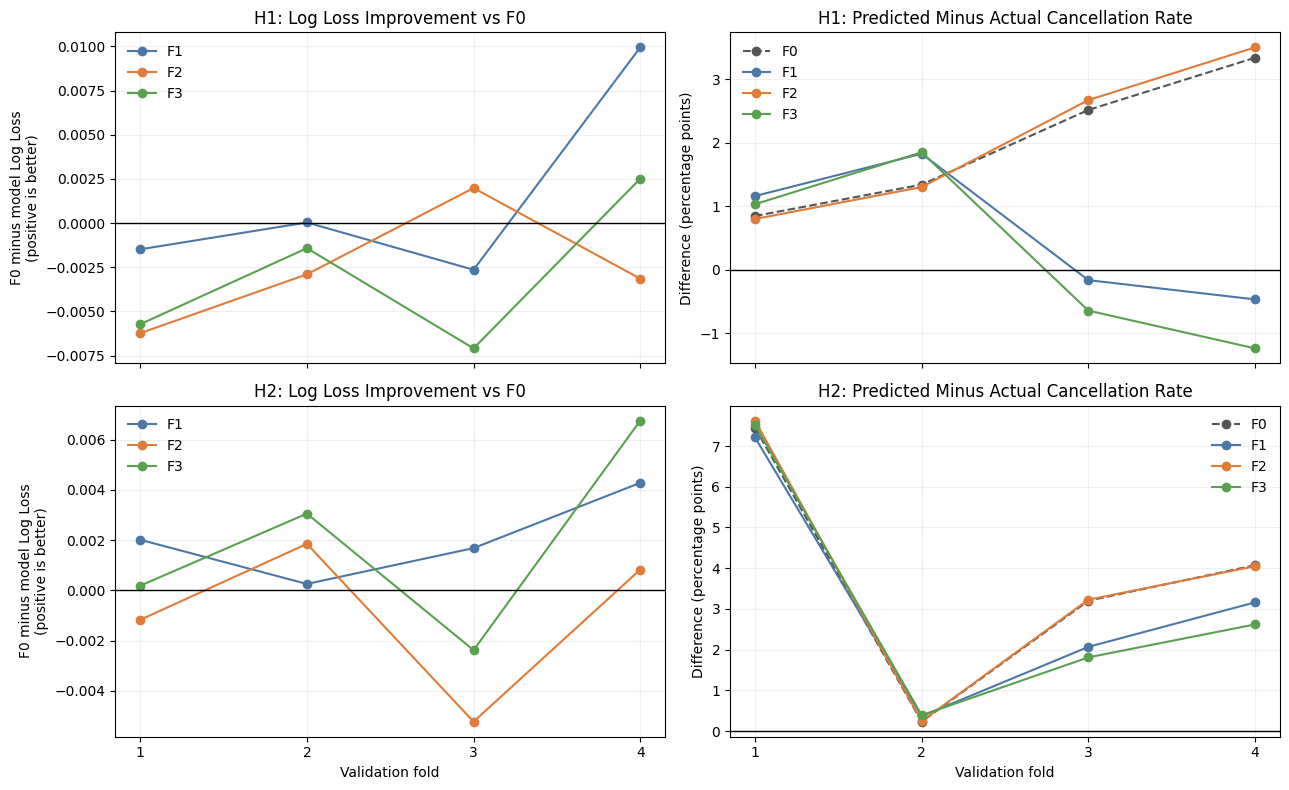

In [56]:
# Display same-window gains, cancellation rates and predicted probabilities
display(feature_metrics[['Hotel', 'FeatureSet', 'Fold', 'ValidationRows', 'ValidationPositives',
    'LogLoss', 'GainVsF0', 'GainVsDummy', 'ValidationCancelRate', 'MeanProbability', 'GeneralizationGap']]
    .style.format({column: '{:.4f}' for column in ['LogLoss', 'GainVsF0', 'GainVsDummy', 'GeneralizationGap']}
        | {'ValidationCancelRate': '{:.1%}', 'MeanProbability': '{:.1%}'}).hide(axis='index'))

# Plot changes in Log Loss and probability bias with the same window definitions
feature_colors = {'F0': '#555555', 'F1': '#4c78a8', 'F2': '#e07b39', 'F3': '#59a14f'}
fig, axes = plt.subplots(2, 2, figsize=(13, 8), sharex=True)
for row, hotel in enumerate(config['hotels']):
    for name in feature_sets:
        panel = feature_metrics.loc[feature_metrics['Hotel'].eq(hotel)
            & feature_metrics['FeatureSet'].eq(name)].sort_values('Fold')
        if name != 'F0':
            axes[row, 0].plot(panel['Fold'], panel['GainVsF0'], '-o',
                color=feature_colors[name], label=name)
        axes[row, 1].plot(panel['Fold'], 100 * panel['ProbabilityBias'],
            '--o' if name == 'F0' else '-o', color=feature_colors[name], label=name)
    axes[row, 0].set(title=f'{hotel}: Log Loss Improvement vs F0',
                     ylabel='F0 minus model Log Loss\n(positive is better)')
    axes[row, 1].set(title=f'{hotel}: Predicted Minus Actual Cancellation Rate',
                     ylabel='Difference (percentage points)')
    for ax in axes[row]:
        ax.axhline(0, color='black', linewidth=1)
        ax.set_xticks([1, 2, 3, 4])
        ax.grid(alpha=0.2)
        ax.legend(frameon=False)
        if row == 1:
            ax.set_xlabel('Validation fold')
fig.tight_layout()
plt.show()

**Observation:**

- **H1:** F1 improves Log Loss in folds 2 and 4, but fold 2 is almost unchanged. Its mean improvement mainly comes from fold 4; folds 1 and 3 worsen, and fold-3 ROC-AUC falls. Late-window mean probabilities move much closer to actual rates, while early-window bias increases.
- **H2:** F1 improves Log Loss over F0 in all four windows and remains better than Dummy throughout. F3 improves over F0 in three windows but worsens fold 3. The mean gain from F1 is therefore more consistent than for H1.
- F1 reduces mean absolute window bias from 2.01 to 0.90 percentage points for H1 and from 3.74 to 3.20 for H2. H2 fold 1 still overpredicts by about 7.2 points. Smaller mean bias and train-validation gaps do not establish that calibration or temporal instability is resolved.

#### 6.7.6 Save Feature Experiment Results

In [57]:
# Save one metrics, OOF, summary and experiment-log table per hotel
feature_report_tables = {}
for hotel in config['hotels']:
    for filename, table in [('fold_metrics.csv', feature_metrics), ('oof_predictions.csv', feature_predictions),
                           ('cv_summary.csv', feature_summary), ('experiment_log.csv', feature_logs)]:
        feature_report_tables[f'{hotel}/{filename}'] = table.loc[table['Hotel'].eq(hotel)].reset_index(drop=True)
feature_schema, feature_contents = {}, {}
for name, table in feature_report_tables.items():
    dates = [c for c in table if pd.api.types.is_datetime64_any_dtype(table[c])]
    feature_schema[name] = {'dtypes': {c: str(t) for c, t in table.dtypes.items()}, 'date_columns': dates}
    feature_contents[name] = table.to_csv(index=False, date_format='%Y-%m-%d', lineterminator='\n').encode('utf-8')
feature_execution_hash = (feature_saved_config['execution_notebook_code_sha256']
    if feature_saved_config is not None else tuning_hash([
        ''.join(c['source']) for c in feature_notebook['cells'] if c['cell_type'] == 'code']))
feature_run_config = {'protocol': feature_protocol, 'execution_notebook_code_sha256': feature_execution_hash,
    'output_schema': feature_schema,
    'output_sha256': {name: hashlib.sha256(contents).hexdigest() for name, contents in feature_contents.items()}}

# Preserve frozen results and verify every new table before publishing the config
feature_save_rows = []
for name, table in feature_report_tables.items():
    destination = feature_directory / name
    destination.parent.mkdir(parents=True, exist_ok=True)
    if destination.exists() and destination.read_bytes() != feature_contents[name]:
        raise FileExistsError(f'{destination} differs; use a new feature_run_id')
    if not destination.exists():
        temporary = destination.with_suffix('.csv.tmp')
        temporary.write_bytes(feature_contents[name])
        temporary.replace(destination)
    restored = read_feature_table(name, feature_run_config)
    pd.testing.assert_frame_equal(table, restored, check_exact=True)
    feature_save_rows.append({'Hotel': name.split('/')[0], 'File': destination.name,
                             'Rows': len(table), 'ReadBack': 'PASS'})
destination = feature_directory / 'run_config.json'
if destination.exists():
    if json.loads(destination.read_text(encoding='utf-8')) != feature_run_config:
        raise FileExistsError('Feature experiment config differs')
else:
    temporary = destination.with_suffix('.json.tmp')
    temporary.write_text(json.dumps(feature_run_config, indent=2) + '\n', encoding='utf-8')
    temporary.replace(destination)
display(pd.DataFrame(feature_save_rows).style.format({'Rows': '{:,}'}).hide(axis='index'))
print('Directory:', feature_directory)

Hotel,File,Rows,ReadBack
H1,fold_metrics.csv,16,PASS
H1,oof_predictions.csv,"24,476",PASS
H1,cv_summary.csv,4,PASS
H1,experiment_log.csv,16,PASS
H2,fold_metrics.csv,16,PASS
H2,oof_predictions.csv,"49,352",PASS
H2,cv_summary.csv,4,PASS
H2,experiment_log.csv,16,PASS


Directory: /workspace/Project/Model pipeline/reports/feature_ablation_round1_v1


**Observation:** `reports/feature_ablation_round1_v1/` saves the full protocol and four tables per hotel: fold metrics, OOF predictions, CV summary and experiment log. All eight tables pass exact read-back checks. Every OOF row carries its FeatureSet and ReferenceConfigID for later comparison.

### 6.8 Probability Calibration

#### 6.8.1 Calibration Data and Protocol

Use earlier temporal OOF predictions whose labels are available before the next fold's fit date. Compare raw, sigmoid and isotonic probabilities on the same validation bookings in folds 2â€“4. H1 uses F1 and the F0 challenger; H2 uses F1. The primary score is the equal-weight mean Log Loss across these three windows.

In [58]:
# Load calibration functions and verify the frozen feature-experiment outputs
from utils import model_calibration
importlib.reload(model_calibration)
calibration_run_id = 'calibration_round1_v1'
calibration_directory = project_root / 'Model pipeline' / 'reports' / calibration_run_id
calibration_candidates = [('H1', 'F1'), ('H1', 'F0'), ('H2', 'F1')]
calibration_methods = ['raw', 'sigmoid', 'isotonic']
calibration_folds = [2, 3, 4]
calibration_source_config = json.loads((feature_directory / 'run_config.json').read_text(encoding='utf-8'))
for name, digest in calibration_source_config['output_sha256'].items():
    if hashlib.sha256((feature_directory / name).read_bytes()).hexdigest() != digest:
        raise AssertionError(f'Calibration source changed: {name}')

# Attach one label-availability date to every saved OOF booking
calibration_sources, calibration_cohorts, calibration_audit_rows = {}, {}, []
for hotel, name in calibration_candidates:
    dates = split_results[hotel]['fit_eligibility'][['Hotel', 'Booking_ID', 'LabelAvailableDate']].drop_duplicates()
    if dates.duplicated(['Hotel', 'Booking_ID']).any():
        raise AssertionError('Conflicting label-availability dates')
    source = feature_predictions.loc[feature_predictions['Hotel'].eq(hotel)
        & feature_predictions['FeatureSet'].eq(name)].merge(dates, on=['Hotel', 'Booking_ID'],
        how='left', validate='one_to_one')
    if source['LabelAvailableDate'].isna().any() or not source['Fold'].isin([1, 2, 3, 4]).all():
        raise AssertionError('OOF dates or fold identifiers are incomplete')
    calibration_sources[(hotel, name)] = source
    for fold in calibration_folds:
        reference = feature_metrics.loc[feature_metrics['Hotel'].eq(hotel)
            & feature_metrics['FeatureSet'].eq(name) & feature_metrics['Fold'].eq(fold)].iloc[0]
        fit_date = pd.Timestamp(reference['FitDate'])
        past = source.loc[source['Fold'].lt(fold)]
        ready = past.loc[past['LabelAvailableDate'].lt(fit_date)].copy()
        valid = source.loc[source['Fold'].eq(fold)].copy()
        if (ready.empty or ready['IsCanceled'].nunique() != 2
                or set(ready['Booking_ID']) & set(valid['Booking_ID'])
                or not ready['PredictionDate'].lt(fit_date).all()
                or not valid['PredictionDate'].ge(fit_date).all()
                or not valid['PredictionDate'].lt(pd.Timestamp(reference['ValidationEnd'])).all()
                or not valid['LabelAvailableDate'].lt(pd.Timestamp(split_config['test_start'])).all()):
            raise AssertionError('Calibration chronology, labels or membership failed')
        calibration_cohorts[(hotel, name, fold)] = (ready, valid, reference)
        calibration_audit_rows.append({'Hotel': hotel, 'FeatureSet': name, 'Fold': fold,
            'FitDate': fit_date, 'EarlierOOFRows': len(past), 'CalibrationRows': len(ready),
            'PendingLabels': len(past) - len(ready), 'CalibrationPositives': int(ready['IsCanceled'].sum()),
            'CalibrationRate': ready['IsCanceled'].mean(), 'ValidationRows': len(valid),
            'ValidationPositives': int(valid['IsCanceled'].sum())})
calibration_audit = pd.DataFrame(calibration_audit_rows)

# Fingerprint the inputs and code used to fit, evaluate and replay this round
calibration_notebook = json.loads((project_root / 'Model pipeline' / 'model_train_main.ipynb').read_text(encoding='utf-8'))
calibration_code = {}
for cell in calibration_notebook['cells']:
    if cell['cell_type'] != 'code':
        continue
    source = ''.join(cell['source'])
    if source.startswith(('# Load calibration functions', '# Fit and evaluate one calibration method',
                          '# Audit all calibration evaluations')):
        calibration_code[source.splitlines()[0]] = ast.dump(ast.parse(source), include_attributes=False)
calibration_protocol = {
    'run_id': calibration_run_id, 'reference_run': feature_run_id,
    'candidates': [list(item) for item in calibration_candidates], 'methods': calibration_methods,
    'evaluation_folds': calibration_folds, 'primary': 'unweighted mean validation LogLoss over folds 2-4',
    'calibration_rule': 'OOF Fold < evaluation Fold and LabelAvailableDate < FitDate',
    'sigmoid': 'Platt-smoothed targets on raw probabilities; p=expit(-(a*raw+b))',
    'isotonic': 'nondecreasing; out-of-bounds clip; no extra probability clipping',
    'metric_probability_clipping': 'existing sklearn float64 machine epsilon for LogLoss',
    'expected_evaluations': 27, 'expected_calibrator_fits': 18, 'new_base_model_fits': 0,
    'split_config': split_config, 'environment': tuning_environment,
    'reference_config_sha256': hashlib.sha256((feature_directory / 'run_config.json').read_bytes()).hexdigest(),
    'source_oof_sha256': {f'{h}/{n}': tuning_frame_hash(t) for (h, n), t in calibration_sources.items()},
    'code_sha256': {name: hashlib.sha256((project_root / 'Model pipeline' / 'utils' / name).read_bytes()).hexdigest()
                    for name in ['model_calibration.py', 'model_evaluation.py']},
    'notebook_methods_sha256': tuning_hash(calibration_code),
}
calibration_saved_config, calibration_saved_tables = None, {}
if (calibration_directory / 'run_config.json').exists():
    calibration_saved_config = json.loads((calibration_directory / 'run_config.json').read_text(encoding='utf-8'))
    if calibration_saved_config['protocol'] != calibration_protocol:
        raise FileExistsError('Calibration conditions changed; use a new calibration_run_id')
    for name, digest in calibration_saved_config['output_sha256'].items():
        if hashlib.sha256((calibration_directory / name).read_bytes()).hexdigest() != digest:
            raise AssertionError(f'Calibration artifact changed: {name}')
        schema = calibration_saved_config['output_schema'][name]
        table = pd.read_csv(calibration_directory / name, float_precision='round_trip', keep_default_na=False,
            dtype={c: t for c, t in schema['dtypes'].items() if c not in schema['date_columns']},
            parse_dates=schema['date_columns'])
        for column in schema['date_columns']:
            table[column] = table[column].astype(schema['dtypes'][column])
        calibration_saved_tables[name] = table

display(calibration_audit.style.format({'CalibrationRate': '{:.1%}'}).hide(axis='index'))
print('27 evaluations | 18 calibrator fits | 0 new RF fits')

Hotel,FeatureSet,Fold,FitDate,EarlierOOFRows,CalibrationRows,PendingLabels,CalibrationPositives,CalibrationRate,ValidationRows,ValidationPositives
H1,F1,2,2016-09-01 00:00:00,1779,1277,502,101,7.9%,1936,112
H1,F1,3,2016-11-01 00:00:00,3715,3214,501,221,6.9%,1152,114
H1,F1,4,2017-01-01 00:00:00,4867,4554,313,331,7.3%,1252,119
H1,F0,2,2016-09-01 00:00:00,1779,1277,502,101,7.9%,1936,112
H1,F0,3,2016-11-01 00:00:00,3715,3214,501,221,6.9%,1152,114
H1,F0,4,2017-01-01 00:00:00,4867,4554,313,331,7.3%,1252,119
H2,F1,2,2016-09-01 00:00:00,3805,2774,1031,281,10.1%,3958,534
H2,F1,3,2016-11-01 00:00:00,7763,6881,882,796,11.6%,2216,293
H2,F1,4,2017-01-01 00:00:00,9979,9417,562,1114,11.8%,2359,274


27 evaluations | 18 calibrator fits | 0 new RF fits


**Observation:** The first calibration fits have 1,277 bookings / 101 cancellations for H1 and 2,774 / 281 for H2. More earlier OOF bookings become eligible in later folds. H1 F0 and F1 use identical calibration memberships; their RF scores differ.

#### 6.8.2 Fit Calibrators and Evaluate Future Windows

In [59]:
# Fit and evaluate one calibration method on a fixed temporal OOF cohort
def run_calibration_fold(hotel, name, fold, method):
    started = perf_counter()
    ready, valid, reference = calibration_cohorts[(hotel, name, fold)]
    state = {} if method == 'raw' else model_calibration.fit_calibrator(
        ready['RawProbability'], ready['IsCanceled'], method)
    probabilities = (valid['RawProbability'].to_numpy(dtype=float) if method == 'raw'
                     else model_calibration.apply_calibrator(state, valid['RawProbability']))
    scores = model_evaluation.evaluate_predictions(valid['IsCanceled'], probabilities)
    if method == 'raw' and not all(np.isclose(scores[m], reference[m], rtol=0, atol=tuning_tolerance)
                                   for m in metric_columns):
        raise AssertionError('Raw calibration reference does not reproduce feature-round metrics')
    row = {'Hotel': hotel, 'FeatureSet': name, 'Fold': fold, 'Method': method,
        'FitDate': pd.Timestamp(reference['FitDate']),
        'ValidationStart': pd.Timestamp(reference['ValidationStart']),
        'ValidationEnd': pd.Timestamp(reference['ValidationEnd']),
        'ValidationRows': scores['Rows'], 'ValidationPositives': scores['Positives'],
        'ValidationCancelRate': scores['CancelRate'],
        **{metric: scores[metric] for metric in metric_columns},
        'RawLogLoss': reference['LogLoss'], 'DummyLogLoss': reference['DummyLogLoss'],
        'GainVsRaw': reference['LogLoss'] - scores['LogLoss'],
        'GainVsDummy': reference['DummyLogLoss'] - scores['LogLoss'],
        'MeanProbability': float(probabilities.mean()),
        'ProbabilityBias': float(probabilities.mean() - scores['CancelRate']),
        'MinimumProbability': float(probabilities.min()), 'MaximumProbability': float(probabilities.max()),
        'ExactZeroRows': int((probabilities == 0).sum()), 'ExactOneRows': int((probabilities == 1).sum()),
        'UniqueProbabilities': len(np.unique(probabilities))}
    predictions = valid[['Hotel', 'Booking_ID', 'FeatureSet', 'Fold', 'PredictionDate',
                         'IsCanceled', 'RawProbability']].copy()
    predictions['Method'], predictions['Probability'] = method, probabilities
    log = {'Hotel': hotel, 'FeatureSet': name, 'Fold': fold, 'Method': method,
        'FitDate': row['FitDate'], 'Source': 'raw_reuse' if method == 'raw' else 'new_calibrator_fit',
        'CalibrationRows': 0 if method == 'raw' else len(ready),
        'CalibrationPositives': 0 if method == 'raw' else int(ready['IsCanceled'].sum()),
        'CalibrationInputSHA256': tuning_frame_hash(ready),
        'ValidationInputSHA256': tuning_frame_hash(valid), 'State': tuning_json(state),
        'Status': 'PASS', 'EvaluationSeconds': perf_counter() - started}
    return row, predictions, log


# Prototype one sigmoid fit and reuse it in the complete round
calibration_prototype, calibration_results = {}, []
if calibration_saved_config is None:
    key = ('H1', 'F1', 2, 'sigmoid')
    calibration_prototype[key] = run_calibration_fold(*key)
    display(pd.DataFrame([calibration_prototype[key][0]])[
        ['Hotel', 'FeatureSet', 'Fold', 'Method', 'ValidationRows'] + metric_columns].style.hide(axis='index'))

# Restore a verified round or evaluate the declared candidates and methods
if calibration_saved_config is None:
    for hotel, name in calibration_candidates:
        for fold in calibration_folds:
            for method in calibration_methods:
                key = (hotel, name, fold, method)
                calibration_results.append(calibration_prototype.pop(key) if key in calibration_prototype
                                           else run_calibration_fold(*key))
        print(f'{hotel} {name}: nine evaluations passed', flush=True)
    calibration_metrics = pd.DataFrame([result[0] for result in calibration_results])
    calibration_predictions = pd.concat([result[1] for result in calibration_results], ignore_index=True)
    calibration_logs = pd.DataFrame([result[2] for result in calibration_results])
else:
    calibration_metrics = calibration_saved_tables['fold_metrics.csv'].copy()
    calibration_predictions = calibration_saved_tables['oof_predictions.csv'].copy()
    calibration_logs = calibration_saved_tables['experiment_log.csv'].copy()
    print('Restored 27 verified calibration evaluations without refitting')

Restored 27 verified calibration evaluations without refitting


**Observation:** All 27 evaluations pass the membership and probability checks. The round fits 18 calibrators and reuses nine raw RF evaluations; no new RF models are fitted.

#### 6.8.3 Raw vs Calibrated Results

Compare the three methods on folds 2â€“4 only. Positive Log Loss gain means improvement over the same-window reference. Pooled OOF Log Loss is recorded separately from the primary equal-weight fold mean.

In [60]:
# Audit all calibration evaluations and replay their saved mappings
calibration_metrics = calibration_metrics.sort_values(['Hotel', 'FeatureSet', 'Method', 'Fold']).reset_index(drop=True)
calibration_predictions = calibration_predictions.sort_values(
    ['Hotel', 'FeatureSet', 'Method', 'Fold', 'Booking_ID']).reset_index(drop=True)
calibration_logs = calibration_logs.sort_values(['Hotel', 'FeatureSet', 'Method', 'Fold']).reset_index(drop=True)
if (len(calibration_metrics) != 27 or len(calibration_logs) != 27
        or calibration_metrics.duplicated(['Hotel', 'FeatureSet', 'Fold', 'Method']).any()
        or calibration_predictions.duplicated(['Hotel', 'FeatureSet', 'Booking_ID', 'Method']).any()
        or calibration_logs['Source'].value_counts().to_dict() != {'new_calibrator_fit': 18, 'raw_reuse': 9}
        or not calibration_logs['Status'].eq('PASS').all()):
    raise AssertionError('Calibration evaluation counts or keys differ from the protocol')
for record in calibration_metrics.to_dict('records'):
    hotel, name, fold, method = (record[c] for c in ['Hotel', 'FeatureSet', 'Fold', 'Method'])
    ready, valid, reference = calibration_cohorts[(hotel, name, fold)]
    observed = calibration_predictions.loc[calibration_predictions['Hotel'].eq(hotel)
        & calibration_predictions['FeatureSet'].eq(name) & calibration_predictions['Fold'].eq(fold)
        & calibration_predictions['Method'].eq(method)]
    aligned = valid.merge(observed, on=['Hotel', 'Booking_ID'], how='outer', validate='one_to_one',
                         suffixes=('_source', ''), indicator=True)
    if (not aligned['_merge'].eq('both').all()
            or not all(aligned[c].eq(aligned[f'{c}_source']).all() for c in
                       ['Fold', 'FeatureSet', 'IsCanceled', 'PredictionDate', 'RawProbability'])):
        raise AssertionError('Calibration validation membership differs from the raw source')
    log = calibration_logs.loc[calibration_logs['Hotel'].eq(hotel) & calibration_logs['FeatureSet'].eq(name)
        & calibration_logs['Fold'].eq(fold) & calibration_logs['Method'].eq(method)].iloc[0]
    if (log['CalibrationInputSHA256'] != tuning_frame_hash(ready)
            or log['ValidationInputSHA256'] != tuning_frame_hash(valid)):
        raise AssertionError('Calibration input fingerprint changed')
    replay = (aligned['RawProbability'].to_numpy() if method == 'raw' else
              model_calibration.apply_calibrator(json.loads(log['State']), aligned['RawProbability']))
    if not np.allclose(replay, aligned['Probability'], rtol=0, atol=tuning_tolerance):
        raise AssertionError('Calibrator state does not reproduce the saved probabilities')
    scores = model_evaluation.evaluate_predictions(aligned['IsCanceled'], aligned['Probability'])
    if (scores['Rows'] != record['ValidationRows'] or scores['Positives'] != record['ValidationPositives']
            or not all(np.isclose(scores[m], record[m], rtol=0, atol=tuning_tolerance) for m in metric_columns)):
        raise AssertionError('Calibration OOF and metrics do not reconcile')

# Aggregate equal-weight window scores and keep the pooled score separate
calibration_summary_rows = []
for (hotel, name, method), windows in calibration_metrics.groupby(['Hotel', 'FeatureSet', 'Method']):
    if windows['Fold'].tolist() != calibration_folds:
        raise AssertionError('Every comparison requires exactly folds 2-4')
    observed = calibration_predictions.loc[calibration_predictions['Hotel'].eq(hotel)
        & calibration_predictions['FeatureSet'].eq(name) & calibration_predictions['Method'].eq(method)]
    pooled = model_evaluation.evaluate_predictions(observed['IsCanceled'], observed['Probability'])
    if not np.isclose(pooled['LogLoss'], np.average(windows['LogLoss'], weights=windows['ValidationRows']),
                      rtol=0, atol=tuning_tolerance):
        raise AssertionError('Pooled Log Loss does not reconcile with weighted window scores')
    calibration_summary_rows.append({'Hotel': hotel, 'FeatureSet': name, 'Method': method,
        'EvaluationFolds': '2,3,4', 'ValidationRows': int(windows['ValidationRows'].sum()),
        'ValidationPositives': int(windows['ValidationPositives'].sum()),
        **{metric: windows[metric].mean() for metric in metric_columns},
        'RawLogLoss': windows['RawLogLoss'].mean(), 'DummyLogLoss': windows['DummyLogLoss'].mean(),
        'GainVsRaw': windows['GainVsRaw'].mean(), 'GainVsDummy': windows['GainVsDummy'].mean(),
        'FoldsBeatingRaw': int(windows['GainVsRaw'].gt(tuning_tolerance).sum()),
        'FoldsBeatingDummy': int(windows['GainVsDummy'].gt(tuning_tolerance).sum()),
        'MeanAbsoluteWindowBias': windows['ProbabilityBias'].abs().mean(),
        'WorstLogLoss': windows['LogLoss'].max(), 'WorstExcessVsDummy': (-windows['GainVsDummy']).max(),
        'PooledOOFLogLoss': pooled['LogLoss'],
        'ExactZeroRows': int(windows['ExactZeroRows'].sum()), 'ExactOneRows': int(windows['ExactOneRows'].sum())})
calibration_summary = pd.DataFrame(calibration_summary_rows).sort_values(
    ['Hotel', 'FeatureSet', 'LogLoss']).reset_index(drop=True)
display(calibration_summary[['Hotel', 'FeatureSet', 'Method'] + metric_columns +
    ['GainVsRaw', 'FoldsBeatingRaw', 'FoldsBeatingDummy', 'PooledOOFLogLoss']].style.format({
        c: '{:.5f}' for c in metric_columns + ['GainVsRaw', 'PooledOOFLogLoss']}).hide(axis='index'))
display(calibration_metrics[['Hotel', 'FeatureSet', 'Fold', 'Method', 'LogLoss', 'GainVsRaw', 'GainVsDummy',
    'ValidationCancelRate', 'MeanProbability', 'ExactZeroRows', 'ExactOneRows']].style.format({
        'LogLoss': '{:.5f}', 'GainVsRaw': '{:.5f}', 'GainVsDummy': '{:.5f}',
        'ValidationCancelRate': '{:.1%}', 'MeanProbability': '{:.1%}'}).hide(axis='index'))
print(f'PASS: 27 evaluations | 18 calibrator fits | {len(calibration_predictions):,} aligned probability rows')

Hotel,FeatureSet,Method,LogLoss,BrierScore,ROC_AUC,AveragePrecision,GainVsRaw,FoldsBeatingRaw,FoldsBeatingDummy,PooledOOFLogLoss
H1,F0,raw,0.27753,0.07553,0.66166,0.16380,-0.00000,0,3,0.26503
H1,F0,isotonic,0.28207,0.07674,0.65946,0.14579,-0.00453,0,2,0.26942
H1,F0,sigmoid,0.28975,0.08089,0.66166,0.16380,-0.01222,1,2,0.27553
H1,F1,raw,0.27509,0.07480,0.66539,0.16331,0.00000,0,3,0.26285
H1,F1,sigmoid,0.27911,0.07575,0.66539,0.16331,-0.00402,0,3,0.26659
H1,F1,isotonic,0.30380,0.07567,0.66497,0.14838,-0.02871,0,2,0.28821
H2,F1,raw,0.37537,0.10991,0.61162,0.19314,-0.00000,0,3,0.37666
H2,F1,sigmoid,0.37821,0.11049,0.61162,0.19314,-0.00283,1,3,0.38129
H2,F1,isotonic,0.40589,0.11060,0.60496,0.17232,-0.03052,1,2,0.41987


Hotel,FeatureSet,Fold,Method,LogLoss,GainVsRaw,GainVsDummy,ValidationCancelRate,MeanProbability,ExactZeroRows,ExactOneRows
H1,F0,2,isotonic,0.20709,-0.00365,0.01749,5.8%,7.7%,40,0
H1,F0,3,isotonic,0.31822,-0.00488,0.00773,9.9%,13.8%,7,0
H1,F0,4,isotonic,0.32088,-0.00506,-0.00477,9.5%,13.2%,1,0
H1,F0,2,raw,0.20344,0.00000,0.02114,5.8%,7.1%,0,0
H1,F0,3,raw,0.31334,0.00000,0.01262,9.9%,12.4%,0,0
H1,F0,4,raw,0.31582,-0.00000,0.00029,9.5%,12.8%,0,0
H1,F0,2,sigmoid,0.20803,-0.00459,0.01655,5.8%,7.7%,0,0
H1,F0,3,sigmoid,0.34820,-0.03486,-0.02225,9.9%,16.0%,0,0
H1,F0,4,sigmoid,0.31301,0.00280,0.00309,9.5%,11.2%,0,0
H1,F1,2,isotonic,0.20675,-0.00334,0.01783,5.8%,8.3%,50,0


PASS: 27 evaluations | 18 calibrator fits | 51,639 aligned probability rows


**Observation:**

- **H1:** Raw F1 has the lowest mean Log Loss (0.27509), ahead of raw F0 (0.27753), sigmoid F1 (0.27911) and isotonic F1 (0.30380). Neither calibration method improves F1 in any of the three windows; Brier also worsens on average.
- **H2:** Raw F1 remains best (0.37537), followed by sigmoid (0.37821) and isotonic (0.40589). Both methods improve fold 4 but worsen folds 2–3; mean Brier also worsens. Raw and sigmoid beat Dummy in all three windows.
- These means use **folds 2–4 only**. They should not be compared directly with the four-fold means from tuning or ablation. Under this protocol, calibration has not improved the leading candidate's average probability performance.

#### 6.8.4 Calibration by Validation Window

Each panel compares the same bookings. Quantile bins show mean predicted probability against observed cancellation rate; the diagonal represents agreement. Axis ranges adapt to show every bin. Isotonic ties can produce unequal bin sizes.

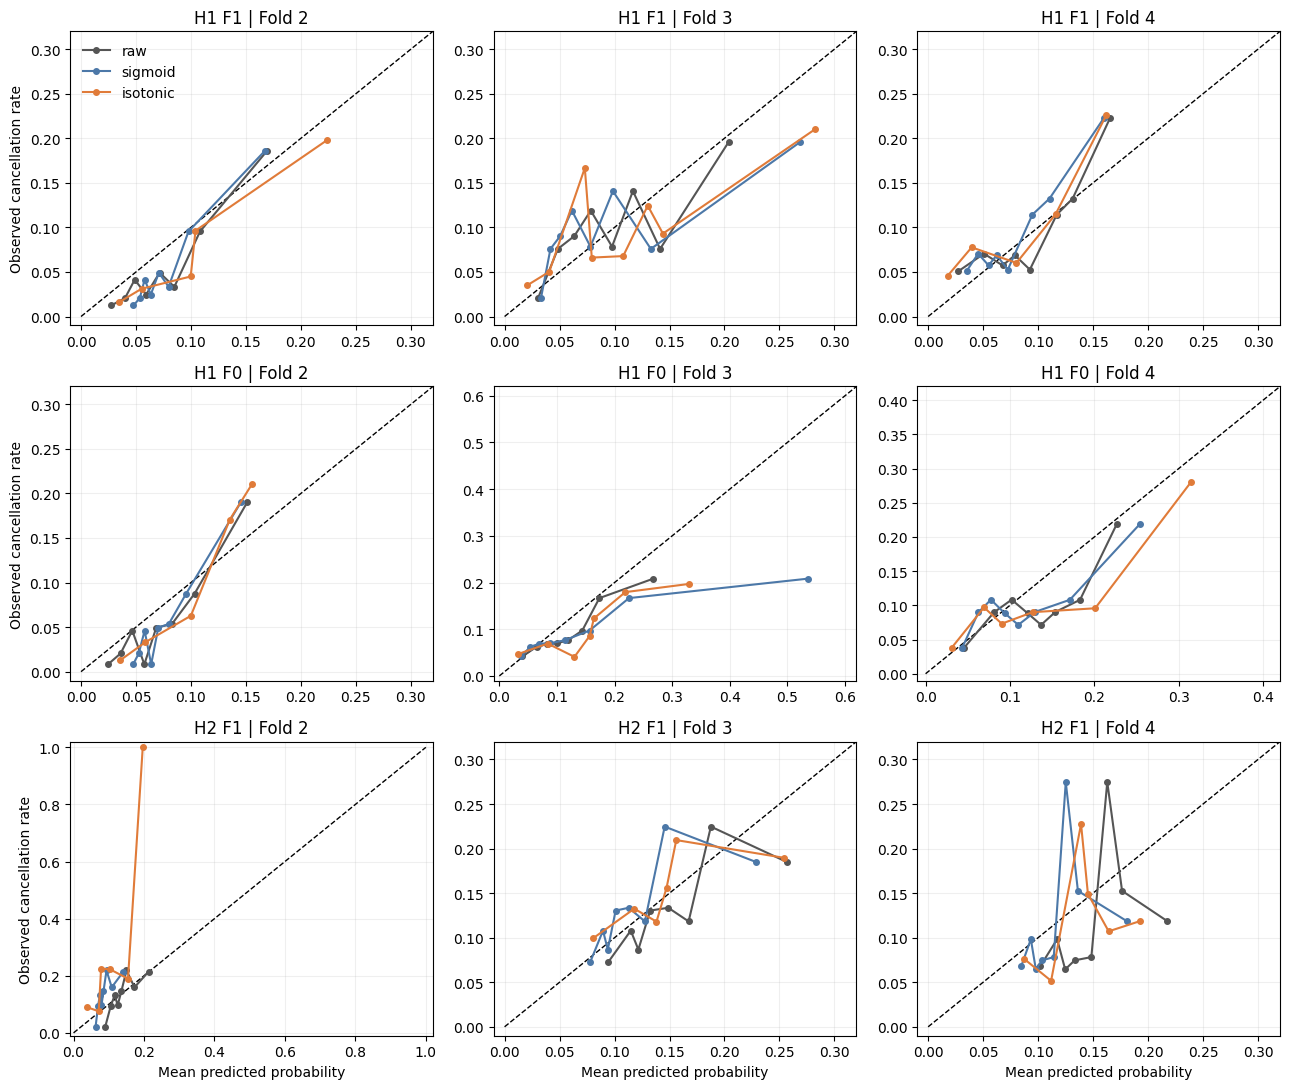

Hotel,FeatureSet,Method,MeanAbsoluteWindowBias,WorstExcessVsDummy,ExactZeroRows,ExactOneRows
H1,F0,raw,2.4%,-0.00029,0,0
H1,F0,isotonic,3.2%,0.00477,48,0
H1,F0,sigmoid,3.2%,0.02225,0,0
H1,F1,raw,0.8%,-0.00997,0,0
H1,F1,sigmoid,1.4%,-0.00254,0,0
H1,F1,isotonic,1.3%,0.07203,131,0
H2,F1,raw,1.9%,-0.00428,0,0
H2,F1,sigmoid,1.9%,-0.00031,0,0
H2,F1,isotonic,2.2%,0.08319,388,0


In [61]:
# Plot probability agreement separately for each candidate and future window
from sklearn.calibration import calibration_curve
calibration_colors = {'raw': '#555555', 'sigmoid': '#4c78a8', 'isotonic': '#e07b39'}
fig, axes = plt.subplots(3, 3, figsize=(13, 11), sharex=False, sharey=False)
for row, (hotel, name) in enumerate(calibration_candidates):
    for column, fold in enumerate(calibration_folds):
        ax = axes[row, column]
        ax.plot([0, 1], [0, 1], '--', color='black', linewidth=1)
        panel_limit = 0.3
        for method in calibration_methods:
            panel = calibration_predictions.loc[calibration_predictions['Hotel'].eq(hotel)
                & calibration_predictions['FeatureSet'].eq(name) & calibration_predictions['Fold'].eq(fold)
                & calibration_predictions['Method'].eq(method)]
            actual, predicted = calibration_curve(panel['IsCanceled'], panel['Probability'],
                                                   n_bins=8, strategy='quantile')
            panel_limit = max(panel_limit, predicted.max(), actual.max())
            ax.plot(predicted, actual, '-o', markersize=4, color=calibration_colors[method], label=method)
        panel_limit = min(1.02, np.ceil(panel_limit * 10) / 10 + 0.02)
        ax.set(title=f'{hotel} {name} | Fold {fold}',
               xlim=(-0.01, panel_limit), ylim=(-0.01, panel_limit))
        ax.grid(alpha=0.2)
        if column == 0:
            ax.set_ylabel('Observed cancellation rate')
        if row == 2:
            ax.set_xlabel('Mean predicted probability')
        if row == 0 and column == 0:
            ax.legend(frameon=False)
fig.tight_layout()
plt.show()

# Show bias and boundary probabilities beside the reliability plots
display(calibration_summary[['Hotel', 'FeatureSet', 'Method', 'MeanAbsoluteWindowBias',
    'WorstExcessVsDummy', 'ExactZeroRows', 'ExactOneRows']].style.format({
        'MeanAbsoluteWindowBias': '{:.1%}', 'WorstExcessVsDummy': '{:.5f}'}).hide(axis='index'))

**Observation:**

- H2 fold 2 illustrates the risk of transferring a calibration mapping through time: raw predicts 13.9% cancellations against 13.5% observed, while sigmoid reduces this to 8.9% and isotonic to 8.2%. The historical correction overshoots in this window.
- Isotonic assigns probability 0 to 51 H1 F1 bookings in fold 4, including three cancellations, and 363 H2 bookings in fold 2, including ten cancellations. These confident errors strongly penalize Log Loss. The 100% observed-rate bin in H2 fold 2 contains only two bookings. A smoother-looking calibration curve or improved mean rate alone does not guarantee better individual probabilities.
- Sigmoid preserves ROC-AUC and AP here; isotonic creates ties and lowers mean AP for each candidate. Fold 1 has no calibration evaluation because there is no earlier OOF calibration history.

#### 6.8.5 Save Calibration Results

In [62]:
# Save the metrics, predictions, summary, membership audit and fitted mappings
calibration_tables = {'fold_metrics.csv': calibration_metrics, 'oof_predictions.csv': calibration_predictions,
    'cv_summary.csv': calibration_summary, 'experiment_log.csv': calibration_logs,
    'calibration_audit.csv': calibration_audit}
calibration_schema, calibration_contents = {}, {}
for name, table in calibration_tables.items():
    dates = [c for c in table if pd.api.types.is_datetime64_any_dtype(table[c])]
    calibration_schema[name] = {'dtypes': {c: str(t) for c, t in table.dtypes.items()}, 'date_columns': dates}
    calibration_contents[name] = table.to_csv(index=False, date_format='%Y-%m-%d', lineterminator='\n').encode('utf-8')
calibration_run_config = {'protocol': calibration_protocol, 'output_schema': calibration_schema,
    'output_sha256': {name: hashlib.sha256(data).hexdigest() for name, data in calibration_contents.items()}}
calibration_directory.mkdir(parents=True, exist_ok=True)
for name, table in calibration_tables.items():
    destination = calibration_directory / name
    if destination.exists() and destination.read_bytes() != calibration_contents[name]:
        raise FileExistsError(f'{name} differs; use a new calibration_run_id')
    if not destination.exists():
        temporary = destination.with_suffix('.csv.tmp')
        temporary.write_bytes(calibration_contents[name])
        temporary.replace(destination)
    schema = calibration_schema[name]
    restored = pd.read_csv(destination, float_precision='round_trip', keep_default_na=False,
        dtype={c: t for c, t in schema['dtypes'].items() if c not in schema['date_columns']},
        parse_dates=schema['date_columns'])
    for column in schema['date_columns']:
        restored[column] = restored[column].astype(schema['dtypes'][column])
    pd.testing.assert_frame_equal(table, restored, check_exact=True)
destination = calibration_directory / 'run_config.json'
if destination.exists():
    if json.loads(destination.read_text(encoding='utf-8')) != calibration_run_config:
        raise FileExistsError('Calibration config differs')
else:
    temporary = destination.with_suffix('.json.tmp')
    temporary.write_text(json.dumps(calibration_run_config, indent=2) + '\n', encoding='utf-8')
    temporary.replace(destination)
display(pd.DataFrame([{'File': name, 'Rows': len(table), 'ReadBack': 'PASS'}
    for name, table in calibration_tables.items()]).style.hide(axis='index'))
print('Directory:', calibration_directory)

File,Rows,ReadBack
fold_metrics.csv,27,PASS
oof_predictions.csv,51639,PASS
cv_summary.csv,9,PASS
experiment_log.csv,27,PASS
calibration_audit.csv,9,PASS


Directory: /workspace/Project/Model pipeline/reports/calibration_round1_v1


**Observation:** All five report tables pass exact read-back checks in `reports/calibration_round1_v1/`. The experiment log includes each fitted mapping for replay. Final RF refitting, final calibrator fitting and Test evaluation have not been run.